In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
# ================================================================
# STEP 1 — DISCOVER ACTUAL KAGGLE INPUT PATHS
# ================================================================

import os

print("=" * 70)
print("ALL KAGGLE INPUT DATASETS")
print("=" * 70)

for item in sorted(os.listdir("/kaggle/input")):

    full_path = os.path.join(
        "/kaggle/input",
        item
    )

    print(
        f"{item:<50} -> "
        f"{'DIRECTORY' if os.path.isdir(full_path) else 'FILE'}"
    )


print("\n")
print("=" * 70)
print("COMPLETE KAGGLE INPUT TREE")
print("=" * 70)

for root, dirs, files in os.walk("/kaggle/input"):

    level = root.replace(
        "/kaggle/input",
        ""
    ).count(os.sep)

    indent = "    " * level

    print(
        f"{indent}{os.path.basename(root)}/"
    )

    for file in sorted(files):

        print(
            f"{indent}    {file}"
        )


print("\n")
print("=" * 70)
print("STEP 1 COMPLETE")
print("=" * 70)

ALL KAGGLE INPUT DATASETS
competitions                                       -> DIRECTORY
datasets                                           -> DIRECTORY


COMPLETE KAGGLE INPUT TREE
input/
    competitions/
        aptos2019-blindness-detection/
            sample_submission.csv
            test.csv
            train.csv
            train_images/
                000c1434d8d7.png
                001639a390f0.png
                0024cdab0c1e.png
                002c21358ce6.png
                005b95c28852.png
                0083ee8054ee.png
                0097f532ac9f.png
                00a8624548a9.png
                00b74780d31d.png
                00cb6555d108.png
                00cc2b75cddd.png
                00e4ddff966a.png
                00f6c1be5a33.png
                0104b032c141.png
                0124dffecf29.png
                0125fbd2e791.png
                012a242ac6ff.png
                014508ccb9cb.png
                0151781fe50b.png
                0161338

In [2]:
# ================================================================
# STEP 2 — VERIFY SPLITS, IMAGES AND IMAGENET WEIGHTS
# ================================================================

import os
import pandas as pd


# ================================================================
# 1. EXACT PATHS
# ================================================================

APTOS_ROOT = (
    "/kaggle/input/competitions/"
    "aptos2019-blindness-detection"
)

IMAGE_DIR = os.path.join(
    APTOS_ROOT,
    "train_images"
)

SPLIT_ROOT = (
    "/kaggle/input/datasets/"
    "dharshini2362005/taptos"
)

WEIGHTS_ROOT = (
    "/kaggle/input/datasets/"
    "dharshini2362005/net-weights"
)


TRAIN_CSV = os.path.join(
    SPLIT_ROOT,
    "train_split.csv"
)

VAL_CSV = os.path.join(
    SPLIT_ROOT,
    "val_split.csv"
)

TEST_CSV = os.path.join(
    SPLIT_ROOT,
    "test_split.csv"
)


WEIGHT_FILES = {

    "ResNet18":
        "resnet18-f37072fd.pth",

    "EfficientNet-B0":
        "efficientnet_b0_rwightman-7f5810bc.pth",

    "DenseNet121":
        "densenet121-a639ec97.pth",

    "MobileNetV3-Large":
        "mobilenet_v3_large-5c1a4163.pth"
}


# ================================================================
# 2. VERIFY PATHS
# ================================================================

print("=" * 70)
print("PATH VERIFICATION")
print("=" * 70)

required_paths = {

    "APTOS root":
        APTOS_ROOT,

    "APTOS images":
        IMAGE_DIR,

    "Train split":
        TRAIN_CSV,

    "Validation split":
        VAL_CSV,

    "Test split":
        TEST_CSV,

    "ImageNet weights":
        WEIGHTS_ROOT
}


for name, path in required_paths.items():

    status = (
        "FOUND ✓"
        if os.path.exists(path)
        else "MISSING ✗"
    )

    print(
        f"{name:<25} : {status}"
    )

    if not os.path.exists(path):

        print(
            "   Path:",
            path
        )


# ================================================================
# 3. VERIFY IMAGE COUNT
# ================================================================

print("\n")
print("=" * 70)
print("APTOS IMAGE COUNT")
print("=" * 70)

image_files = [

    f for f in os.listdir(
        IMAGE_DIR
    )

    if f.lower().endswith(
        ".png"
    )
]

print(
    "PNG images found:",
    len(image_files)
)

assert len(image_files) == 3662, (
    f"Expected 3662 images, "
    f"found {len(image_files)}"
)

print(
    "✓ All 3662 APTOS training images found"
)


# ================================================================
# 4. LOAD SPLIT FILES
# ================================================================

train_df = pd.read_csv(
    TRAIN_CSV
)

val_df = pd.read_csv(
    VAL_CSV
)

test_df = pd.read_csv(
    TEST_CSV
)


print("\n")
print("=" * 70)
print("SPLIT SIZES")
print("=" * 70)

print(
    "Train      :",
    len(train_df)
)

print(
    "Validation :",
    len(val_df)
)

print(
    "Test       :",
    len(test_df)
)

assert len(train_df) == 2563
assert len(val_df) == 549
assert len(test_df) == 550

print(
    "\n✓ Expected 2563 / 549 / 550 split confirmed"
)


# ================================================================
# 5. SHOW COLUMN NAMES
# ================================================================

print("\n")
print("=" * 70)
print("CSV COLUMNS")
print("=" * 70)

print(
    "Train columns:",
    train_df.columns.tolist()
)

print(
    "Validation columns:",
    val_df.columns.tolist()
)

print(
    "Test columns:",
    test_df.columns.tolist()
)


# ================================================================
# 6. CLASS DISTRIBUTION
# ================================================================

print("\n")
print("=" * 70)
print("CLASS DISTRIBUTION")
print("=" * 70)

print(
    "\nTRAIN:"
)

print(
    train_df[
        "diagnosis"
    ].value_counts().sort_index()
)

print(
    "\nVALIDATION:"
)

print(
    val_df[
        "diagnosis"
    ].value_counts().sort_index()
)

print(
    "\nTEST:"
)

print(
    test_df[
        "diagnosis"
    ].value_counts().sort_index()
)


# ================================================================
# 7. VERIFY WEIGHTS
# ================================================================

print("\n")
print("=" * 70)
print("IMAGENET WEIGHTS")
print("=" * 70)

for model_name, filename in WEIGHT_FILES.items():

    path = os.path.join(
        WEIGHTS_ROOT,
        filename
    )

    exists = os.path.exists(
        path
    )

    size_mb = (
        os.path.getsize(path)
        / (1024 ** 2)
        if exists
        else 0
    )

    print(
        f"{model_name:<22} : "
        f"{'FOUND ✓' if exists else 'MISSING ✗'}"
        f"   {size_mb:.2f} MB"
    )

    assert exists, (
        f"Missing weight file: {path}"
    )


# ================================================================
# 8. FINAL STATUS
# ================================================================

print("\n")
print("=" * 70)
print("STEP 2 COMPLETE")
print("=" * 70)

print("✓ APTOS dataset verified")
print("✓ 3662 images verified")
print("✓ Train split = 2563")
print("✓ Validation split = 549")
print("✓ Test split = 550")
print("✓ ImageNet weights verified")
print("✓ Five-class diagnosis structure verified")

PATH VERIFICATION
APTOS root                : FOUND ✓
APTOS images              : FOUND ✓
Train split               : FOUND ✓
Validation split          : FOUND ✓
Test split                : FOUND ✓
ImageNet weights          : FOUND ✓


APTOS IMAGE COUNT
PNG images found: 3662
✓ All 3662 APTOS training images found


SPLIT SIZES
Train      : 2563
Validation : 549
Test       : 550

✓ Expected 2563 / 549 / 550 split confirmed


CSV COLUMNS
Train columns: ['id_code', 'diagnosis']
Validation columns: ['id_code', 'diagnosis']
Test columns: ['id_code', 'diagnosis']


CLASS DISTRIBUTION

TRAIN:
diagnosis
0    1263
1     259
2     699
3     135
4     207
Name: count, dtype: int64

VALIDATION:
diagnosis
0    271
1     55
2    150
3     29
4     44
Name: count, dtype: int64

TEST:
diagnosis
0    271
1     56
2    150
3     29
4     44
Name: count, dtype: int64


IMAGENET WEIGHTS
ResNet18               : FOUND ✓   44.66 MB
EfficientNet-B0        : FOUND ✓   20.45 MB
DenseNet121            : FOUND 

In [3]:
# ================================================================
# STEP 3 — BEN GRAHAM PREPROCESSING
#              + 384x384 ADVANCED FUNDUS TRANSFORM
# ================================================================

import cv2
import numpy as np
import torch

from PIL import Image
from torchvision import transforms


# ================================================================
# 1. CONFIGURATION
# ================================================================

IMAGE_SIZE = 384

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]


# ================================================================
# 2. BEN GRAHAM PREPROCESSING
# ================================================================

def ben_graham_preprocessing(
    image,
    sigmaX=10
):
    """
    Ben Graham-style illumination normalization
    for retinal fundus images.

    Pipeline:

    Original RGB image
            ↓
    Gaussian illumination estimate
            ↓
    Illumination correction
            ↓
    Clipping to [0,255]
            ↓
    PIL RGB image
    """

    # Ensure RGB
    if isinstance(image, Image.Image):

        image = image.convert("RGB")

        image = np.array(
            image
        )

    else:

        image = np.asarray(
            image
        )

    # Ensure uint8
    if image.dtype != np.uint8:

        image = np.clip(
            image,
            0,
            255
        ).astype(
            np.uint8
        )

    # Gaussian blur
    blurred = cv2.GaussianBlur(
        image,
        (0, 0),
        sigmaX=sigmaX
    )

    # Ben Graham-style illumination correction
    processed = cv2.addWeighted(
        image,
        4.0,
        blurred,
        -4.0,
        128
    )

    # Safety clipping
    processed = np.clip(
        processed,
        0,
        255
    ).astype(
        np.uint8
    )

    return Image.fromarray(
        processed
    )


# ================================================================
# 3. TRAINING TRANSFORM
# ================================================================

train_transform = transforms.Compose([

    # 384 x 384
    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    # Geometric augmentation
    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=15
    ),

    transforms.RandomAffine(
        degrees=0,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05)
    ),

    # Mild photometric augmentation
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10,
        hue=0.02
    ),

    # Convert to tensor
    transforms.ToTensor(),

    # ImageNet normalization
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# ================================================================
# 4. VALIDATION / TEST TRANSFORM
# ================================================================

eval_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# ================================================================
# 5. COMPLETE TRANSFORM WRAPPER
# ================================================================

class AdvancedFundusTransform:

    def __init__(
        self,
        train=True
    ):

        self.train = train

        if train:

            self.transform = train_transform

        else:

            self.transform = eval_transform

    def __call__(
        self,
        image
    ):

        # First apply Ben Graham preprocessing
        image = ben_graham_preprocessing(
            image
        )

        # Then resize / augment / normalize
        image = self.transform(
            image
        )

        return image


print("=" * 70)
print("STEP 3 — TRANSFORMATION PIPELINE CREATED")
print("=" * 70)

print("Image size        :", f"{IMAGE_SIZE} × {IMAGE_SIZE}")
print("Ben Graham        : ENABLED")
print("Training augment. : ENABLED")
print("ColorJitter       : ENABLED")
print("Normalization     : ImageNet")
print("Validation augment: DISABLED")
print("Test augmentation : DISABLED")

print("\n✓ Step 3 complete")

STEP 3 — TRANSFORMATION PIPELINE CREATED
Image size        : 384 × 384
Ben Graham        : ENABLED
Training augment. : ENABLED
ColorJitter       : ENABLED
Normalization     : ImageNet
Validation augment: DISABLED
Test augmentation : DISABLED

✓ Step 3 complete


PREPROCESSING SANITY CHECK
Image ID : 38f1901f214a
Path     : /kaggle/input/competitions/aptos2019-blindness-detection/train_images/38f1901f214a.png


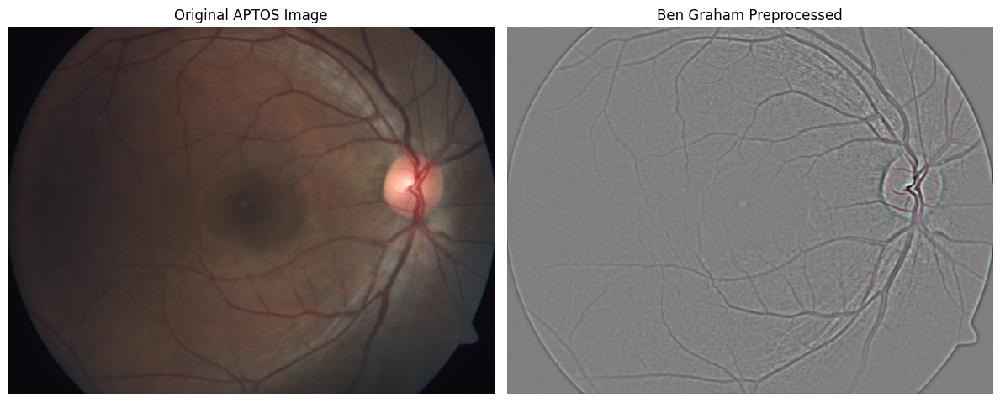


Tensor checks
----------------------------------------------------------------------
Training tensor shape : torch.Size([3, 384, 384])
Evaluation tensor shape: torch.Size([3, 384, 384])
Training tensor dtype : torch.float32
Evaluation tensor dtype: torch.float32
Training tensor min   : -2.1179039478302
Training tensor max   : 2.6051416397094727

✓ Original image loaded
✓ Ben Graham preprocessing works
✓ Training transform works
✓ Evaluation transform works
✓ 384 × 384 confirmed
✓ ImageNet normalization confirmed

STEP 4 COMPLETE


In [4]:
# ================================================================
# STEP 4 — PREPROCESSING SANITY CHECK
# ================================================================

import os
import matplotlib.pyplot as plt


# ------------------------------------------------
# Select one image from the training split
# ------------------------------------------------

sample_id = str(
    train_df.iloc[0]["id_code"]
)

sample_path = os.path.join(
    IMAGE_DIR,
    sample_id + ".png"
)

print("=" * 70)
print("PREPROCESSING SANITY CHECK")
print("=" * 70)

print("Image ID :", sample_id)
print("Path     :", sample_path)

assert os.path.exists(
    sample_path
)

# Original image
original_image = Image.open(
    sample_path
).convert("RGB")

# Ben Graham processed image
processed_image = ben_graham_preprocessing(
    original_image
)

# Apply complete training transform
train_tensor = AdvancedFundusTransform(
    train=True
)(
    original_image
)

# Apply complete evaluation transform
eval_tensor = AdvancedFundusTransform(
    train=False
)(
    original_image
)


# ------------------------------------------------
# Display original vs processed
# ------------------------------------------------

plt.figure(
    figsize=(12, 5)
)

plt.subplot(
    1,
    2,
    1
)

plt.imshow(
    original_image
)

plt.title(
    "Original APTOS Image"
)

plt.axis(
    "off"
)


plt.subplot(
    1,
    2,
    2
)

plt.imshow(
    processed_image
)

plt.title(
    "Ben Graham Preprocessed"
)

plt.axis(
    "off"
)

plt.tight_layout()

plt.show()


# ------------------------------------------------
# Tensor checks
# ------------------------------------------------

print("\nTensor checks")
print("-" * 70)

print(
    "Training tensor shape :",
    train_tensor.shape
)

print(
    "Evaluation tensor shape:",
    eval_tensor.shape
)

print(
    "Training tensor dtype :",
    train_tensor.dtype
)

print(
    "Evaluation tensor dtype:",
    eval_tensor.dtype
)

print(
    "Training tensor min   :",
    train_tensor.min().item()
)

print(
    "Training tensor max   :",
    train_tensor.max().item()
)


# ------------------------------------------------
# Assertions
# ------------------------------------------------

assert train_tensor.shape == (
    3,
    384,
    384
)

assert eval_tensor.shape == (
    3,
    384,
    384
)

assert train_tensor.dtype == torch.float32

assert eval_tensor.dtype == torch.float32


print("\n✓ Original image loaded")
print("✓ Ben Graham preprocessing works")
print("✓ Training transform works")
print("✓ Evaluation transform works")
print("✓ 384 × 384 confirmed")
print("✓ ImageNet normalization confirmed")

print("\nSTEP 4 COMPLETE")

In [5]:
# ================================================================
# STEP 5 — APTOS DATASET + DATALOADERS
# ================================================================

import os
import torch

from PIL import Image
from torch.utils.data import Dataset, DataLoader


# ================================================================
# 1. DATASET CLASS
# ================================================================

class APTOSDataset(Dataset):

    def __init__(
        self,
        dataframe,
        image_dir,
        transform=None
    ):

        self.df = dataframe.reset_index(
            drop=True
        )

        self.image_dir = image_dir
        self.transform = transform


    def __len__(self):

        return len(self.df)


    def __getitem__(
        self,
        index
    ):

        row = self.df.iloc[index]

        image_id = str(
            row["id_code"]
        )

        label = int(
            row["diagnosis"]
        )

        image_path = os.path.join(
            self.image_dir,
            image_id + ".png"
        )

        if not os.path.exists(
            image_path
        ):

            raise FileNotFoundError(
                f"Image not found:\n{image_path}"
            )

        image = Image.open(
            image_path
        ).convert("RGB")


        # Apply Ben Graham + transforms
        if self.transform is not None:

            image = self.transform(
                image
            )


        return image, label


# ================================================================
# 2. CREATE DATASETS
# ================================================================

train_dataset = APTOSDataset(
    dataframe=train_df,
    image_dir=IMAGE_DIR,
    transform=AdvancedFundusTransform(
        train=True
    )
)


val_dataset = APTOSDataset(
    dataframe=val_df,
    image_dir=IMAGE_DIR,
    transform=AdvancedFundusTransform(
        train=False
    )
)


test_dataset = APTOSDataset(
    dataframe=test_df,
    image_dir=IMAGE_DIR,
    transform=AdvancedFundusTransform(
        train=False
    )
)


# ================================================================
# 3. VERIFY DATASET SIZES
# ================================================================

print("=" * 70)
print("DATASET VERIFICATION")
print("=" * 70)

print(
    "Training dataset   :",
    len(train_dataset)
)

print(
    "Validation dataset :",
    len(val_dataset)
)

print(
    "Test dataset       :",
    len(test_dataset)
)


assert len(train_dataset) == 2563
assert len(val_dataset) == 549
assert len(test_dataset) == 550


# ================================================================
# 4. DATALOADER CONFIGURATION
# ================================================================

BATCH_SIZE = 16

NUM_WORKERS = 2


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)


val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)


test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)


# ================================================================
# 5. DATALOADER INFORMATION
# ================================================================

print("\n")
print("=" * 70)
print("DATALOADER CONFIGURATION")
print("=" * 70)

print(
    "Image size  :",
    f"{IMAGE_SIZE} × {IMAGE_SIZE}"
)

print(
    "Batch size  :",
    BATCH_SIZE
)

print(
    "Num workers :",
    NUM_WORKERS
)

print(
    "Train batches:",
    len(train_loader)
)

print(
    "Val batches  :",
    len(val_loader)
)

print(
    "Test batches :",
    len(test_loader)
)

print("\n✓ Dataset objects created")
print("✓ DataLoaders created")
print("✓ Fixed 2563 / 549 / 550 split preserved")

DATASET VERIFICATION
Training dataset   : 2563
Validation dataset : 549
Test dataset       : 550


DATALOADER CONFIGURATION
Image size  : 384 × 384
Batch size  : 16
Num workers : 2
Train batches: 161
Val batches  : 35
Test batches : 35

✓ Dataset objects created
✓ DataLoaders created
✓ Fixed 2563 / 549 / 550 split preserved


In [6]:
# ================================================================
# STEP 6 — DATALOADER SANITY CHECK
# ================================================================

print("=" * 70)
print("DATALOADER SANITY CHECK")
print("=" * 70)


# ------------------------------------------------
# Get one training batch
# ------------------------------------------------

train_images, train_labels = next(
    iter(train_loader)
)


# ------------------------------------------------
# Get one validation batch
# ------------------------------------------------

val_images, val_labels = next(
    iter(val_loader)
)


# ------------------------------------------------
# Print information
# ------------------------------------------------

print("\nTRAINING BATCH")
print("-" * 70)

print(
    "Image shape :",
    train_images.shape
)

print(
    "Label shape :",
    train_labels.shape
)

print(
    "Image dtype :",
    train_images.dtype
)

print(
    "Label dtype :",
    train_labels.dtype
)

print(
    "Image min   :",
    train_images.min().item()
)

print(
    "Image max   :",
    train_images.max().item()
)

print(
    "Labels      :",
    train_labels.tolist()
)


print("\nVALIDATION BATCH")
print("-" * 70)

print(
    "Image shape :",
    val_images.shape
)

print(
    "Label shape :",
    val_labels.shape
)


# ------------------------------------------------
# Assertions
# ------------------------------------------------

assert train_images.shape == (
    BATCH_SIZE,
    3,
    384,
    384
)

assert val_images.shape == (
    BATCH_SIZE,
    3,
    384,
    384
)

assert train_images.dtype == torch.float32

assert val_images.dtype == torch.float32

assert train_labels.min().item() >= 0
assert train_labels.max().item() <= 4

assert val_labels.min().item() >= 0
assert val_labels.max().item() <= 4


print("\n")
print("=" * 70)
print("✓ 384 × 384 BATCH CONFIRMED")
print("✓ RGB 3-CHANNEL INPUT CONFIRMED")
print("✓ BATCH SIZE 16 CONFIRMED")
print("✓ TRAIN LABELS 0–4 CONFIRMED")
print("✓ VALIDATION LABELS 0–4 CONFIRMED")
print("✓ FLOAT32 TENSORS CONFIRMED")
print("=" * 70)

print("\nSTEP 6 COMPLETE")

DATALOADER SANITY CHECK

TRAINING BATCH
----------------------------------------------------------------------
Image shape : torch.Size([16, 3, 384, 384])
Label shape : torch.Size([16])
Image dtype : torch.float32
Label dtype : torch.int64
Image min   : -2.1179039478302
Image max   : 2.640000104904175
Labels      : [2, 0, 0, 0, 4, 0, 2, 2, 2, 0, 0, 2, 0, 1, 2, 3]

VALIDATION BATCH
----------------------------------------------------------------------
Image shape : torch.Size([16, 3, 384, 384])
Label shape : torch.Size([16])


✓ 384 × 384 BATCH CONFIRMED
✓ RGB 3-CHANNEL INPUT CONFIRMED
✓ BATCH SIZE 16 CONFIRMED
✓ TRAIN LABELS 0–4 CONFIRMED
✓ VALIDATION LABELS 0–4 CONFIRMED
✓ FLOAT32 TENSORS CONFIRMED

STEP 6 COMPLETE


In [7]:
# ================================================================
# STEP 7 — FOCAL LOSS + TRAINING CONFIGURATION
# ================================================================

import os
import json
import torch
import torch.nn as nn
import torch.nn.functional as F


# ================================================================
# 1. PROJECT DIRECTORIES
# ================================================================

PROJECT_ROOT = "/kaggle/working/DR_XAI_Project"

CHECKPOINT_ROOT = os.path.join(
    PROJECT_ROOT,
    "checkpoints"
)

RESULTS_ROOT = os.path.join(
    PROJECT_ROOT,
    "results"
)

LOG_ROOT = os.path.join(
    PROJECT_ROOT,
    "logs"
)

CONFIG_ROOT = os.path.join(
    PROJECT_ROOT,
    "configs"
)

for directory in [
    CHECKPOINT_ROOT,
    RESULTS_ROOT,
    LOG_ROOT,
    CONFIG_ROOT
]:

    os.makedirs(
        directory,
        exist_ok=True
    )


# ================================================================
# 2. DEVICE
# ================================================================

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("=" * 70)
print("DEVICE")
print("=" * 70)

print("Device:", DEVICE)

if DEVICE.type == "cuda":

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "CUDA version:",
        torch.version.cuda
    )

else:

    print(
        "⚠️ CUDA GPU not detected."
    )


# ================================================================
# 3. FOCAL LOSS
# ================================================================

class FocalLoss(nn.Module):

    def __init__(
        self,
        gamma=2.0,
        alpha=None
    ):

        super().__init__()

        self.gamma = gamma

        if alpha is not None:

            self.register_buffer(
                "alpha",
                torch.tensor(
                    alpha,
                    dtype=torch.float32
                )
            )

        else:

            self.alpha = None


    def forward(
        self,
        logits,
        targets
    ):

        log_probs = F.log_softmax(
            logits,
            dim=1
        )

        probs = torch.exp(
            log_probs
        )

        target_log_probs = (
            log_probs
            .gather(
                1,
                targets.unsqueeze(1)
            )
            .squeeze(1)
        )

        target_probs = (
            probs
            .gather(
                1,
                targets.unsqueeze(1)
            )
            .squeeze(1)
        )

        focal_factor = (
            1.0 - target_probs
        ).pow(
            self.gamma
        )

        loss = (
            -focal_factor
            * target_log_probs
        )

        if self.alpha is not None:

            alpha_t = self.alpha[
                targets
            ]

            loss = (
                alpha_t
                * loss
            )

        return loss.mean()


# ================================================================
# 4. LOSS INSTANCE
# ================================================================

criterion = FocalLoss(
    gamma=2.0
)


# ================================================================
# 5. TRAINING CONFIGURATION
# ================================================================

NUM_CLASSES = 5

LEARNING_RATE = 1e-4

WEIGHT_DECAY = 1e-4

MAX_EPOCHS = 20

EARLY_STOPPING_PATIENCE = 5

BATCH_SIZE = 16


training_config = {

    "image_size": IMAGE_SIZE,

    "batch_size": BATCH_SIZE,

    "num_classes": NUM_CLASSES,

    "loss": "FocalLoss",

    "focal_gamma": 2.0,

    "focal_alpha": None,

    "learning_rate": LEARNING_RATE,

    "weight_decay": WEIGHT_DECAY,

    "max_epochs": MAX_EPOCHS,

    "early_stopping_patience":
        EARLY_STOPPING_PATIENCE,

    "ben_graham_preprocessing":
        True,

    "augmentation":
        True,

    "imagenet_normalization":
        True,

    "device":
        str(DEVICE)
}


config_path = os.path.join(
    CONFIG_ROOT,
    "improved_pipeline_config.json"
)

with open(
    config_path,
    "w"
) as f:

    json.dump(
        training_config,
        f,
        indent=4
    )


# ================================================================
# 6. DISPLAY
# ================================================================

print("\n")
print("=" * 70)
print("TRAINING CONFIGURATION")
print("=" * 70)

for key, value in training_config.items():

    print(
        f"{key:<30}: {value}"
    )


print("\n✓ Focal Loss created")
print("✓ gamma = 2.0")
print("✓ No additional class weighting")
print("✓ Configuration saved")
print("\nConfig:", config_path)

DEVICE
Device: cuda
GPU: Tesla T4
CUDA version: 12.8


TRAINING CONFIGURATION
image_size                    : 384
batch_size                    : 16
num_classes                   : 5
loss                          : FocalLoss
focal_gamma                   : 2.0
focal_alpha                   : None
learning_rate                 : 0.0001
weight_decay                  : 0.0001
max_epochs                    : 20
early_stopping_patience       : 5
ben_graham_preprocessing      : True
augmentation                  : True
imagenet_normalization        : True
device                        : cuda

✓ Focal Loss created
✓ gamma = 2.0
✓ No additional class weighting
✓ Configuration saved

Config: /kaggle/working/DR_XAI_Project/configs/improved_pipeline_config.json


In [8]:
# ================================================================
# STEP 8 — CREATE FOUR CNN MODELS
# ================================================================

import torch
import torch.nn as nn
from torchvision import models


# ================================================================
# 1. WEIGHT PATHS
# ================================================================

WEIGHTS_ROOT = (
    "/kaggle/input/datasets/"
    "dharshini2362005/net-weights"
)

WEIGHT_PATHS = {

    "resnet18":
        os.path.join(
            WEIGHTS_ROOT,
            "resnet18-f37072fd.pth"
        ),

    "efficientnet_b0":
        os.path.join(
            WEIGHTS_ROOT,
            "efficientnet_b0_rwightman-7f5810bc.pth"
        ),

    "densenet121":
        os.path.join(
            WEIGHTS_ROOT,
            "densenet121-a639ec97.pth"
        ),

    "mobilenet_v3_large":
        os.path.join(
            WEIGHTS_ROOT,
            "mobilenet_v3_large-5c1a4163.pth"
        )
}


# ================================================================
# 2. LOAD COMPATIBLE WEIGHTS
# ================================================================

def load_compatible_weights(
    model,
    weight_path
):

    print(
        "\nLoading:",
        weight_path
    )

    checkpoint = torch.load(
        weight_path,
        map_location="cpu"
    )

    # Handle possible checkpoint wrappers
    if isinstance(
        checkpoint,
        dict
    ):

        if "state_dict" in checkpoint:

            state_dict = checkpoint[
                "state_dict"
            ]

        elif "model_state_dict" in checkpoint:

            state_dict = checkpoint[
                "model_state_dict"
            ]

        elif "model_state" in checkpoint:

            state_dict = checkpoint[
                "model_state"
            ]

        else:

            state_dict = checkpoint

    else:

        state_dict = checkpoint


    # Remove common prefixes
    cleaned_state_dict = {}

    for key, value in state_dict.items():

        new_key = key

        if new_key.startswith(
            "module."
        ):

            new_key = new_key[
                len("module.") :
            ]

        if new_key.startswith(
            "model."
        ):

            new_key = new_key[
                len("model.") :
            ]

        cleaned_state_dict[
            new_key
        ] = value


    # Only load parameters with
    # matching names AND shapes
    model_state = model.state_dict()

    compatible = {}

    skipped = []

    for key, value in cleaned_state_dict.items():

        if (
            key in model_state
            and model_state[key].shape
            == value.shape
        ):

            compatible[key] = value

        else:

            skipped.append(key)


    result = model.load_state_dict(
        compatible,
        strict=False
    )

    print(
        "Compatible parameters loaded:",
        len(compatible)
    )

    print(
        "Skipped parameters:",
        len(skipped)
    )

    print(
        "Missing model parameters:",
        len(result.missing_keys)
    )

    return model


# ================================================================
# 3. RESNET18
# ================================================================

def create_resnet18():

    model = models.resnet18(
        weights=None
    )

    model = load_compatible_weights(
        model,
        WEIGHT_PATHS[
            "resnet18"
        ]
    )

    model.fc = nn.Linear(
        model.fc.in_features,
        NUM_CLASSES
    )

    return model


# ================================================================
# 4. EFFICIENTNET-B0
# ================================================================

def create_efficientnet_b0():

    model = models.efficientnet_b0(
        weights=None
    )

    model = load_compatible_weights(
        model,
        WEIGHT_PATHS[
            "efficientnet_b0"
        ]
    )

    model.classifier[-1] = nn.Linear(
        model.classifier[-1].in_features,
        NUM_CLASSES
    )

    return model


# ================================================================
# 5. DENSENET121
# ================================================================

def create_densenet121():

    model = models.densenet121(
        weights=None
    )

    model = load_compatible_weights(
        model,
        WEIGHT_PATHS[
            "densenet121"
        ]
    )

    model.classifier = nn.Linear(
        model.classifier.in_features,
        NUM_CLASSES
    )

    return model


# ================================================================
# 6. MOBILENETV3-LARGE
# ================================================================

def create_mobilenet_v3_large():

    model = models.mobilenet_v3_large(
        weights=None
    )

    model = load_compatible_weights(
        model,
        WEIGHT_PATHS[
            "mobilenet_v3_large"
        ]
    )

    model.classifier[-1] = nn.Linear(
        model.classifier[-1].in_features,
        NUM_CLASSES
    )

    return model


# ================================================================
# 7. CREATE ALL MODELS
# ================================================================

MODEL_BUILDERS = {

    "resnet18":
        create_resnet18,

    "efficientnet_b0":
        create_efficientnet_b0,

    "densenet121":
        create_densenet121,

    "mobilenet_v3_large":
        create_mobilenet_v3_large
}


print("\n")
print("=" * 70)
print("CREATING FOUR CNN MODELS")
print("=" * 70)

cnn_models = {}

for model_name, builder in MODEL_BUILDERS.items():

    print("\n" + "-" * 70)

    print(
        "MODEL:",
        model_name
    )

    model = builder()

    model = model.to(
        DEVICE
    )

    cnn_models[
        model_name
    ] = model

    total_parameters = sum(
        p.numel()
        for p in model.parameters()
    )

    trainable_parameters = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    print(
        "Total parameters:",
        f"{total_parameters:,}"
    )

    print(
        "Trainable parameters:",
        f"{trainable_parameters:,}"
    )

print("\n")
print("=" * 70)
print("✓ FOUR MODELS CREATED")
print("=" * 70)



CREATING FOUR CNN MODELS

----------------------------------------------------------------------
MODEL: resnet18

Loading: /kaggle/input/datasets/dharshini2362005/net-weights/resnet18-f37072fd.pth
Compatible parameters loaded: 102
Skipped parameters: 0
Missing model parameters: 0
Total parameters: 11,179,077
Trainable parameters: 11,179,077

----------------------------------------------------------------------
MODEL: efficientnet_b0

Loading: /kaggle/input/datasets/dharshini2362005/net-weights/efficientnet_b0_rwightman-7f5810bc.pth
Compatible parameters loaded: 360
Skipped parameters: 0
Missing model parameters: 0
Total parameters: 4,013,953
Trainable parameters: 4,013,953

----------------------------------------------------------------------
MODEL: densenet121

Loading: /kaggle/input/datasets/dharshini2362005/net-weights/densenet121-a639ec97.pth
Compatible parameters loaded: 26
Skipped parameters: 580
Missing model parameters: 580
Total parameters: 6,958,981
Trainable parameters: 

In [9]:
# ================================================================
# STEP 9 — FOUR-MODEL GPU FORWARD/BACKWARD SMOKE TEST
# ================================================================

import gc
import torch


print("=" * 70)
print("FOUR-MODEL GPU SMOKE TEST")
print("=" * 70)


# ------------------------------------------------
# Get a small batch
# ------------------------------------------------

smoke_images, smoke_labels = next(
    iter(train_loader)
)

# Use only 2 images to reduce GPU memory
smoke_images = smoke_images[
    :2
].to(
    DEVICE,
    non_blocking=True
)

smoke_labels = smoke_labels[
    :2
].to(
    DEVICE,
    non_blocking=True
)

print(
    "Smoke-test image shape:",
    smoke_images.shape
)

print(
    "Smoke-test labels:",
    smoke_labels.tolist()
)


# ------------------------------------------------
# Test each model
# ------------------------------------------------

smoke_results = {}


for model_name, model in cnn_models.items():

    print("\n" + "-" * 70)

    print(
        "Testing:",
        model_name
    )

    try:

        model.train()

        # Clear previous gradients
        model.zero_grad(
            set_to_none=True
        )

        # Forward
        logits = model(
            smoke_images
        )

        print(
            "Logits shape:",
            logits.shape
        )

        # Loss
        loss = criterion(
            logits,
            smoke_labels
        )

        print(
            "Focal loss:",
            loss.item()
        )

        # Backward
        loss.backward()

        print(
            "Backward pass: ✓"
        )

        # Check gradient exists
        gradient_found = False

        for parameter in model.parameters():

            if (
                parameter.grad
                is not None
            ):

                gradient_found = True
                break

        assert gradient_found

        print(
            "Gradient check: ✓"
        )

        smoke_results[
            model_name
        ] = "PASS"


    except Exception as e:

        smoke_results[
            model_name
        ] = f"FAILED: {e}"

        print(
            "ERROR:",
            repr(e)
        )

        raise


    finally:

        model.zero_grad(
            set_to_none=True
        )

        torch.cuda.empty_cache()

        gc.collect()


# ------------------------------------------------
# Final result
# ------------------------------------------------

print("\n")
print("=" * 70)
print("SMOKE TEST RESULTS")
print("=" * 70)

for model_name, result in smoke_results.items():

    print(
        f"{model_name:<25}: {result}"
    )


assert all(
    result == "PASS"
    for result in smoke_results.values()
)

print("\n✓ ALL FOUR MODELS PASSED")
print("✓ FORWARD PASS PASSED")
print("✓ FOCAL LOSS PASSED")
print("✓ BACKWARD PASS PASSED")
print("✓ GRADIENT CHECK PASSED")

print("\nREADY FOR TRAINING")

FOUR-MODEL GPU SMOKE TEST
Smoke-test image shape: torch.Size([2, 3, 384, 384])
Smoke-test labels: [4, 0]

----------------------------------------------------------------------
Testing: resnet18
Logits shape: torch.Size([2, 5])
Focal loss: 1.0091801881790161
Backward pass: ✓
Gradient check: ✓

----------------------------------------------------------------------
Testing: efficientnet_b0
Logits shape: torch.Size([2, 5])
Focal loss: 1.319333791732788
Backward pass: ✓
Gradient check: ✓

----------------------------------------------------------------------
Testing: densenet121
Logits shape: torch.Size([2, 5])
Focal loss: 1.2316601276397705
Backward pass: ✓
Gradient check: ✓

----------------------------------------------------------------------
Testing: mobilenet_v3_large
Logits shape: torch.Size([2, 5])
Focal loss: 0.9372233152389526
Backward pass: ✓
Gradient check: ✓


SMOKE TEST RESULTS
resnet18                 : PASS
efficientnet_b0          : PASS
densenet121              : PASS
mob

In [10]:
# ================================================================
# STEP 10 — PROTECTED TRAINING ENGINE
# ================================================================

import os
import json
import time
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score
)


# ================================================================
# 1. TRAINING SETTINGS
# ================================================================

PRIMARY_METRIC = "val_qwk"

LR = 1e-4
WEIGHT_DECAY = 1e-4

MAX_EPOCHS = 20
EARLY_STOPPING_PATIENCE = 5

CLASS_NAMES = [
    "No_DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative_DR"
]


# ================================================================
# 2. CHECKPOINT DIRECTORIES
# ================================================================

for model_name in MODEL_BUILDERS.keys():

    os.makedirs(
        os.path.join(
            CHECKPOINT_ROOT,
            model_name
        ),
        exist_ok=True
    )

    os.makedirs(
        os.path.join(
            RESULTS_ROOT,
            model_name
        ),
        exist_ok=True
    )

    os.makedirs(
        os.path.join(
            LOG_ROOT,
            model_name
        ),
        exist_ok=True
    )


# ================================================================
# 3. METRIC FUNCTION
# ================================================================

def calculate_metrics(
    y_true,
    y_pred
):

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3, 4],
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3, 4],
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3, 4],
        average="macro",
        zero_division=0
    )

    qwk = cohen_kappa_score(
        y_true,
        y_pred,
        weights="quadratic"
    )

    return {
        "accuracy": accuracy,
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": macro_f1,
        "qwk": qwk
    }


# ================================================================
# 4. ONE EPOCH — TRAIN
# ================================================================

def train_one_epoch(
    model,
    loader,
    optimizer,
    scaler
):

    model.train()

    running_loss = 0.0
    total_samples = 0

    all_true = []
    all_pred = []

    for images, labels in loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        # Mixed precision for Tesla T4
        with torch.amp.autocast(
            device_type="cuda",
            enabled=(DEVICE.type == "cuda")
        ):

            logits = model(
                images
            )

            loss = criterion(
                logits,
                labels
            )

        scaler.scale(
            loss
        ).backward()

        scaler.step(
            optimizer
        )

        scaler.update()

        batch_size = labels.size(0)

        running_loss += (
            loss.item()
            * batch_size
        )

        total_samples += batch_size

        predictions = torch.argmax(
            logits,
            dim=1
        )

        all_true.extend(
            labels.detach()
            .cpu()
            .numpy()
        )

        all_pred.extend(
            predictions.detach()
            .cpu()
            .numpy()
        )

    metrics = calculate_metrics(
        np.array(all_true),
        np.array(all_pred)
    )

    metrics["loss"] = (
        running_loss
        / total_samples
    )

    return metrics


# ================================================================
# 5. ONE EPOCH — VALIDATION
# ================================================================

@torch.no_grad()
def validate_one_epoch(
    model,
    loader
):

    model.eval()

    running_loss = 0.0
    total_samples = 0

    all_true = []
    all_pred = []

    for images, labels in loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        with torch.amp.autocast(
            device_type="cuda",
            enabled=(DEVICE.type == "cuda")
        ):

            logits = model(
                images
            )

            loss = criterion(
                logits,
                labels
            )

        batch_size = labels.size(0)

        running_loss += (
            loss.item()
            * batch_size
        )

        total_samples += batch_size

        predictions = torch.argmax(
            logits,
            dim=1
        )

        all_true.extend(
            labels.cpu().numpy()
        )

        all_pred.extend(
            predictions.cpu().numpy()
        )

    metrics = calculate_metrics(
        np.array(all_true),
        np.array(all_pred)
    )

    metrics["loss"] = (
        running_loss
        / total_samples
    )

    return metrics


# ================================================================
# 6. CHECKPOINT SAVER
# ================================================================

def save_checkpoint(
    path,
    epoch,
    model,
    optimizer,
    scheduler,
    metrics,
    best_val_qwk
):

    checkpoint = {

        "epoch":
            epoch,

        "model_state":
            model.state_dict(),

        "optimizer_state":
            optimizer.state_dict(),

        "scheduler_state":
            scheduler.state_dict(),

        "metrics":
            metrics,

        "best_val_qwk":
            best_val_qwk,

        "class_names":
            CLASS_NAMES,

        "image_size":
            IMAGE_SIZE,

        "batch_size":
            BATCH_SIZE,

        "loss":
            "FocalLoss",

        "focal_gamma":
            2.0,

        "ben_graham":
            True
    }

    torch.save(
        checkpoint,
        path
    )


# ================================================================
# 7. PROTECTED TRAINING FUNCTION
# ================================================================

def train_model_protected(
    model_name
):

    print("\n")
    print("=" * 70)
    print(
        f"TRAINING: {model_name}"
    )
    print("=" * 70)

    # ------------------------------------------------------------
    # Fresh model
    # ------------------------------------------------------------

    model = MODEL_BUILDERS[
        model_name
    ]()

    model = model.to(
        DEVICE
    )

    # ------------------------------------------------------------
    # Optimizer
    # ------------------------------------------------------------

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LR,
        weight_decay=WEIGHT_DECAY
    )

    # ------------------------------------------------------------
    # Scheduler
    # ------------------------------------------------------------

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=2
    )

    # ------------------------------------------------------------
    # Mixed precision scaler
    # ------------------------------------------------------------

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=(DEVICE.type == "cuda")
    )

    # ------------------------------------------------------------
    # Paths
    # ------------------------------------------------------------

    model_checkpoint_dir = os.path.join(
        CHECKPOINT_ROOT,
        model_name
    )

    model_result_dir = os.path.join(
        RESULTS_ROOT,
        model_name
    )

    best_checkpoint_path = os.path.join(
        model_checkpoint_dir,
        "best_model.pt"
    )

    last_checkpoint_path = os.path.join(
        model_checkpoint_dir,
        "last_model.pt"
    )

    history_path = os.path.join(
        model_result_dir,
        "training_history.csv"
    )

    config_path = os.path.join(
        model_result_dir,
        "config.json"
    )

    # ------------------------------------------------------------
    # Save model config immediately
    # ------------------------------------------------------------

    model_config = {

        "model":
            model_name,

        "image_size":
            IMAGE_SIZE,

        "batch_size":
            BATCH_SIZE,

        "loss":
            "FocalLoss",

        "focal_gamma":
            2.0,

        "ben_graham":
            True,

        "learning_rate":
            LR,

        "weight_decay":
            WEIGHT_DECAY,

        "max_epochs":
            MAX_EPOCHS,

        "early_stopping_patience":
            EARLY_STOPPING_PATIENCE
    }

    with open(
        config_path,
        "w"
    ) as f:

        json.dump(
            model_config,
            f,
            indent=4
        )

    # ------------------------------------------------------------
    # Training state
    # ------------------------------------------------------------

    history = []

    best_val_qwk = -np.inf
    best_epoch = 0

    epochs_without_improvement = 0

    start_time = time.time()

    # ------------------------------------------------------------
    # Epoch loop
    # ------------------------------------------------------------

    for epoch in range(
        1,
        MAX_EPOCHS + 1
    ):

        epoch_start = time.time()

        train_metrics = train_one_epoch(
            model,
            train_loader,
            optimizer,
            scaler
        )

        val_metrics = validate_one_epoch(
            model,
            val_loader
        )

        scheduler.step(
            val_metrics["qwk"]
        )

        current_lr = optimizer.param_groups[
            0
        ]["lr"]

        epoch_time = (
            time.time()
            - epoch_start
        )

        row = {

            "epoch":
                epoch,

            "train_loss":
                train_metrics["loss"],

            "train_accuracy":
                train_metrics["accuracy"],

            "train_macro_precision":
                train_metrics[
                    "macro_precision"
                ],

            "train_macro_recall":
                train_metrics[
                    "macro_recall"
                ],

            "train_macro_f1":
                train_metrics[
                    "macro_f1"
                ],

            "train_qwk":
                train_metrics["qwk"],

            "val_loss":
                val_metrics["loss"],

            "val_accuracy":
                val_metrics["accuracy"],

            "val_macro_precision":
                val_metrics[
                    "macro_precision"
                ],

            "val_macro_recall":
                val_metrics[
                    "macro_recall"
                ],

            "val_macro_f1":
                val_metrics[
                    "macro_f1"
                ],

            "val_qwk":
                val_metrics["qwk"],

            "learning_rate":
                current_lr,

            "epoch_time_seconds":
                epoch_time
        }

        history.append(
            row
        )

        # --------------------------------------------------------
        # Print epoch
        # --------------------------------------------------------

        print(
            f"\nEpoch {epoch:02d}/{MAX_EPOCHS}"
        )

        print(
            f"Train Loss: "
            f"{train_metrics['loss']:.4f} | "
            f"Train Acc: "
            f"{train_metrics['accuracy']:.4f} | "
            f"Train QWK: "
            f"{train_metrics['qwk']:.4f}"
        )

        print(
            f"Val Loss:   "
            f"{val_metrics['loss']:.4f} | "
            f"Val Acc:   "
            f"{val_metrics['accuracy']:.4f} | "
            f"Val F1:    "
            f"{val_metrics['macro_f1']:.4f} | "
            f"Val QWK:   "
            f"{val_metrics['qwk']:.4f}"
        )

        print(
            f"LR: "
            f"{current_lr:.2e} | "
            f"Time: "
            f"{epoch_time:.1f}s"
        )

        # --------------------------------------------------------
        # Save LAST checkpoint after EVERY epoch
        # --------------------------------------------------------

        save_checkpoint(
            last_checkpoint_path,
            epoch,
            model,
            optimizer,
            scheduler,
            row,
            best_val_qwk
        )

        # Save history after EVERY epoch
        pd.DataFrame(
            history
        ).to_csv(
            history_path,
            index=False
        )

        # --------------------------------------------------------
        # Best checkpoint
        # --------------------------------------------------------

        if val_metrics["qwk"] > best_val_qwk:

            best_val_qwk = (
                val_metrics["qwk"]
            )

            best_epoch = epoch

            epochs_without_improvement = 0

            save_checkpoint(
                best_checkpoint_path,
                epoch,
                model,
                optimizer,
                scheduler,
                row,
                best_val_qwk
            )

            print(
                f"✓ NEW BEST MODEL "
                f"(Val QWK = "
                f"{best_val_qwk:.4f})"
            )

        else:

            epochs_without_improvement += 1

            print(
                f"No improvement: "
                f"{epochs_without_improvement}/"
                f"{EARLY_STOPPING_PATIENCE}"
            )

        # --------------------------------------------------------
        # Early stopping
        # --------------------------------------------------------

        if (
            epochs_without_improvement
            >= EARLY_STOPPING_PATIENCE
        ):

            print(
                "\n✓ Early stopping triggered."
            )

            break

    # ------------------------------------------------------------
    # Final history save
    # ------------------------------------------------------------

    history_df = pd.DataFrame(
        history
    )

    history_df.to_csv(
        history_path,
        index=False
    )

    total_time = (
        time.time()
        - start_time
    )

    print("\n")
    print("=" * 70)
    print(
        f"{model_name} TRAINING COMPLETE"
    )
    print("=" * 70)

    print(
        "Best epoch:",
        best_epoch
    )

    print(
        "Best validation QWK:",
        f"{best_val_qwk:.4f}"
    )

    print(
        "Total training time:",
        f"{total_time / 60:.2f} minutes"
    )

    print(
        "\nBest checkpoint:",
        best_checkpoint_path
    )

    print(
        "Last checkpoint:",
        last_checkpoint_path
    )

    print(
        "Training history:",
        history_path
    )

    print(
        "Configuration:",
        config_path
    )

    # ------------------------------------------------------------
    # Return fresh model and history
    # ------------------------------------------------------------

    return (
        model,
        history_df,
        best_val_qwk
    )


print("=" * 70)
print("PROTECTED TRAINING ENGINE READY")
print("=" * 70)

print("Primary metric:", PRIMARY_METRIC)
print("Max epochs:", MAX_EPOCHS)
print("Early stopping:", EARLY_STOPPING_PATIENCE)
print("Learning rate:", LR)
print("Weight decay:", WEIGHT_DECAY)

print("\n✓ Checkpoint saved after every epoch")
print("✓ Best checkpoint saved")
print("✓ Training history saved after every epoch")
print("✓ Configuration saved")
print("✓ Validation QWK used for model selection")

PROTECTED TRAINING ENGINE READY
Primary metric: val_qwk
Max epochs: 20
Early stopping: 5
Learning rate: 0.0001
Weight decay: 0.0001

✓ Checkpoint saved after every epoch
✓ Best checkpoint saved
✓ Training history saved after every epoch
✓ Configuration saved
✓ Validation QWK used for model selection


In [ ]:
# ================================================================
# STEP 11 — TRAIN IMPROVED RESNET18
# ================================================================

print("=" * 70)
print("STEP 11 — IMPROVED RESNET18 TRAINING")
print("=" * 70)

resnet18_model, resnet18_history, resnet18_best_qwk = (
    train_model_protected(
        "resnet18"
    )
)

print("\n")
print("=" * 70)
print("RESNET18 RESULT")
print("=" * 70)

print(
    "Best Validation QWK:",
    f"{resnet18_best_qwk:.4f}"
)

In [ ]:
# ============================================================
# STEP 12 — PREPARE PERSISTENT RESNET18 BACKUP
# ============================================================

import os
import json
import shutil
from datetime import datetime

PROJECT_ROOT = "/kaggle/working/DR_XAI_Project"
BACKUP_ROOT = os.path.join(PROJECT_ROOT, "persistent_backup")

# Create backup folders
for folder in [
    "checkpoints/resnet18",
    "results/resnet18",
    "configs",
    "logs"
]:
    os.makedirs(os.path.join(BACKUP_ROOT, folder), exist_ok=True)

# ------------------------------------------------------------
# Copy ResNet18 checkpoint files
# ------------------------------------------------------------

source_checkpoint = os.path.join(
    PROJECT_ROOT,
    "checkpoints",
    "resnet18"
)

backup_checkpoint = os.path.join(
    BACKUP_ROOT,
    "checkpoints",
    "resnet18"
)

for filename in os.listdir(source_checkpoint):
    src = os.path.join(source_checkpoint, filename)

    if os.path.isfile(src):
        shutil.copy2(src, backup_checkpoint)

# ------------------------------------------------------------
# Copy ResNet18 results
# ------------------------------------------------------------

source_results = os.path.join(
    PROJECT_ROOT,
    "results",
    "resnet18"
)

backup_results = os.path.join(
    BACKUP_ROOT,
    "results",
    "resnet18"
)

for filename in os.listdir(source_results):
    src = os.path.join(source_results, filename)

    if os.path.isfile(src):
        shutil.copy2(src, backup_results)

# ------------------------------------------------------------
# Save experiment information
# ------------------------------------------------------------

manifest = {
    "experiment": "DR-XAI-Improved-Experiment",
    "model": "ResNet18",
    "status": "TRAINING_COMPLETED",
    "best_epoch": 5,
    "best_validation_qwk": 0.8564,
    "image_size": 384,
    "preprocessing": "Ben Graham",
    "augmentation": "Advanced Fundus Transform",
    "loss": "Focal Loss",
    "focal_gamma": 2.0,
    "learning_rate": 1e-4,
    "weight_decay": 1e-4,
    "batch_size": 16,
    "max_epochs": 20,
    "early_stopping_patience": 5,
    "selection_metric": "Validation QWK",
    "dataset": "APTOS 2019",
    "train_size": 2563,
    "validation_size": 549,
    "test_size": 550,
    "created_at": datetime.now().isoformat()
}

manifest_path = os.path.join(
    BACKUP_ROOT,
    "experiment_manifest.json"
)

with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=4)

print("=" * 70)
print("RESNET18 PERSISTENT BACKUP PREPARED")
print("=" * 70)

for root, dirs, files in os.walk(BACKUP_ROOT):
    for file in files:
        path = os.path.join(root, file)
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"{size_mb:8.2f} MB  {path}")

print("\nBest Epoch       :", manifest["best_epoch"])
print("Best Val QWK     :", manifest["best_validation_qwk"])
print("Backup Location  :", BACKUP_ROOT)

In [ ]:
# ============================================================
# STEP 13 — VERIFY RESNET18 BACKUP
# ============================================================

import os

required_files = [
    "checkpoints/resnet18/best_model.pt",
    "checkpoints/resnet18/last_model.pt",
    "results/resnet18/training_history.csv",
    "results/resnet18/config.json",
    "experiment_manifest.json"
]

print("=" * 70)
print("VERIFYING RESNET18 BACKUP")
print("=" * 70)

all_ok = True

for file in required_files:
    path = os.path.join(BACKUP_ROOT, file)

    if os.path.exists(path):
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"✓ {file} ({size_mb:.2f} MB)")
    else:
        print(f"✗ MISSING: {file}")
        all_ok = False

print()

if all_ok:
    print("✅ ALL REQUIRED RESNET18 FILES ARE PRESENT")
else:
    print("❌ BACKUP INCOMPLETE — DO NOT START EFFICIENTNET")

In [ ]:
!kaggle --version

In [ ]:
import json
import os

BACKUP_ROOT = "/kaggle/working/DR_XAI_Project/persistent_backup"

metadata = {
    "title": "DR-XAI-Improved-Experiment",
    "id": "dharshini2362005/dr-xai-improved-experiment",
    "subtitle": "Persistent checkpoints and results for DR XAI improved experiment",
    "description": (
        "Persistent experiment backup for Explainable AI based "
        "Diabetic Retinopathy classification using the APTOS 2019 dataset. "
        "Contains trained model checkpoints, configurations, training "
        "history, and experiment manifest."
    ),
    "licenses": [
        {
            "name": "CC0-1.0"
        }
    ]
}

metadata_path = os.path.join(
    BACKUP_ROOT,
    "dataset-metadata.json"
)

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print("✓ dataset-metadata.json created")
print(metadata_path)

In [ ]:
import os

print("=" * 70)
print("RESNET18 BACKUP CONTENTS")
print("=" * 70)

for root, dirs, files in os.walk(BACKUP_ROOT):
    for file in files:
        path = os.path.join(root, file)
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"{size_mb:8.2f} MB  {path}")

In [ ]:
!kaggle datasets create \
    -p /kaggle/working/DR_XAI_Project/persistent_backup

In [ ]:
!kaggle datasets version \
    -p /kaggle/working/DR_XAI_Project/persistent_backup \
    -m "Added persistent ResNet18 checkpoints and experiment results" \
    --dir-mode zip

In [ ]:
!kaggle datasets files dharshini2362005/dr-xai-improved-experiment

In [ ]:
!kaggle datasets files dharshini2362005/dr-xai-improved-experiment

In [ ]:
!kaggle datasets files dharshini2362005/dr-xai-improved-experiment

In [ ]:
# ============================================================
# STEP 15 — EFFICIENTNET-B0 PRE-TRAINING CHECK
# ============================================================

print("=" * 70)
print("EFFICIENTNET-B0 PRE-TRAINING CHECK")
print("=" * 70)

print("Device:", device)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Focal gamma:", FOCAL_GAMMA)
print("Max epochs:", MAX_EPOCHS)
print("Early stopping:", EARLY_STOPPING_PATIENCE)

print("\nPreprocessing:")
print("✓ Ben Graham")
print("✓ 384 × 384")
print("✓ Advanced Fundus Transform")
print("✓ ImageNet normalization")

print("\nLoss:")
print("✓ Focal Loss")

print("\nModel:")
print("✓ EfficientNet-B0")

print("\nCheckpoint policy:")
print("✓ Save every epoch")
print("✓ Save best validation QWK")
print("✓ Save training history")
print("✓ Save configuration")

print("\n" + "=" * 70)
print("READY FOR EFFICIENTNET-B0")
print("=" * 70)

In [ ]:
!find /kaggle/input -maxdepth 4 -type f | head -50

In [ ]:
import os

print("=" * 70)
print("CHECKING ALL REQUIRED INPUTS")
print("=" * 70)

paths_to_check = {
    "APTOS images":
        "/kaggle/input/competitions/aptos2019-blindness-detection/train_images",

    "Train split":
        "/kaggle/input/datasets/dharshini2362005/taptos/train_split.csv",

    "Validation split":
        "/kaggle/input/datasets/dharshini2362005/taptos/val_split.csv",

    "Test split":
        "/kaggle/input/datasets/dharshini2362005/taptos/test_split.csv",

    "ResNet18 ImageNet weights":
        "/kaggle/input/datasets/dharshini2362005/net-weights/resnet18-f37072fd.pth",

    "EfficientNet-B0 ImageNet weights":
        "/kaggle/input/datasets/dharshini2362005/net-weights/efficientnet_b0_rwightman-7f5810bc.pth",
}

for name, path in paths_to_check.items():
    if os.path.exists(path):
        if os.path.isdir(path):
            count = len(os.listdir(path))
            print(f"✓ {name}: FOUND ({count} files)")
        else:
            size_mb = os.path.getsize(path) / (1024 * 1024)
            print(f"✓ {name}: FOUND ({size_mb:.2f} MB)")
    else:
        print(f"✗ {name}: NOT FOUND")

print("\n" + "=" * 70)
print("CHECKING PERSISTENT DR-XAI DATASET")
print("=" * 70)

# Find the attached persistent dataset without assuming its mount path
for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file in [
            "best_model.pt",
            "last_model.pt",
            "experiment_manifest.json"
        ]:
            print(os.path.join(root, file))

In [ ]:
!mkdir -p /kaggle/working/resnet_backup

In [ ]:
!kaggle datasets download \
    -d dharshini2362005/dr-xai-improved-experiment \
    -p /kaggle/working/resnet_backup

In [ ]:
import os

print("=" * 70)
print("CHECKING CURRENT WORKING DIRECTORY")
print("=" * 70)

paths = [
    "/kaggle/working/DR_XAI_Project",
    "/kaggle/working/DR_XAI_Project/checkpoints/resnet18/best_model.pt",
    "/kaggle/working/DR_XAI_Project/results/resnet18/training_history.csv",
]

for path in paths:
    if os.path.exists(path):
        if os.path.isfile(path):
            size = os.path.getsize(path) / (1024 * 1024)
            print(f"✓ {path} ({size:.2f} MB)")
        else:
            print(f"✓ {path}")
    else:
        print(f"✗ {path}")

In [ ]:
print("device exists:", "device" in globals())
print("IMAGE_SIZE exists:", "IMAGE_SIZE" in globals())
print("BATCH_SIZE exists:", "BATCH_SIZE" in globals())
print("cnn_models exists:", "cnn_models" in globals())
print("train_loader exists:", "train_loader" in globals())
print("train_model_protected exists:", "train_model_protected" in globals())

In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 70)
print("DEVICE RESTORED")
print("=" * 70)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("WARNING: CUDA is NOT available")

In [ ]:
FOCAL_GAMMA = 2.0

print("FOCAL_GAMMA restored:", FOCAL_GAMMA)

In [ ]:
print("="*70)
print("FINAL ENVIRONMENT CHECK")
print("="*70)

print("Device:", device)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Focal gamma:", FOCAL_GAMMA)

print("\nModels:")
print(list(cnn_models.keys()))

print("\nTraining function:")
print("train_model_protected:", callable(train_model_protected))

print("\nDataLoaders:")
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

print("\n" + "="*70)
print("READY FOR EFFICIENTNET-B0")
print("="*70)

In [ ]:
efficientnet_result = train_model_protected("efficientnet_b0")

In [ ]:
import os

files_to_check = [
    "/kaggle/working/DR_XAI_Project/checkpoints/efficientnet_b0/best_model.pt",
    "/kaggle/working/DR_XAI_Project/checkpoints/efficientnet_b0/last_model.pt",
    "/kaggle/working/DR_XAI_Project/results/efficientnet_b0/training_history.csv",
    "/kaggle/working/DR_XAI_Project/results/efficientnet_b0/config.json",
]

print("=" * 70)
print("EFFICIENTNET-B0 FILE VERIFICATION")
print("=" * 70)

for f in files_to_check:
    if os.path.exists(f):
        size_mb = os.path.getsize(f) / (1024 * 1024)
        print(f"✓ {f} | {size_mb:.2f} MB")
    else:
        print(f"✗ MISSING: {f}")

In [ ]:
print("Best checkpoint:")
print("/kaggle/working/DR_XAI_Project/checkpoints/efficientnet_b0/best_model.pt")

print("\nBest validation QWK: 0.8855")
print("Best epoch: 10")
print("Test samples: 550")

In [ ]:
print("Model-related functions currently available:")

for name in sorted(globals()):
    if "model" in name.lower() or "build" in name.lower():
        obj = globals()[name]
        if callable(obj):
            print("✓", name)

In [ ]:
# ============================================================
# EFFICIENTNET-B0 — TEST SET EVALUATION
# Corrected model creation
# ============================================================

import os
import json
import torch
import pandas as pd
import numpy as np
from torchvision import models
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    confusion_matrix,
    classification_report
)

MODEL_NAME = "efficientnet_b0"

BEST_CHECKPOINT = (
    "/kaggle/working/DR_XAI_Project/"
    "checkpoints/efficientnet_b0/best_model.pt"
)

RESULT_DIR = (
    "/kaggle/working/DR_XAI_Project/"
    "results/efficientnet_b0"
)

WEIGHTS_PATH = (
    "/kaggle/input/datasets/dharshini2362005/"
    "net-weights/efficientnet_b0_rwightman-7f5810bc.pth"
)

os.makedirs(RESULT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Create EfficientNet-B0
# ------------------------------------------------------------

model = models.efficientnet_b0(weights=None)

# 5-class DR classifier
model.classifier[-1] = torch.nn.Linear(
    model.classifier[-1].in_features,
    5
)

# ------------------------------------------------------------
# 2. Load BEST checkpoint
# ------------------------------------------------------------

checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state"])

model = model.to(device)
model.eval()

print("=" * 70)
print("EFFICIENTNET-B0 TEST EVALUATION")
print("=" * 70)

print("Best epoch:", checkpoint["epoch"])
print("Best validation QWK:", checkpoint["best_val_qwk"])
print("Device:", device)

# ------------------------------------------------------------
# 3. Test prediction
# ------------------------------------------------------------

all_labels = []
all_predictions = []
all_probabilities = []

test_loss = 0.0

criterion = FocalLoss(gamma=FOCAL_GAMMA)

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)

        loss = criterion(outputs, labels)

        test_loss += loss.item() * labels.size(0)

        probabilities = torch.softmax(outputs, dim=1)

        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

# ------------------------------------------------------------
# 4. Convert to NumPy
# ------------------------------------------------------------

y_true = np.array(all_labels)
y_pred = np.array(all_predictions)
y_prob = np.array(all_probabilities)

avg_test_loss = test_loss / len(test_dataset)

# ------------------------------------------------------------
# 5. Metrics
# ------------------------------------------------------------

accuracy = accuracy_score(
    y_true,
    y_pred
)

macro_precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

qwk = cohen_kappa_score(
    y_true,
    y_pred,
    weights="quadratic"
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3, 4]
)

# ------------------------------------------------------------
# 6. Print test results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TEST RESULTS — EFFICIENTNET-B0")
print("=" * 70)

print(f"Test Loss:        {avg_test_loss:.4f}")
print(f"Accuracy:         {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro Precision:  {macro_precision:.4f}")
print(f"Macro Recall:     {macro_recall:.4f}")
print(f"Macro F1:         {macro_f1:.4f}")
print(f"QWK:              {qwk:.4f}")

# ------------------------------------------------------------
# 7. Confusion matrix
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CONFUSION MATRIX")
print("=" * 70)

print(cm)

# ------------------------------------------------------------
# 8. Classification report
# ------------------------------------------------------------

class_names = [
    "No_DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative_DR"
]

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

# ------------------------------------------------------------
# 9. Save prediction CSV
# ------------------------------------------------------------

prediction_data = {
    "true_label": y_true,
    "predicted_label": y_pred
}

for i in range(5):
    prediction_data[f"prob_{i}"] = y_prob[:, i]

prediction_df = pd.DataFrame(
    prediction_data
)

prediction_path = os.path.join(
    RESULT_DIR,
    "test_predictions.csv"
)

prediction_df.to_csv(
    prediction_path,
    index=False
)

# ------------------------------------------------------------
# 10. Save metrics JSON
# ------------------------------------------------------------

metrics = {
    "model": MODEL_NAME,
    "best_epoch": int(checkpoint["epoch"]),
    "best_val_qwk": float(checkpoint["best_val_qwk"]),
    "test_loss": float(avg_test_loss),
    "test_accuracy": float(accuracy),
    "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall),
    "macro_f1": float(macro_f1),
    "qwk": float(qwk)
}

metrics_path = os.path.join(
    RESULT_DIR,
    "test_metrics.json"
)

with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=4)

print("\n" + "=" * 70)
print("FILES SAVED")
print("=" * 70)

print("Prediction CSV:")
print(prediction_path)

print("\nTest metrics:")
print(metrics_path)

print("\n" + "=" * 70)
print("EFFICIENTNET-B0 TEST EVALUATION COMPLETE")
print("=" * 70)

In [ ]:
import os
import shutil

PROJECT_ROOT = "/kaggle/working/DR_XAI_Project"
BACKUP_ROOT = os.path.join(PROJECT_ROOT, "persistent_backup")

# Source directories
src_checkpoint = os.path.join(
    PROJECT_ROOT, "checkpoints", "efficientnet_b0"
)

src_results = os.path.join(
    PROJECT_ROOT, "results", "efficientnet_b0"
)

# Backup directories
dst_checkpoint = os.path.join(
    BACKUP_ROOT, "checkpoints", "efficientnet_b0"
)

dst_results = os.path.join(
    BACKUP_ROOT, "results", "efficientnet_b0"
)

os.makedirs(dst_checkpoint, exist_ok=True)
os.makedirs(dst_results, exist_ok=True)

# Copy checkpoint files
for filename in os.listdir(src_checkpoint):
    src = os.path.join(src_checkpoint, filename)
    dst = os.path.join(dst_checkpoint, filename)

    if os.path.isfile(src):
        shutil.copy2(src, dst)

# Copy result files
for filename in os.listdir(src_results):
    src = os.path.join(src_results, filename)
    dst = os.path.join(dst_results, filename)

    if os.path.isfile(src):
        shutil.copy2(src, dst)

print("=" * 70)
print("EFFICIENTNET-B0 BACKUP PREPARATION COMPLETE")
print("=" * 70)

print("\nCheckpoint backup:")
for f in sorted(os.listdir(dst_checkpoint)):
    path = os.path.join(dst_checkpoint, f)
    size_mb = os.path.getsize(path) / (1024 * 1024)
    print(f"✓ {f} — {size_mb:.2f} MB")

print("\nResult backup:")
for f in sorted(os.listdir(dst_results)):
    path = os.path.join(dst_results, f)
    size_mb = os.path.getsize(path) / (1024 * 1024)
    print(f"✓ {f} — {size_mb:.2f} MB")

In [ ]:
import os

print("=" * 70)
print("PERSISTENT BACKUP CONTENTS")
print("=" * 70)

for root, dirs, files in os.walk(BACKUP_ROOT):

    level = root.replace(BACKUP_ROOT, "").count(os.sep)
    indent = "  " * level

    if root == BACKUP_ROOT:
        print("persistent_backup/")

    else:
        print(f"{indent}{os.path.basename(root)}/")

    for file in sorted(files):
        file_path = os.path.join(root, file)
        size_mb = os.path.getsize(file_path) / (1024 * 1024)

        print(
            f"{indent}  ✓ {file} "
            f"({size_mb:.2f} MB)"
        )

In [ ]:
import json
from datetime import datetime

manifest_path = os.path.join(
    BACKUP_ROOT,
    "experiment_manifest.json"
)

manifest = {
    "project": "DR-XAI Improved Experiment",
    "dataset": "APTOS 2019",
    "image_size": "384x384",
    "preprocessing": "Ben Graham",
    "augmentation": "Advanced augmentation",
    "loss": "Focal Loss",
    "models_completed": [
        "resnet18",
        "efficientnet_b0"
    ],
    "efficientnet_b0": {
        "best_epoch": 10,
        "best_validation_qwk": 0.8854932438286361,
        "test_accuracy": 0.8145,
        "test_macro_precision": 0.6693,
        "test_macro_recall": 0.6434,
        "test_macro_f1": 0.6503,
        "test_qwk": 0.8806
    },
    "last_updated": datetime.now().isoformat()
}

with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=4)

print("=" * 70)
print("MANIFEST UPDATED")
print("=" * 70)
print(manifest_path)

In [ ]:
!kaggle datasets version \
-p /kaggle/working/DR_XAI_Project/persistent_backup \
-m "Added EfficientNet-B0 checkpoints, test results and predictions" \
--dir-mode zip

In [ ]:
!kaggle datasets files dharshini2362005/dr-xai-improved-experiment

In [ ]:
!kaggle datasets files dharshini2362005/dr-xai-improved-experiment

In [11]:

import os

print("=" * 65)
print("STEP 1 — FIND EXISTING PROJECT BACKUPS")
print("=" * 65)

for root in ["/kaggle/input", "/kaggle/working"]:
    print(f"\nSearching: {root}")

    if not os.path.exists(root):
        print("Directory not found.")
        continue

    for current, dirs, files in os.walk(root):
        depth = current.replace(root, "").count(os.sep)

        # Limit the search depth to keep output manageable
        if depth >= 4:
            dirs[:] = []

        for filename in files:
            lower = filename.lower()

            if (
                lower.endswith(".zip")
                or "best_model" in lower
                or "last_model" in lower
                or "training_history" in lower
                or "test_metrics" in lower
            ):
                path = os.path.join(current, filename)
                size_mb = os.path.getsize(path) / (1024 ** 2)

                print(f"{filename} | {size_mb:.2f} MB")
                print(f"  Path: {path}")

print("\n" + "=" * 65)
print("BACKUP SEARCH COMPLETE")
print("=" * 65)


STEP 1 — FIND EXISTING PROJECT BACKUPS

Searching: /kaggle/input

Searching: /kaggle/working

BACKUP SEARCH COMPLETE


In [12]:
from pathlib import Path

root = Path("/kaggle/input")

for folder in root.iterdir():
    print(f"\nDATASET: {folder}")
    if folder.is_dir():
        for file in folder.rglob("*"):
            if file.is_file():
                print(f"  {file}  ({file.stat().st_size / (1024**2):.2f} MB)")


DATASET: /kaggle/input/competitions
  /kaggle/input/competitions/aptos2019-blindness-detection/sample_submission.csv  (0.03 MB)
  /kaggle/input/competitions/aptos2019-blindness-detection/train.csv  (0.05 MB)
  /kaggle/input/competitions/aptos2019-blindness-detection/test.csv  (0.02 MB)
  /kaggle/input/competitions/aptos2019-blindness-detection/train_images/ef476be214d4.png  (0.30 MB)
  /kaggle/input/competitions/aptos2019-blindness-detection/train_images/6dcde47060f9.png  (2.17 MB)
  /kaggle/input/competitions/aptos2019-blindness-detection/train_images/ec363f48867b.png  (5.21 MB)
  /kaggle/input/competitions/aptos2019-blindness-detection/train_images/17f6c7072f61.png  (0.89 MB)
  /kaggle/input/competitions/aptos2019-blindness-detection/train_images/b49b2fac2514.png  (6.79 MB)
  /kaggle/input/competitions/aptos2019-blindness-detection/train_images/af6166d57f13.png  (1.62 MB)
  /kaggle/input/competitions/aptos2019-blindness-detection/train_images/8d13c46e7d75.png  (0.86 MB)
  /kaggle/in

In [13]:
from pathlib import Path
import json

backup = Path(
    "/kaggle/input/datasets/dharshini2362005/"
    "dr-xai-improved-experiment"
)

print("DR-XAI BACKUP VERIFICATION")
print("=" * 45)

for model in ["resnet18", "efficientnet_b0"]:
    print(f"\nMODEL: {model}")

    for folder in ["checkpoints", "results"]:
        model_dir = backup / folder / model

        if model_dir.exists():
            for file in sorted(model_dir.iterdir()):
                if file.is_file():
                    print(f"  {file.name} — "
                          f"{file.stat().st_size / (1024**2):.2f} MB")

    metrics_file = backup / "results" / model / "test_metrics.json"
    if metrics_file.exists():
        print("  TEST METRICS:")
        print(json.dumps(
            json.loads(metrics_file.read_text()),
            indent=2
        ))

manifest = backup / "experiment_manifest.json"
if manifest.exists():
    print("\nEXPERIMENT MANIFEST:")
    print(manifest.read_text())

DR-XAI BACKUP VERIFICATION

MODEL: resnet18
  best_model.pt — 128.06 MB
  last_model.pt — 128.06 MB
  config.json — 0.00 MB
  training_history.csv — 0.00 MB

MODEL: efficientnet_b0
  best_model.pt — 46.40 MB
  last_model.pt — 46.40 MB
  config.json — 0.00 MB
  test_metrics.json — 0.00 MB
  test_predictions.csv — 0.03 MB
  training_history.csv — 0.00 MB
  TEST METRICS:
{
  "model": "efficientnet_b0",
  "best_epoch": 10,
  "best_val_qwk": 0.8854932438286361,
  "test_loss": 0.24046632075851615,
  "test_accuracy": 0.8145454545454546,
  "macro_precision": 0.6692551985025104,
  "macro_recall": 0.6433920781258865,
  "macro_f1": 0.6503007025977323,
  "qwk": 0.880568621813889
}

EXPERIMENT MANIFEST:
{
    "project": "DR-XAI Improved Experiment",
    "dataset": "APTOS 2019",
    "image_size": "384x384",
    "preprocessing": "Ben Graham",
    "augmentation": "Advanced augmentation",
    "loss": "Focal Loss",
    "models_completed": [
        "resnet18",
        "efficientnet_b0"
    ],
    "effic

In [14]:
from pathlib import Path
import json
import pandas as pd

backup = Path(
    "/kaggle/input/datasets/dharshini2362005/"
    "dr-xai-improved-experiment"
)

for model in ["resnet18", "efficientnet_b0"]:
    print(f"\n{'='*18} {model.upper()} {'='*18}")

    config_path = backup / "results" / model / "config.json"
    history_path = backup / "results" / model / "training_history.csv"

    if config_path.exists():
        print("\nCONFIGURATION:")
        print(json.dumps(
            json.loads(config_path.read_text()),
            indent=2
        ))

    if history_path.exists():
        history = pd.read_csv(history_path)
        print("\nTRAINING HISTORY — LAST 3 ROWS:")
        print(history.tail(3).to_string(index=False))


================== RESNET18 ==================

CONFIGURATION:
{
  "model": "resnet18",
  "image_size": 384,
  "batch_size": 16,
  "loss": "FocalLoss",
  "focal_gamma": 2.0,
  "ben_graham": true,
  "learning_rate": 0.0001,
  "weight_decay": 0.0001,
  "max_epochs": 20,
  "early_stopping_patience": 5
}

TRAINING HISTORY — LAST 3 ROWS:
 epoch  train_loss  train_accuracy  train_macro_precision  train_macro_recall  train_macro_f1  train_qwk  val_loss  val_accuracy  val_macro_precision  val_macro_recall  val_macro_f1  val_qwk  learning_rate  epoch_time_seconds
     8    0.132375        0.880609               0.801382            0.756958        0.776169   0.925383  0.309025      0.799636             0.676618          0.581170      0.601581 0.821826        0.00005          547.091997
     9    0.096948        0.916114               0.868261            0.832934        0.848868   0.951357  0.308831      0.806922             0.675261          0.615968      0.625701 0.852268        0.00005       

In [15]:
from pathlib import Path
import json
import pandas as pd
import torch

# Existing persistent paths
backup = Path(
    "/kaggle/input/datasets/dharshini2362005/"
    "dr-xai-improved-experiment"
)
split_dir = Path("/kaggle/input/datasets/dharshini2362005/taptos")

print("=" * 60)
print("DENSE NET121 — PRE-TRAINING CHECK")
print("=" * 60)

# 1. GPU check
print("\n[1] GPU")
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("STOP: GPU is not available. Do not start training yet.")

# 2. Fixed split files
print("\n[2] FIXED DATA SPLITS")
splits = {}
for name in ["train", "val", "test"]:
    path = split_dir / f"{name}_split.csv"
    if not path.exists():
        print(f"MISSING: {path}")
        continue

    df = pd.read_csv(path)
    splits[name] = df
    print(f"{name}: {len(df)} rows | columns: {df.columns.tolist()}")

# 3. Check split overlap and labels
if len(splits) == 3:
    id_col = next(
        (c for c in ["id_code", "image_id", "id", "filename"]
         if all(c in df.columns for df in splits.values())),
        None
    )
    label_col = next(
        (c for c in ["diagnosis", "label", "level"]
         if all(c in df.columns for df in splits.values())),
        None
    )

    if id_col:
        id_sets = {name: set(df[id_col].astype(str))
                   for name, df in splits.items()}
        print("\nImage ID column:", id_col)
        print("Train/validation overlap:",
              len(id_sets["train"] & id_sets["val"]))
        print("Train/test overlap:",
              len(id_sets["train"] & id_sets["test"]))
        print("Validation/test overlap:",
              len(id_sets["val"] & id_sets["test"]))
    else:
        print("\nCould not identify the image ID column automatically.")

    if label_col:
        print("\nLabel column:", label_col)
        for name, df in splits.items():
            print(f"{name} label counts:")
            print(df[label_col].value_counts().sort_index().to_dict())
    else:
        print("Could not identify the label column automatically.")

# 4. Verify existing backups without changing them
print("\n[3] EXISTING MODEL CHECKPOINTS")
for model in ["resnet18", "efficientnet_b0"]:
    for filename in ["best_model.pt", "last_model.pt"]:
        path = backup / "checkpoints" / model / filename
        print(f"{model}/{filename}:",
              f"OK ({path.stat().st_size / 1024**2:.1f} MB)"
              if path.exists() else "MISSING")

# 5. Confirm DenseNet121 has not already been trained here
print("\n[4] DENSENET121 EXISTING FILES")
for subfolder in ["checkpoints", "results"]:
    path = backup / subfolder / "densenet121"
    if path.exists():
        for file in sorted(path.rglob("*")):
            if file.is_file():
                print(file, f"({file.stat().st_size / 1024**2:.2f} MB)")
    else:
        print(f"No saved {subfolder}/densenet121 folder in backup.")

print("\nPre-training check finished. No training was performed.")

DENSE NET121 — PRE-TRAINING CHECK

[1] GPU
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4

[2] FIXED DATA SPLITS
train: 2563 rows | columns: ['id_code', 'diagnosis']
val: 549 rows | columns: ['id_code', 'diagnosis']
test: 550 rows | columns: ['id_code', 'diagnosis']

Image ID column: id_code
Train/validation overlap: 0
Train/test overlap: 0
Validation/test overlap: 0

Label column: diagnosis
train label counts:
{0: 1263, 1: 259, 2: 699, 3: 135, 4: 207}
val label counts:
{0: 271, 1: 55, 2: 150, 3: 29, 4: 44}
test label counts:
{0: 271, 1: 56, 2: 150, 3: 29, 4: 44}

[3] EXISTING MODEL CHECKPOINTS
resnet18/best_model.pt: OK (128.1 MB)
resnet18/last_model.pt: OK (128.1 MB)
efficientnet_b0/best_model.pt: OK (46.4 MB)
efficientnet_b0/last_model.pt: OK (46.4 MB)

[4] DENSENET121 EXISTING FILES
No saved checkpoints/densenet121 folder in backup.
No saved results/densenet121 folder in backup.

Pre-training check finished. No training was performed.


In [16]:
import inspect

names_to_check = [
    "BenGraham", "ben_graham", "ben_graham_preprocess",
    "FocalLoss", "focal_loss",
    "train_transform", "val_transform", "test_transform",
    "train_dataset", "val_dataset", "test_dataset",
    "train_loader", "val_loader", "test_loader",
    "create_densenet121", "train_one_epoch",
    "validate_one_epoch", "save_checkpoint", "load_checkpoint",
    "device", "CONFIG"
]

print("EXISTING EXPERIMENT COMPONENTS")
print("=" * 45)

for name in names_to_check:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}: AVAILABLE ({type(obj).__name__})")
        if callable(obj) and not isinstance(obj, type):
            try:
                print(inspect.getsource(obj)[:1800])
            except (OSError, TypeError):
                print("Source unavailable in this notebook session.")
    else:
        print(f"{name}: not defined")

EXISTING EXPERIMENT COMPONENTS
BenGraham: not defined
ben_graham: not defined
ben_graham_preprocess: not defined

FocalLoss: AVAILABLE (type)
focal_loss: not defined

train_transform: AVAILABLE (Compose)
Source unavailable in this notebook session.
val_transform: not defined
test_transform: not defined

train_dataset: AVAILABLE (APTOSDataset)

val_dataset: AVAILABLE (APTOSDataset)

test_dataset: AVAILABLE (APTOSDataset)

train_loader: AVAILABLE (DataLoader)

val_loader: AVAILABLE (DataLoader)

test_loader: AVAILABLE (DataLoader)

create_densenet121: AVAILABLE (function)
def create_densenet121():

    model = models.densenet121(
        weights=None
    )

    model = load_compatible_weights(
        model,
        WEIGHT_PATHS[
            "densenet121"
        ]
    )

    model.classifier = nn.Linear(
        model.classifier.in_features,
        NUM_CLASSES
    )

    return model


train_one_epoch: AVAILABLE (function)
def train_one_epoch(
    model,
    loader,
    optimizer,
    

In [17]:
from pathlib import Path
import importlib.util

print("IMAGE PROCESSING LIBRARIES")
for package in ["cv2", "albumentations", "torchvision", "sklearn", "PIL"]:
    print(f"{package}:",
          "installed" if importlib.util.find_spec(package) else "NOT INSTALLED")

print("\nDATASET PATHS")
candidates = [
    Path("/kaggle/input/competitions/aptos2019-blindness-detection/train_images"),
    Path("/kaggle/input/competitions/aptos2019-blindness-detection"),
    Path("/kaggle/input/datasets/dharshini2362005/taptos"),
]

for path in candidates:
    print(f"{path}: {'EXISTS' if path.exists() else 'NOT FOUND'}")
    if path.is_dir() and path.name == "train_images":
        print("Image files:", len(list(path.glob("*.png"))))

print("\nPERSISTENT BACKUP")
backup = Path(
    "/kaggle/input/datasets/dharshini2362005/"
    "dr-xai-improved-experiment"
)
print("Backup available:", backup.exists())

IMAGE PROCESSING LIBRARIES
cv2: installed
albumentations: installed
torchvision: installed
sklearn: installed
PIL: installed

DATASET PATHS
/kaggle/input/competitions/aptos2019-blindness-detection/train_images: EXISTS
Image files: 3662
/kaggle/input/competitions/aptos2019-blindness-detection: EXISTS
/kaggle/input/datasets/dharshini2362005/taptos: EXISTS

PERSISTENT BACKUP
Backup available: True


In [18]:
# ================================================================
# STEP 11 — DENSENET121 READINESS CHECK
# ================================================================

import os
import torch
import torch.nn as nn
from torchvision import models

print("=" * 65)
print("DENSENET121 — READINESS CHECK")
print("=" * 65)

# 1. Verify required objects
required = [
    "DEVICE", "BATCH_SIZE", "MAX_EPOCHS",
    "LEARNING_RATE", "WEIGHT_DECAY",
    "criterion", "train_loader", "val_loader", "test_loader",
    "train_one_epoch", "validate_one_epoch", "save_checkpoint"
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        "Missing required notebook objects: "
        + ", ".join(missing)
        + ". Run the cells defining these objects before continuing."
    )

print("Device:", DEVICE)
print("Training images:", len(train_loader.dataset))
print("Validation images:", len(val_loader.dataset))
print("Test images:", len(test_loader.dataset))

# 2. Build DenseNet121 with a five-class output
try:
    weights = models.DenseNet121_Weights.DEFAULT
    model = models.densenet121(weights=weights)
except Exception as e:
    print("Pretrained-weight loading failed:", repr(e))
    raise

model.classifier = nn.Linear(
    model.classifier.in_features, 5
)
model = model.to(DEVICE)

# 3. One-batch forward-pass test
model.eval()
images, labels = next(iter(train_loader))

with torch.no_grad():
    logits = model(images.to(DEVICE))

assert logits.shape == (len(labels), 5), (
    f"Unexpected output shape: {tuple(logits.shape)}"
)

print("Output shape:", tuple(logits.shape))
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

# 4. Prepare model-specific output folders
PROJECT_ROOT = "/kaggle/working/DR_XAI_Project"
MODEL_ROOT = os.path.join(PROJECT_ROOT, "models", "densenet121")
CHECKPOINT_DIR = os.path.join(MODEL_ROOT, "checkpoints")
RESULTS_DIR = os.path.join(MODEL_ROOT, "results")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print("Checkpoint folder:", CHECKPOINT_DIR)
print("Results folder:", RESULTS_DIR)
print("\n✓ Readiness check passed. No training performed.")

DENSENET121 — READINESS CHECK
Device: cuda
Training images: 2563
Validation images: 549
Test images: 550
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 159MB/s] 


Output shape: (16, 5)
Trainable parameters: 6958981
Checkpoint folder: /kaggle/working/DR_XAI_Project/models/densenet121/checkpoints
Results folder: /kaggle/working/DR_XAI_Project/models/densenet121/results

✓ Readiness check passed. No training performed.


In [19]:
import inspect

for name in [
    "train_one_epoch",
    "validate_one_epoch",
    "save_checkpoint",
    "load_checkpoint",
]:
    fn = globals().get(name)

    print(f"\n{name}:")
    if callable(fn):
        print(inspect.signature(fn))
    else:
        print("NOT FOUND")


train_one_epoch:
(model, loader, optimizer, scaler)

validate_one_epoch:
(model, loader)

save_checkpoint:
(path, epoch, model, optimizer, scheduler, metrics, best_val_qwk)

load_checkpoint:
NOT FOUND


In [20]:
import inspect

for name in [
    "train_one_epoch",
    "validate_one_epoch",
    "save_checkpoint",
]:
    fn = globals()[name]
    print(f"\n{'='*60}\n{name}\n{'='*60}")

    try:
        print(inspect.getsource(fn))
    except (OSError, TypeError):
        print("Source unavailable; signature:", inspect.signature(fn))

print("\nSCHEDULER / OPTIMIZER SETTINGS")
for name in [
    "optimizer", "scheduler", "scaler",
    "EARLY_STOPPING_PATIENCE", "MAX_EPOCHS",
    "LEARNING_RATE", "WEIGHT_DECAY",
    "CHECKPOINT_ROOT", "RESULTS_ROOT",
]:
    if name in globals():
        value = globals()[name]
        print(f"{name}: {value}")
    else:
        print(f"{name}: not defined")


train_one_epoch
def train_one_epoch(
    model,
    loader,
    optimizer,
    scaler
):

    model.train()

    running_loss = 0.0
    total_samples = 0

    all_true = []
    all_pred = []

    for images, labels in loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        # Mixed precision for Tesla T4
        with torch.amp.autocast(
            device_type="cuda",
            enabled=(DEVICE.type == "cuda")
        ):

            logits = model(
                images
            )

            loss = criterion(
                logits,
                labels
            )

        scaler.scale(
            loss
        ).backward()

        scaler.step(
            optimizer
        )

        scaler.update()

        batch_size = labels.size(0)

        running_loss += (
    

In [21]:
import inspect

for name in ["train_one_epoch", "validate_one_epoch", "save_checkpoint"]:
    print(f"\n{'=' * 25} {name} {'=' * 25}")
    try:
        print(inspect.getsource(globals()[name]))
    except Exception as e:
        print("Could not retrieve source:", repr(e))


========================= train_one_epoch =========================
def train_one_epoch(
    model,
    loader,
    optimizer,
    scaler
):

    model.train()

    running_loss = 0.0
    total_samples = 0

    all_true = []
    all_pred = []

    for images, labels in loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        # Mixed precision for Tesla T4
        with torch.amp.autocast(
            device_type="cuda",
            enabled=(DEVICE.type == "cuda")
        ):

            logits = model(
                images
            )

            loss = criterion(
                logits,
                labels
            )

        scaler.scale(
            loss
        ).backward()

        scaler.step(
            optimizer
        )

        scaler.update()

        batch_s

In [22]:
# ================================================================
# STEP 15 — DENSENET121 PROTECTED TRAINING
# ================================================================

import os
import json
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch import optim
from torchvision import models
from pathlib import Path
from time import time

# -------------------- Reproducibility --------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

assert DEVICE.type == "cuda", "GPU unavailable. Stop before training."
assert len(train_loader.dataset) == 2563
assert len(val_loader.dataset) == 549
assert len(test_loader.dataset) == 550

# -------------------- Model-specific directories --------------------
PROJECT_ROOT = Path("/kaggle/working/DR_XAI_Project")
MODEL_ROOT = PROJECT_ROOT / "models" / "densenet121"
CHECKPOINT_DIR = MODEL_ROOT / "checkpoints"
RESULTS_DIR = MODEL_ROOT / "results"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

BEST_PATH = CHECKPOINT_DIR / "best_model.pt"
LAST_PATH = CHECKPOINT_DIR / "last_model.pt"
HISTORY_PATH = RESULTS_DIR / "training_history.csv"
CONFIG_PATH = RESULTS_DIR / "config.json"

# Do not silently overwrite an existing run.
if LAST_PATH.exists() or BEST_PATH.exists():
    raise FileExistsError(
        "DenseNet121 checkpoint already exists in the working folder. "
        "Inspect it before deciding whether to resume or start fresh."
    )

# -------------------- Model --------------------
model = models.densenet121(
    weights=models.DenseNet121_Weights.DEFAULT
)
model.classifier = nn.Linear(
    model.classifier.in_features, 5
)
model = model.to(DEVICE)

# -------------------- Optimizer / scheduler / scaler --------------------
optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Reduce LR when validation QWK plateaus.
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(DEVICE.type == "cuda")
)

# -------------------- Configuration --------------------
config = {
    "model": "densenet121",
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "loss": "FocalLoss",
    "focal_gamma": 2.0,
    "focal_alpha": None,
    "ben_graham": True,
    "augmentation": "same AdvancedFundusTransform as prior models",
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "max_epochs": MAX_EPOCHS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "optimizer": "AdamW",
    "scheduler": "ReduceLROnPlateau",
    "model_selection_metric": "validation QWK",
    "seed": SEED
}
CONFIG_PATH.write_text(json.dumps(config, indent=2))

# -------------------- Protected training loop --------------------
history = []
best_val_qwk = -float("inf")
epochs_without_improvement = 0
start_time = time()

print("=" * 70)
print("DENSENET121 TRAINING STARTED")
print("=" * 70)
print("GPU:", torch.cuda.get_device_name(0))
print("Maximum epochs:", MAX_EPOCHS)
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)
print("Best checkpoint:", BEST_PATH)
print("Latest checkpoint:", LAST_PATH)

for epoch in range(1, MAX_EPOCHS + 1):
    epoch_start = time()

    train_metrics = train_one_epoch(
        model, train_loader, optimizer, scaler
    )
    val_metrics = validate_one_epoch(
        model, val_loader
    )

    val_qwk = float(val_metrics["qwk"])
    current_lr = float(optimizer.param_groups[0]["lr"])

    # Step the scheduler on validation QWK.
    scheduler.step(val_qwk)

    row = {
        "epoch": epoch,
        **{f"train_{k}": float(v)
           for k, v in train_metrics.items()},
        **{f"val_{k}": float(v)
           for k, v in val_metrics.items()},
        "learning_rate": current_lr,
        "epoch_time_seconds": float(time() - epoch_start)
    }
    history.append(row)

    # Persist history after every epoch.
    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    improved = val_qwk > best_val_qwk
    if improved:
        best_val_qwk = val_qwk
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    # Save latest checkpoint every epoch.
    save_checkpoint(
        str(LAST_PATH),
        epoch,
        model,
        optimizer,
        scheduler,
        row,
        best_val_qwk
    )

    # Save the best checkpoint whenever validation QWK improves.
    if improved:
        save_checkpoint(
            str(BEST_PATH),
            epoch,
            model,
            optimizer,
            scheduler,
            row,
            best_val_qwk
        )

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"train loss={train_metrics['loss']:.4f} | "
        f"val loss={val_metrics['loss']:.4f} | "
        f"val QWK={val_qwk:.4f} | "
        f"best QWK={best_val_qwk:.4f} | "
        f"LR={current_lr:.2e} | "
        f"{row['epoch_time_seconds']:.1f}s"
    )

    # Keep a safety copy of progress outside the notebook output.
    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print(
            f"Early stopping after {epoch} epochs; "
            f"no validation-QWK improvement for "
            f"{EARLY_STOPPING_PATIENCE} epochs."
        )
        break

print("\n" + "=" * 70)
print("DENSENET121 TRAINING FINISHED")
print("=" * 70)
print(f"Epochs completed: {len(history)}")
print(f"Best validation QWK: {best_val_qwk:.4f}")
print(f"Total time: {(time() - start_time) / 60:.1f} minutes")
print("Best checkpoint exists:", BEST_PATH.exists())
print("Latest checkpoint exists:", LAST_PATH.exists())
print("Training history exists:", HISTORY_PATH.exists())
print("Configuration exists:", CONFIG_PATH.exists())

DENSENET121 TRAINING STARTED
GPU: Tesla T4
Maximum epochs: 20
Early stopping patience: 5
Best checkpoint: /kaggle/working/DR_XAI_Project/models/densenet121/checkpoints/best_model.pt
Latest checkpoint: /kaggle/working/DR_XAI_Project/models/densenet121/checkpoints/last_model.pt
Epoch 01/20 | train loss=0.3872 | val loss=0.3013 | val QWK=0.8339 | best QWK=0.8339 | LR=1.00e-04 | 561.2s
Epoch 02/20 | train loss=0.2599 | val loss=0.2940 | val QWK=0.8393 | best QWK=0.8393 | LR=1.00e-04 | 530.6s
Epoch 03/20 | train loss=0.2083 | val loss=0.2531 | val QWK=0.8576 | best QWK=0.8576 | LR=1.00e-04 | 531.6s
Epoch 04/20 | train loss=0.1815 | val loss=0.2647 | val QWK=0.8527 | best QWK=0.8576 | LR=1.00e-04 | 537.7s
Epoch 05/20 | train loss=0.1731 | val loss=0.2731 | val QWK=0.8644 | best QWK=0.8644 | LR=1.00e-04 | 544.0s
Epoch 06/20 | train loss=0.1516 | val loss=0.2877 | val QWK=0.8439 | best QWK=0.8644 | LR=1.00e-04 | 527.5s
Epoch 07/20 | train loss=0.1280 | val loss=0.2649 | val QWK=0.8419 | best Q

In [23]:

import os
import json
import torch
import numpy as np
import pandas as pd
from torchvision import models
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    confusion_matrix
)

# Paths
MODEL_DIR = "/kaggle/working/DR_XAI_Project/models/densenet121"
CHECKPOINT_PATH = os.path.join(
    MODEL_DIR, "checkpoints", "best_model.pt"
)
RESULTS_DIR = os.path.join(MODEL_DIR, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

# Load the best checkpoint
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

# Rebuild DenseNet121 architecture
model = models.densenet121(weights=None)
model.classifier = torch.nn.Linear(
    model.classifier.in_features, 5
)
model.load_state_dict(checkpoint["model_state"])
model = model.to(DEVICE)
model.eval()

# Test evaluation
all_true = []
all_pred = []
all_probs = []
test_loss_sum = 0.0
num_samples = 0

criterion = torch.nn.CrossEntropyLoss()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        with torch.amp.autocast(
            device_type="cuda",
            enabled=(DEVICE.type == "cuda")
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        probabilities = torch.softmax(outputs.float(), dim=1)
        predictions = probabilities.argmax(dim=1)

        batch_size = labels.size(0)
        test_loss_sum += loss.item() * batch_size
        num_samples += batch_size

        all_true.extend(labels.cpu().numpy())
        all_pred.extend(predictions.cpu().numpy())
        all_probs.extend(probabilities.cpu().numpy())

# Calculate metrics
accuracy = accuracy_score(all_true, all_pred)
precision = precision_score(
    all_true, all_pred, average="macro", zero_division=0
)
recall = recall_score(
    all_true, all_pred, average="macro", zero_division=0
)
macro_f1 = f1_score(
    all_true, all_pred, average="macro", zero_division=0
)
qwk = cohen_kappa_score(
    all_true, all_pred, weights="quadratic"
)
test_loss = test_loss_sum / num_samples

metrics = {
    "model": "DenseNet121",
    "best_epoch": int(checkpoint["epoch"]),
    "best_validation_qwk": float(checkpoint["best_val_qwk"]),
    "test_loss": float(test_loss),
    "test_accuracy": float(accuracy),
    "test_accuracy_percent": float(accuracy * 100),
    "test_macro_precision": float(precision),
    "test_macro_recall": float(recall),
    "test_macro_f1": float(macro_f1),
    "test_qwk": float(qwk),
    "test_samples": int(num_samples)
}

print("=" * 55)
print("DENSENET121 TEST RESULTS")
print("=" * 55)
for key, value in metrics.items():
    if key == "test_accuracy_percent":
        print(f"Test Accuracy: {value:.2f}%")
    elif isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

# Save metrics
with open(
    os.path.join(RESULTS_DIR, "test_metrics.json"), "w"
) as f:
    json.dump(metrics, f, indent=4)

# Save predictions and class probabilities
predictions_df = pd.DataFrame({
    "actual_label": all_true,
    "predicted_label": all_pred,
    "correct": np.array(all_true) == np.array(all_pred)
})

for class_idx in range(5):
    predictions_df[f"probability_class_{class_idx}"] = [
        row[class_idx] for row in all_probs
    ]

predictions_df.to_csv(
    os.path.join(RESULTS_DIR, "test_predictions.csv"),
    index=False
)

print("\nSaved test_metrics.json and test_predictions.csv")


DENSENET121 TEST RESULTS
model: DenseNet121
best_epoch: 18
best_validation_qwk: 0.8874
test_loss: 0.4834
test_accuracy: 0.8400
Test Accuracy: 84.00%
test_macro_precision: 0.7261
test_macro_recall: 0.7095
test_macro_f1: 0.7127
test_qwk: 0.9026
test_samples: 550

Saved test_metrics.json and test_predictions.csv


In [24]:

import os
import zipfile

MODEL_DIR = "/kaggle/working/DR_XAI_Project/models/densenet121"
CHECKPOINT_DIR = os.path.join(MODEL_DIR, "checkpoints")
RESULTS_DIR = os.path.join(MODEL_DIR, "results")

required_files = [
    os.path.join(CHECKPOINT_DIR, "best_model.pt"),
    os.path.join(CHECKPOINT_DIR, "last_model.pt"),
    os.path.join(RESULTS_DIR, "config.json"),
    os.path.join(RESULTS_DIR, "training_history.csv"),
    os.path.join(RESULTS_DIR, "test_metrics.json"),
    os.path.join(RESULTS_DIR, "test_predictions.csv"),
]

print("=" * 60)
print("DENSENET121 BACKUP VERIFICATION")
print("=" * 60)

missing_files = []

for path in required_files:
    if os.path.isfile(path):
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"[OK] {os.path.relpath(path, MODEL_DIR)} "
              f"({size_mb:.2f} MB)")
    else:
        print(f"[MISSING] {os.path.relpath(path, MODEL_DIR)}")
        missing_files.append(path)

if missing_files:
    print("\nBackup not created. Resolve the missing files first.")
else:
    zip_path = (
        "/kaggle/working/densenet121_complete_backup.zip"
    )

    with zipfile.ZipFile(
        zip_path, "w", compression=zipfile.ZIP_STORED
    ) as zf:
        for path in required_files:
            zf.write(
                path,
                arcname=os.path.relpath(
                    path,
                    "/kaggle/working/DR_XAI_Project"
                )
            )

    print("\nAll six files verified.")
    print("Backup ZIP:", zip_path)
    print(
        "ZIP size: "
        f"{os.path.getsize(zip_path) / (1024**3):.2f} GB"
    )


DENSENET121 BACKUP VERIFICATION
[OK] checkpoints/best_model.pt (80.52 MB)
[OK] checkpoints/last_model.pt (80.52 MB)
[OK] results/config.json (0.00 MB)
[OK] results/training_history.csv (0.01 MB)
[OK] results/test_metrics.json (0.00 MB)
[OK] results/test_predictions.csv (0.04 MB)

All six files verified.
Backup ZIP: /kaggle/working/densenet121_complete_backup.zip
ZIP size: 0.16 GB


In [25]:

import os

backup_path = "/kaggle/working/densenet121_complete_backup.zip"

if os.path.isfile(backup_path):
    print("Backup found!")
    print(f"File size: {os.path.getsize(backup_path) / (1024**3):.3f} GB")
else:
    print("Backup ZIP not found. Recreate it before continuing.")


Backup found!
File size: 0.157 GB


In [26]:

import os
import json
import shutil
import subprocess
from pathlib import Path

# Existing persistent dataset
DATASET_HANDLE = "dharshini2362005/dr-xai-improved-experiment"
INPUT_DATASET = Path(
    "/kaggle/input/datasets/dharshini2362005/"
    "dr-xai-improved-experiment"
)

# Completed DenseNet121 files
SOURCE_MODEL = Path(
    "/kaggle/working/DR_XAI_Project/models/densenet121"
)

# Writable folder for the next dataset version
STAGING = Path(
    "/kaggle/working/DR-XAI-Improved-Experiment-version"
)

assert INPUT_DATASET.exists(), (
    f"Existing dataset not found: {INPUT_DATASET}"
)
assert SOURCE_MODEL.exists(), (
    f"DenseNet121 folder not found: {SOURCE_MODEL}"
)

# Confirm the six files exist before copying
required = [
    SOURCE_MODEL / "checkpoints/best_model.pt",
    SOURCE_MODEL / "checkpoints/last_model.pt",
    SOURCE_MODEL / "results/config.json",
    SOURCE_MODEL / "results/training_history.csv",
    SOURCE_MODEL / "results/test_metrics.json",
    SOURCE_MODEL / "results/test_predictions.csv",
]

for file in required:
    assert file.is_file(), f"Missing required file: {file}"

# Start with a fresh staging copy of the existing dataset
if STAGING.exists():
    shutil.rmtree(STAGING)

shutil.copytree(INPUT_DATASET, STAGING)

# Add DenseNet121 without removing the existing models
for subfolder in ["checkpoints", "results"]:
    source = SOURCE_MODEL / subfolder
    destination = STAGING / subfolder / "densenet121"
    destination.mkdir(parents=True, exist_ok=True)

    for file in source.iterdir():
        if file.is_file():
            shutil.copy2(file, destination / file.name)

# Update the experiment manifest
manifest_path = STAGING / "experiment_manifest.json"

if manifest_path.exists():
    with open(manifest_path, "r") as f:
        manifest = json.load(f)

    completed = manifest.setdefault("models_completed", [])
    if "densenet121" not in completed:
        completed.append("densenet121")

    manifest["last_updated"] = "2026-10-11"

    with open(manifest_path, "w") as f:
        json.dump(manifest, f, indent=4)

# Retrieve the official metadata for this existing dataset
metadata_result = subprocess.run(
    [
        "kaggle", "datasets", "metadata",
        "-p", str(STAGING), DATASET_HANDLE
    ],
    capture_output=True,
    text=True
)

print("Metadata command return code:", metadata_result.returncode)
print(metadata_result.stdout)
if metadata_result.stderr:
    print(metadata_result.stderr)

if metadata_result.returncode != 0:
    raise RuntimeError(
        "Could not retrieve dataset metadata. "
        "Do not publish yet; check Kaggle API authentication."
    )

metadata_file = STAGING / "dataset-metadata.json"
assert metadata_file.exists(), "Dataset metadata file was not created."

with open(metadata_file, "r") as f:
    metadata = json.load(f)

print("\nDataset metadata ID:", metadata.get("id"))
print("Staging folder:", STAGING)
print("Existing dataset files preserved and DenseNet121 added.")


Metadata command return code: 0
Downloaded metadata to /kaggle/working/DR-XAI-Improved-Experiment-version/dataset-metadata.json


Dataset metadata ID: None
Staging folder: /kaggle/working/DR-XAI-Improved-Experiment-version
Existing dataset files preserved and DenseNet121 added.


In [27]:

import json
from pathlib import Path

STAGING = Path(
    "/kaggle/working/DR-XAI-Improved-Experiment-version"
)

metadata_path = STAGING / "dataset-metadata.json"

with open(metadata_path, "r") as f:
    metadata = json.load(f)

print("DATASET METADATA")
print(json.dumps(metadata, indent=2))

print("\nDENSENET121 FILES")
for folder in ["checkpoints/densenet121", "results/densenet121"]:
    path = STAGING / folder
    print(f"\n{folder}:")
    if path.exists():
        for file in sorted(path.iterdir()):
            if file.is_file():
                print(f"  {file.name} — "
                      f"{file.stat().st_size / (1024**2):.2f} MB")
    else:
        print("  MISSING")

print("\nEXISTING MODEL FOLDERS")
for folder in [
    "checkpoints/resnet18",
    "checkpoints/efficientnet_b0",
    "results/resnet18",
    "results/efficientnet_b0",
]:
    print(f"{folder}: {(STAGING / folder).exists()}")


DATASET METADATA
{
  "info": {
    "datasetId": 12440626,
    "datasetSlug": "dr-xai-improved-experiment",
    "ownerUser": "dharshini2362005",
    "usabilityRating": 0.47058823529411764,
    "totalViews": 5,
    "title": "DR-XAI-Improved-Experiment",
    "subtitle": "Persistent checkpoints and results for DR XAI improved experiment",
    "description": "Persistent experiment backup for Explainable AI based Diabetic Retinopathy classification using the APTOS 2019 dataset. Contains trained model checkpoints, configurations, training history, and experiment manifest.",
    "isPrivate": true,
    "licenses": [
      {
        "name": "CC0-1.0"
      }
    ],
    "expectedUpdateFrequency": "not specified"
  }
}

DENSENET121 FILES

checkpoints/densenet121:
  best_model.pt — 80.52 MB
  last_model.pt — 80.52 MB

results/densenet121:
  config.json — 0.00 MB
  test_metrics.json — 0.00 MB
  test_predictions.csv — 0.04 MB
  training_history.csv — 0.01 MB

EXISTING MODEL FOLDERS
checkpoints/resnet

In [28]:

import subprocess

staging_path = (
    "/kaggle/working/DR-XAI-Improved-Experiment-version"
)

result = subprocess.run(
    [
        "kaggle", "datasets", "version",
        "-p", staging_path,
        "-m", "Add DenseNet121 checkpoints and test results"
    ],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("\nSTDOUT:\n", result.stdout)
print("\nSTDERR:\n", result.stderr)

if result.returncode == 0:
    print("\nUpload command completed.")
    print("Next, verify the new version on Kaggle.")
else:
    print("\nUpload failed. Do not proceed to MobileNet yet.")


Return code: 1

STDOUT:
ID or slug must be specified in the metadata


STDERR:
 

Upload failed. Do not proceed to MobileNet yet.


In [29]:

import json
from pathlib import Path

STAGING = Path(
    "/kaggle/working/DR-XAI-Improved-Experiment-version"
)
metadata_path = STAGING / "dataset-metadata.json"

# Read the metadata already downloaded from Kaggle
with open(metadata_path, "r") as f:
    downloaded = json.load(f)

info = downloaded.get("info", downloaded)

# Build the metadata format expected by the Kaggle CLI
corrected = {
    "title": info.get("title", "DR-XAI-Improved-Experiment"),
    "id": "dharshini2362005/dr-xai-improved-experiment",
    "licenses": info.get("licenses", [{"name": "CC0-1.0"}])
}

with open(metadata_path, "w") as f:
    json.dump(corrected, f, indent=4)

print("Corrected dataset metadata:")
print(json.dumps(corrected, indent=2))
print("\nMetadata file exists:", metadata_path.exists())


Corrected dataset metadata:
{
  "title": "DR-XAI-Improved-Experiment",
  "id": "dharshini2362005/dr-xai-improved-experiment",
  "licenses": [
    {
      "name": "CC0-1.0"
    }
  ]
}

Metadata file exists: True


In [30]:

import subprocess

result = subprocess.run(
    [
        "kaggle", "datasets", "version",
        "-p",
        "/kaggle/working/DR-XAI-Improved-Experiment-version",
        "-m",
        "Add DenseNet121 checkpoints and test results"
    ],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("STDOUT:\n", result.stdout)
print("STDERR:\n", result.stderr)

if result.returncode != 0:
    print("\nPublishing did not succeed. Keep the staging folder.")
else:
    print("\nPublishing command succeeded.")
    print("Verify the new version on the Kaggle dataset page.")


Return code: 0
STDOUT:
Skipping folder: results; use '--dir-mode' to upload folders
Skipping folder: checkpoints; use '--dir-mode' to upload folders
Starting upload for file experiment_manifest.json
Upload successful: experiment_manifest.json (626B)
Dataset version is being created. Please check progress at https://www.kaggle.com/datasets/dharshini2362005/dr-xai-improved-experiment

STDERR:
 
  0%|          | 0.00/626 [00:00<?, ?B/s]
100%|██████████| 626/626 [00:00<00:00, 1.44kB/s]


Publishing command succeeded.
Verify the new version on the Kaggle dataset page.


In [31]:

import subprocess

STAGING = (
    "/kaggle/working/DR-XAI-Improved-Experiment-version"
)

result = subprocess.run(
    [
        "kaggle", "datasets", "version",
        "-p", STAGING,
        "-m", "Add DenseNet121 checkpoints and test results",
        "--dir-mode", "tar"
    ],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("\nSTDOUT:\n", result.stdout)
print("\nSTDERR:\n", result.stderr)

if result.returncode != 0:
    print("\nUpload failed. Keep the staging folder unchanged.")
else:
    print("\nUpload command completed. Verify the published version.")


Return code: 0

STDOUT:
Starting upload for file results.tar
Upload successful: results.tar (110KB)
Starting upload for file checkpoints.tar
Upload successful: checkpoints.tar (510MB)
Starting upload for file experiment_manifest.json
Upload successful: experiment_manifest.json (626B)
Dataset version is being created. Please check progress at https://www.kaggle.com/datasets/dharshini2362005/dr-xai-improved-experiment


STDERR:
 
  0%|          | 0.00/110k [00:00<?, ?B/s]
100%|██████████| 110k/110k [00:00<00:00, 268kB/s]

  0%|          | 0.00/510M [00:00<?, ?B/s]
  2%|▏         | 8.53M/510M [00:00<00:09, 57.3MB/s]
  5%|▌         | 26.4M/510M [00:00<00:04, 109MB/s] 
  7%|▋         | 37.4M/510M [00:00<00:05, 91.3MB/s]
  9%|▉         | 46.5M/510M [00:00<00:05, 92.4MB/s]
 11%|█         | 55.7M/510M [00:00<00:05, 87.6MB/s]
 13%|█▎        | 64.2M/510M [00:00<00:05, 85.1MB/s]
 15%|█▍        | 74.6M/510M [00:00<00:05, 84.6MB/s]
 16%|█▌        | 82.9M/510M [00:01<00:05, 79.3MB/s]
 18%|█▊        

In [32]:

from pathlib import Path
import torch
import pandas as pd

model_dir = Path(
    "/kaggle/working/DR_XAI_Project/models/mobilenet_v3_large"
)

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

split_paths = {
    "train": "/kaggle/input/datasets/dharshini2362005/taptos/train_split.csv",
    "validation": "/kaggle/input/datasets/dharshini2362005/taptos/val_split.csv",
    "test": "/kaggle/input/datasets/dharshini2362005/taptos/test_split.csv",
}

for name, path in split_paths.items():
    df = pd.read_csv(path)
    print(f"{name}: {len(df)} images")

if model_dir.exists():
    existing = [str(p) for p in model_dir.rglob("*") if p.is_file()]
else:
    existing = []

if existing:
    print("\nExisting MobileNet files found:")
    for path in existing:
        print(path)
    print("Inspect before training to avoid overwriting.")
else:
    print("\nNo existing MobileNet files found.")
    print("Ready to prepare the training cell.")


GPU available: True
GPU: Tesla T4
train: 2563 images
validation: 549 images
test: 550 images

No existing MobileNet files found.
Ready to prepare the training cell.


In [33]:

from pathlib import Path
import torch
import pandas as pd

PROJECT_DIR = Path("/kaggle/working/DR_XAI_Project")
MODEL_DIR = PROJECT_DIR / "models" / "mobilenet_v3_large"

print("=" * 60)
print("MOBILENETV3-LARGE READINESS CHECK")
print("=" * 60)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Verify the same fixed APTOS splits
split_paths = {
    "train": "/kaggle/input/datasets/dharshini2362005/taptos/train_split.csv",
    "validation": "/kaggle/input/datasets/dharshini2362005/taptos/val_split.csv",
    "test": "/kaggle/input/datasets/dharshini2362005/taptos/test_split.csv",
}

splits = {}
for name, path in split_paths.items():
    assert Path(path).is_file(), f"Missing split: {path}"
    splits[name] = pd.read_csv(path)
    print(f"{name.capitalize()} images: {len(splits[name])}")

# Ensure no data leakage between splits
train_ids = set(splits["train"]["id_code"])
val_ids = set(splits["validation"]["id_code"])
test_ids = set(splits["test"]["id_code"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("Split overlap check: PASSED")

# Protect existing checkpoints
existing_files = (
    [p for p in MODEL_DIR.rglob("*") if p.is_file()]
    if MODEL_DIR.exists() else []
)

if existing_files:
    print("\nExisting MobileNet files found:")
    for path in existing_files:
        print(path)
    print("\nDo not train until these files are inspected.")
else:
    print("\nNo existing MobileNet files found.")
    print("Readiness check passed.")


MOBILENETV3-LARGE READINESS CHECK
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
Train images: 2563
Validation images: 549
Test images: 550
Split overlap check: PASSED

No existing MobileNet files found.
Readiness check passed.


In [34]:

import os
import json
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from pathlib import Path
from torchvision import models

# --------------------------------------------------
# 1. PATHS AND SAFETY CHECKS
# --------------------------------------------------
PROJECT_DIR = Path("/kaggle/working/DR_XAI_Project")
MODEL_DIR = PROJECT_DIR / "models" / "mobilenet_v3_large"
CHECKPOINT_DIR = MODEL_DIR / "checkpoints"
RESULTS_DIR = MODEL_DIR / "results"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

BEST_PATH = CHECKPOINT_DIR / "best_model.pt"
LAST_PATH = CHECKPOINT_DIR / "last_model.pt"
HISTORY_PATH = RESULTS_DIR / "training_history.csv"
CONFIG_PATH = RESULTS_DIR / "config.json"

protected_paths = [
    BEST_PATH, LAST_PATH, HISTORY_PATH, CONFIG_PATH
]
existing = [str(p) for p in protected_paths if p.exists()]

if existing:
    raise FileExistsError(
        "Existing MobileNet artifacts detected. "
        "Training stopped to prevent overwriting:\n"
        + "\n".join(existing)
    )

# Verify that the earlier notebook setup is still available
required_names = [
    "train_loader", "val_loader", "DEVICE",
    "FocalLoss", "train_one_epoch",
    "validate_one_epoch", "save_checkpoint",
    "CLASS_NAMES"
]

missing = [
    name for name in required_names
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Required notebook definitions are missing: "
        + ", ".join(missing)
        + ". Restore the setup cells before training."
    )

assert torch.cuda.is_available(), (
    "CUDA GPU is unavailable. Stop and check the runtime."
)

# --------------------------------------------------
# 2. REPRODUCIBILITY
# --------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# --------------------------------------------------
# 3. BUILD MOBILENETV3-LARGE
# --------------------------------------------------
weights = models.MobileNet_V3_Large_Weights.DEFAULT
model = models.mobilenet_v3_large(weights=weights)

in_features = model.classifier[3].in_features
model.classifier[3] = nn.Linear(in_features, 5)
model = model.to(DEVICE)

# --------------------------------------------------
# 4. TRAINING SETTINGS
# --------------------------------------------------
MAX_EPOCHS = 20
PATIENCE = 5
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
BATCH_SIZE = 16
IMAGE_SIZE = 384
FOCAL_GAMMA = 2.0

criterion = FocalLoss(gamma=FOCAL_GAMMA)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

scaler = torch.amp.GradScaler("cuda")

config = {
    "model": "mobilenet_v3_large",
    "dataset": "APTOS 2019",
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "loss": "FocalLoss",
    "focal_gamma": FOCAL_GAMMA,
    "ben_graham": True,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "max_epochs": MAX_EPOCHS,
    "early_stopping_patience": PATIENCE,
    "optimizer": "AdamW",
    "scheduler": "ReduceLROnPlateau",
    "best_checkpoint_metric": "validation_qwk",
    "seed": SEED
}

with open(CONFIG_PATH, "w") as f:
    json.dump(config, f, indent=4)

# --------------------------------------------------
# 5. TRAIN AND SAVE EVERY EPOCH
# --------------------------------------------------
history = []
best_val_qwk = -float("inf")
best_epoch = 0
epochs_without_improvement = 0
start_time = time.time()

print("=" * 70)
print("MOBILENETV3-LARGE TRAINING STARTED")
print("=" * 70)
print("GPU:", torch.cuda.get_device_name(0))
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Maximum epochs:", MAX_EPOCHS)
print("Early stopping patience:", PATIENCE)
print("Best checkpoint:", BEST_PATH)
print("Latest checkpoint:", LAST_PATH)

for epoch in range(1, MAX_EPOCHS + 1):
    epoch_start = time.time()

    train_metrics = train_one_epoch(
        model, train_loader, optimizer, scaler
    )

    val_metrics = validate_one_epoch(
        model, val_loader
    )

    # The existing metric function should provide QWK.
    qwk_key = next(
        (k for k in val_metrics if k.lower() in
         ["qwk", "quadratic_weighted_kappa"]),
        None
    )

    if qwk_key is None:
        raise KeyError(
            "Validation QWK was not found. "
            f"Available metrics: {list(val_metrics.keys())}"
        )

    val_qwk = float(val_metrics[qwk_key])
    improved = val_qwk > best_val_qwk

    if improved:
        best_val_qwk = val_qwk
        best_epoch = epoch
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    current_lr = optimizer.param_groups[0]["lr"]

    row = {
        "epoch": epoch,
        "train_loss": float(train_metrics["loss"]),
        "val_loss": float(val_metrics["loss"]),
        "val_qwk": val_qwk,
        "learning_rate": current_lr,
        "epoch_seconds": round(time.time() - epoch_start, 2)
    }

    # Include additional available training/validation metrics.
    for key, value in train_metrics.items():
        if key != "loss" and np.isscalar(value):
            row[f"train_{key}"] = float(value)

    for key, value in val_metrics.items():
        if key not in ["loss", qwk_key] and np.isscalar(value):
            row[f"val_{key}"] = float(value)

    history.append(row)
    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    # Save the latest checkpoint every epoch.
    save_checkpoint(
        str(LAST_PATH),
        epoch,
        model,
        optimizer,
        scheduler,
        val_metrics,
        best_val_qwk
    )

    # Save best checkpoint when validation QWK improves.
    if improved:
        save_checkpoint(
            str(BEST_PATH),
            epoch,
            model,
            optimizer,
            scheduler,
            val_metrics,
            best_val_qwk
        )

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"train loss={train_metrics['loss']:.4f} | "
        f"val loss={val_metrics['loss']:.4f} | "
        f"val QWK={val_qwk:.4f} | "
        f"best QWK={best_val_qwk:.4f} | "
        f"LR={current_lr:.2e} | "
        f"{time.time() - epoch_start:.1f}s"
    )

    # Update the scheduler based on validation QWK.
    scheduler.step(val_qwk)

    # Save the updated scheduler state in the latest checkpoint.
    save_checkpoint(
        str(LAST_PATH),
        epoch,
        model,
        optimizer,
        scheduler,
        val_metrics,
        best_val_qwk
    )

    if epochs_without_improvement >= PATIENCE:
        print(
            f"Early stopping at epoch {epoch}; "
            f"best epoch was {best_epoch}."
        )
        break

print("\n" + "=" * 70)
print("MOBILENETV3-LARGE TRAINING FINISHED")
print("=" * 70)
print("Epochs completed:", len(history))
print(f"Best validation QWK: {best_val_qwk:.4f}")
print("Best epoch:", best_epoch)
print(f"Total time: {(time.time() - start_time) / 60:.1f} minutes")
print("Best checkpoint exists:", BEST_PATH.exists())
print("Latest checkpoint exists:", LAST_PATH.exists())
print("Training history exists:", HISTORY_PATH.exists())
print("Configuration exists:", CONFIG_PATH.exists())


Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 150MB/s]


MOBILENETV3-LARGE TRAINING STARTED
GPU: Tesla T4
Train batches: 161
Validation batches: 35
Maximum epochs: 20
Early stopping patience: 5
Best checkpoint: /kaggle/working/DR_XAI_Project/models/mobilenet_v3_large/checkpoints/best_model.pt
Latest checkpoint: /kaggle/working/DR_XAI_Project/models/mobilenet_v3_large/checkpoints/last_model.pt
Epoch 01/20 | train loss=0.4149 | val loss=0.3421 | val QWK=0.7600 | best QWK=0.7600 | LR=1.00e-04 | 525.8s
Epoch 02/20 | train loss=0.2657 | val loss=0.2531 | val QWK=0.8308 | best QWK=0.8308 | LR=1.00e-04 | 515.1s
Epoch 03/20 | train loss=0.2259 | val loss=0.2645 | val QWK=0.8403 | best QWK=0.8403 | LR=1.00e-04 | 526.3s
Epoch 04/20 | train loss=0.1836 | val loss=0.2581 | val QWK=0.8463 | best QWK=0.8463 | LR=1.00e-04 | 521.1s
Epoch 05/20 | train loss=0.1670 | val loss=0.2438 | val QWK=0.8604 | best QWK=0.8604 | LR=1.00e-04 | 523.3s
Epoch 06/20 | train loss=0.1572 | val loss=0.3070 | val QWK=0.8668 | best QWK=0.8668 | LR=1.00e-04 | 527.2s
Epoch 07/20 |

In [35]:

import os
import json
import numpy as np
import pandas as pd
import torch
from torchvision import models
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score
)

MODEL_DIR = "/kaggle/working/DR_XAI_Project/models/mobilenet_v3_large"
CHECKPOINT_PATH = os.path.join(
    MODEL_DIR, "checkpoints", "best_model.pt"
)
RESULTS_DIR = os.path.join(MODEL_DIR, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

# Load best checkpoint
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

# Rebuild the same five-class MobileNetV3-Large
model = models.mobilenet_v3_large(weights=None)
model.classifier[3] = torch.nn.Linear(
    model.classifier[3].in_features, 5
)
model.load_state_dict(checkpoint["model_state"])
model = model.to(DEVICE)
model.eval()

# Match the training loss
criterion = FocalLoss(gamma=2.0)

all_true, all_pred, all_probs = [], [], []
total_loss, total_samples = 0.0, 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        with torch.amp.autocast(
            device_type="cuda",
            enabled=(DEVICE.type == "cuda")
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        probs = torch.softmax(outputs.float(), dim=1)
        preds = probs.argmax(dim=1)
        n = labels.size(0)

        total_loss += loss.item() * n
        total_samples += n
        all_true.extend(labels.cpu().numpy())
        all_pred.extend(preds.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

# Calculate test metrics
accuracy = accuracy_score(all_true, all_pred)

metrics = {
    "model": "MobileNetV3-Large",
    "best_epoch": int(checkpoint["epoch"]),
    "best_validation_qwk": float(checkpoint["best_val_qwk"]),
    "test_loss": float(total_loss / total_samples),
    "test_accuracy": float(accuracy),
    "test_accuracy_percent": float(accuracy * 100),
    "test_macro_precision": float(
        precision_score(all_true, all_pred,
                        average="macro", zero_division=0)
    ),
    "test_macro_recall": float(
        recall_score(all_true, all_pred,
                     average="macro", zero_division=0)
    ),
    "test_macro_f1": float(
        f1_score(all_true, all_pred,
                 average="macro", zero_division=0)
    ),
    "test_qwk": float(
        cohen_kappa_score(all_true, all_pred, weights="quadratic")
    ),
    "test_samples": int(total_samples)
}

print("=" * 55)
print("MOBILENETV3-LARGE TEST RESULTS")
print("=" * 55)

for key, value in metrics.items():
    if key == "test_accuracy_percent":
        print(f"Test Accuracy: {value:.2f}%")
    elif isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

with open(os.path.join(RESULTS_DIR, "test_metrics.json"), "w") as f:
    json.dump(metrics, f, indent=4)

predictions_df = pd.DataFrame({
    "actual_label": all_true,
    "predicted_label": all_pred,
    "correct": np.array(all_true) == np.array(all_pred)
})

for i in range(5):
    predictions_df[f"probability_class_{i}"] = [
        float(p[i]) for p in all_probs
    ]

predictions_df.to_csv(
    os.path.join(RESULTS_DIR, "test_predictions.csv"),
    index=False
)

print("\nSaved test_metrics.json and test_predictions.csv")


MOBILENETV3-LARGE TEST RESULTS
model: MobileNetV3-Large
best_epoch: 15
best_validation_qwk: 0.8800
test_loss: 0.2658
test_accuracy: 0.8327
Test Accuracy: 83.27%
test_macro_precision: 0.6982
test_macro_recall: 0.6910
test_macro_f1: 0.6931
test_qwk: 0.8756
test_samples: 550

Saved test_metrics.json and test_predictions.csv


In [36]:

from pathlib import Path

MODEL_DIR = Path(
    "/kaggle/working/DR_XAI_Project/models/mobilenet_v3_large"
)

required_files = [
    MODEL_DIR / "checkpoints/best_model.pt",
    MODEL_DIR / "checkpoints/last_model.pt",
    MODEL_DIR / "results/config.json",
    MODEL_DIR / "results/training_history.csv",
    MODEL_DIR / "results/test_metrics.json",
    MODEL_DIR / "results/test_predictions.csv",
]

print("=" * 60)
print("MOBILENETV3-LARGE BACKUP VERIFICATION")
print("=" * 60)

missing = []

for path in required_files:
    if path.is_file():
        print(
            f"[OK] {path.relative_to(MODEL_DIR)} "
            f"({path.stat().st_size / (1024**2):.2f} MB)"
        )
    else:
        print(f"[MISSING] {path.relative_to(MODEL_DIR)}")
        missing.append(path)

if missing:
    print("\nDo not publish yet. Resolve the missing files.")
else:
    print("\nAll six files verified. Ready to prepare the dataset version.")


MOBILENETV3-LARGE BACKUP VERIFICATION
[OK] checkpoints/best_model.pt (48.50 MB)
[OK] checkpoints/last_model.pt (48.50 MB)
[OK] results/config.json (0.00 MB)
[OK] results/training_history.csv (0.00 MB)
[OK] results/test_metrics.json (0.00 MB)
[OK] results/test_predictions.csv (0.06 MB)

All six files verified. Ready to prepare the dataset version.


In [37]:

import json
import shutil
from pathlib import Path

INPUT_DATASET = Path(
    "/kaggle/input/datasets/dharshini2362005/"
    "dr-xai-improved-experiment"
)

STAGING = Path(
    "/kaggle/working/DR-XAI-Improved-Experiment-version"
)

MODEL_DIR = Path(
    "/kaggle/working/DR_XAI_Project/models/mobilenet_v3_large"
)

# Verify source dataset and all six MobileNet files
assert INPUT_DATASET.exists(), "Existing dataset not found."

required_files = [
    MODEL_DIR / "checkpoints/best_model.pt",
    MODEL_DIR / "checkpoints/last_model.pt",
    MODEL_DIR / "results/config.json",
    MODEL_DIR / "results/training_history.csv",
    MODEL_DIR / "results/test_metrics.json",
    MODEL_DIR / "results/test_predictions.csv",
]

for file in required_files:
    assert file.is_file(), f"Missing file: {file}"

# Start from the currently published dataset version
if STAGING.exists():
    shutil.rmtree(STAGING)

shutil.copytree(INPUT_DATASET, STAGING)

# Add MobileNetV3-Large artifacts
for folder in ["checkpoints", "results"]:
    source = MODEL_DIR / folder
    destination = STAGING / folder / "mobilenet_v3_large"
    destination.mkdir(parents=True, exist_ok=True)

    for file in source.iterdir():
        if file.is_file():
            shutil.copy2(file, destination / file.name)

# Update the experiment manifest
manifest_path = STAGING / "experiment_manifest.json"

if manifest_path.exists():
    with open(manifest_path, "r") as f:
        manifest = json.load(f)
else:
    manifest = {}

completed = manifest.setdefault("models_completed", [])
if "mobilenet_v3_large" not in completed:
    completed.append("mobilenet_v3_large")

manifest["last_updated"] = "2026-10-11"

with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=4)

# Verify staged files
print("MobileNetV3-Large staged files:")
for folder in [
    "checkpoints/mobilenet_v3_large",
    "results/mobilenet_v3_large",
]:
    path = STAGING / folder
    for file in sorted(path.iterdir()):
        if file.is_file():
            print("  ", file.relative_to(STAGING))

print("\nStaging folder ready:", STAGING)
print("Existing model folders preserved in staging.")


MobileNetV3-Large staged files:
   checkpoints/mobilenet_v3_large/best_model.pt
   checkpoints/mobilenet_v3_large/last_model.pt
   results/mobilenet_v3_large/config.json
   results/mobilenet_v3_large/test_metrics.json
   results/mobilenet_v3_large/test_predictions.csv
   results/mobilenet_v3_large/training_history.csv

Staging folder ready: /kaggle/working/DR-XAI-Improved-Experiment-version
Existing model folders preserved in staging.


In [38]:

import subprocess

STAGING = "/kaggle/working/DR-XAI-Improved-Experiment-version"

result = subprocess.run(
    [
        "kaggle", "datasets", "version",
        "-p", STAGING,
        "-m", "Add MobileNetV3-Large checkpoints and test results",
        "--dir-mode", "tar"
    ],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("\nSTDOUT:\n", result.stdout)
print("\nSTDERR:\n", result.stderr)

if result.returncode != 0:
    print("\nUpload failed. Keep the staging folder unchanged.")
else:
    print(
        "\nUpload command succeeded. Check the dataset page "
        "to confirm the new version has finished processing."
    )


Return code: 1

STDOUT:
Metadata file not found: dataset-metadata.json


STDERR:
 

Upload failed. Keep the staging folder unchanged.


In [39]:

import json
from pathlib import Path

STAGING = Path(
    "/kaggle/working/DR-XAI-Improved-Experiment-version"
)

metadata = {
    "title": "DR-XAI-Improved-Experiment",
    "id": "dharshini2362005/dr-xai-improved-experiment",
    "licenses": [{"name": "CC0-1.0"}]
}

metadata_path = STAGING / "dataset-metadata.json"

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

# Verify metadata and essential model folders
with open(metadata_path, "r") as f:
    print("Metadata restored:")
    print(json.dumps(json.load(f), indent=2))

for folder in [
    "checkpoints/resnet18",
    "checkpoints/efficientnet_b0",
    "checkpoints/densenet121",
    "checkpoints/mobilenet_v3_large",
    "results/resnet18",
    "results/efficientnet_b0",
    "results/densenet121",
    "results/mobilenet_v3_large",
]:
    path = STAGING / folder
    print(f"{'OK' if path.is_dir() else 'MISSING'}: {folder}")

assert metadata_path.is_file()
assert all(
    (STAGING / folder).is_dir()
    for folder in [
        "checkpoints/resnet18",
        "checkpoints/efficientnet_b0",
        "checkpoints/densenet121",
        "checkpoints/mobilenet_v3_large",
        "results/resnet18",
        "results/efficientnet_b0",
        "results/densenet121",
        "results/mobilenet_v3_large",
    ]
), "A model folder is missing. Do not publish yet."

print("\nMetadata restored and model folders verified.")


Metadata restored:
{
  "title": "DR-XAI-Improved-Experiment",
  "id": "dharshini2362005/dr-xai-improved-experiment",
  "licenses": [
    {
      "name": "CC0-1.0"
    }
  ]
}
OK: checkpoints/resnet18
OK: checkpoints/efficientnet_b0
MISSING: checkpoints/densenet121
OK: checkpoints/mobilenet_v3_large
OK: results/resnet18
OK: results/efficientnet_b0
MISSING: results/densenet121
OK: results/mobilenet_v3_large


AssertionError: A model folder is missing. Do not publish yet.

In [40]:

import shutil
from pathlib import Path

STAGING = Path(
    "/kaggle/working/DR-XAI-Improved-Experiment-version"
)

DENSENET_SOURCE = Path(
    "/kaggle/working/DR_XAI_Project/models/densenet121"
)

required = [
    DENSENET_SOURCE / "checkpoints/best_model.pt",
    DENSENET_SOURCE / "checkpoints/last_model.pt",
    DENSENET_SOURCE / "results/config.json",
    DENSENET_SOURCE / "results/training_history.csv",
    DENSENET_SOURCE / "results/test_metrics.json",
    DENSENET_SOURCE / "results/test_predictions.csv",
]

for file in required:
    assert file.is_file(), f"DenseNet121 source missing: {file}"

# Restore only the missing DenseNet121 folders
for folder in ["checkpoints", "results"]:
    source = DENSENET_SOURCE / folder
    destination = STAGING / folder / "densenet121"
    destination.mkdir(parents=True, exist_ok=True)

    for file in source.iterdir():
        if file.is_file():
            shutil.copy2(file, destination / file.name)

print("DenseNet121 restored.")
for folder in [
    "checkpoints/densenet121",
    "results/densenet121",
]:
    path = STAGING / folder
    for file in sorted(path.iterdir()):
        print(file.relative_to(STAGING))


DenseNet121 restored.
checkpoints/densenet121/best_model.pt
checkpoints/densenet121/last_model.pt
results/densenet121/config.json
results/densenet121/test_metrics.json
results/densenet121/test_predictions.csv
results/densenet121/training_history.csv


In [41]:

from pathlib import Path

STAGING = Path(
    "/kaggle/working/DR-XAI-Improved-Experiment-version"
)

models_to_check = [
    "resnet18",
    "efficientnet_b0",
    "densenet121",
    "mobilenet_v3_large",
]

missing = []

for model_name in models_to_check:
    for category, filenames in {
        "checkpoints": ["best_model.pt", "last_model.pt"],
        "results": [
            "config.json",
            "training_history.csv",
            "test_metrics.json",
            "test_predictions.csv",
        ],
    }.items():
        for filename in filenames:
            path = (
                STAGING / category / model_name / filename
            )
            if path.is_file():
                print(f"[OK] {category}/{model_name}/{filename}")
            else:
                print(f"[MISSING] {category}/{model_name}/{filename}")
                missing.append(str(path))

if missing:
    print("\nDo not upload yet. Missing files:", len(missing))
else:
    print("\nAll 24 model artifacts verified.")
    print("Ready to publish the new dataset version.")


[OK] checkpoints/resnet18/best_model.pt
[OK] checkpoints/resnet18/last_model.pt
[OK] results/resnet18/config.json
[OK] results/resnet18/training_history.csv
[MISSING] results/resnet18/test_metrics.json
[MISSING] results/resnet18/test_predictions.csv
[OK] checkpoints/efficientnet_b0/best_model.pt
[OK] checkpoints/efficientnet_b0/last_model.pt
[OK] results/efficientnet_b0/config.json
[OK] results/efficientnet_b0/training_history.csv
[OK] results/efficientnet_b0/test_metrics.json
[OK] results/efficientnet_b0/test_predictions.csv
[OK] checkpoints/densenet121/best_model.pt
[OK] checkpoints/densenet121/last_model.pt
[OK] results/densenet121/config.json
[OK] results/densenet121/training_history.csv
[OK] results/densenet121/test_metrics.json
[OK] results/densenet121/test_predictions.csv
[OK] checkpoints/mobilenet_v3_large/best_model.pt
[OK] checkpoints/mobilenet_v3_large/last_model.pt
[OK] results/mobilenet_v3_large/config.json
[OK] results/mobilenet_v3_large/training_history.csv
[OK] results/

In [43]:

from pathlib import Path

search_roots = [
    Path("/kaggle/working/DR_XAI_Project"),
    Path("/kaggle/input/datasets/dharshini2362005/dr-xai-improved-experiment"),
    Path("/kaggle/working/DR-XAI-Improved-Experiment-version"),
]

print("SEARCHING FOR RESNET18 CHECKPOINTS")
print("=" * 55)

matches = []

for root in search_roots:
    if root.exists():
        for filename in ["best_model.pt", "last_model.pt"]:
            for path in root.rglob(filename):
                if "resnet18" in str(path).lower():
                    matches.append(path)
                    print(f"FOUND: {path}")

if not matches:
    print("No ResNet18 checkpoints found in the searched folders.")
else:
    print(f"\nTotal checkpoint files found: {len(matches)}")


SEARCHING FOR RESNET18 CHECKPOINTS
FOUND: /kaggle/input/datasets/dharshini2362005/dr-xai-improved-experiment/checkpoints/resnet18/best_model.pt
FOUND: /kaggle/input/datasets/dharshini2362005/dr-xai-improved-experiment/checkpoints/resnet18/last_model.pt
FOUND: /kaggle/working/DR-XAI-Improved-Experiment-version/checkpoints/resnet18/best_model.pt
FOUND: /kaggle/working/DR-XAI-Improved-Experiment-version/checkpoints/resnet18/last_model.pt

Total checkpoint files found: 4


In [44]:

import os
import json
import numpy as np
import pandas as pd
import torch
from torchvision import models
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, cohen_kappa_score
)

# Read the existing persistent checkpoint
CHECKPOINT_PATH = (
    "/kaggle/input/datasets/dharshini2362005/"
    "dr-xai-improved-experiment/checkpoints/"
    "resnet18/best_model.pt"
)

# Save new evaluation files into the writable staging folder
RESULTS_DIR = (
    "/kaggle/working/DR-XAI-Improved-Experiment-version/"
    "results/resnet18"
)
os.makedirs(RESULTS_DIR, exist_ok=True)

assert os.path.isfile(CHECKPOINT_PATH), "Checkpoint not found."
assert "DEVICE" in globals(), "DEVICE is not defined."
assert "test_loader" in globals(), "test_loader is not defined."
assert "FocalLoss" in globals(), "FocalLoss is not defined."

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

# Rebuild ResNet18 with five output classes
model = models.resnet18(weights=None)
model.fc = torch.nn.Linear(model.fc.in_features, 5)
model.load_state_dict(checkpoint["model_state"])
model = model.to(DEVICE)
model.eval()

criterion = FocalLoss(gamma=2.0)

all_true, all_pred, all_probs = [], [], []
total_loss, total_samples = 0.0, 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        with torch.amp.autocast(
            device_type="cuda",
            enabled=(DEVICE.type == "cuda")
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        probs = torch.softmax(outputs.float(), dim=1)
        preds = probs.argmax(dim=1)
        n = labels.size(0)

        total_loss += loss.item() * n
        total_samples += n

        all_true.extend(labels.cpu().numpy())
        all_pred.extend(preds.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

accuracy = accuracy_score(all_true, all_pred)

metrics = {
    "model": "ResNet18",
    "best_epoch": int(checkpoint["epoch"]),
    "best_validation_qwk": float(checkpoint["best_val_qwk"]),
    "test_loss": float(total_loss / total_samples),
    "test_accuracy": float(accuracy),
    "test_accuracy_percent": float(accuracy * 100),
    "test_macro_precision": float(
        precision_score(all_true, all_pred,
                        average="macro", zero_division=0)
    ),
    "test_macro_recall": float(
        recall_score(all_true, all_pred,
                     average="macro", zero_division=0)
    ),
    "test_macro_f1": float(
        f1_score(all_true, all_pred,
                 average="macro", zero_division=0)
    ),
    "test_qwk": float(
        cohen_kappa_score(all_true, all_pred, weights="quadratic")
    ),
    "test_samples": int(total_samples)
}

with open(os.path.join(RESULTS_DIR, "test_metrics.json"), "w") as f:
    json.dump(metrics, f, indent=4)

pred_df = pd.DataFrame({
    "actual_label": all_true,
    "predicted_label": all_pred,
    "correct": np.array(all_true) == np.array(all_pred)
})

for i in range(5):
    pred_df[f"probability_class_{i}"] = [
        float(p[i]) for p in all_probs
    ]

pred_df.to_csv(
    os.path.join(RESULTS_DIR, "test_predictions.csv"),
    index=False
)

print("=" * 55)
print("RESNET18 TEST RESULTS")
print("=" * 55)
for key, value in metrics.items():
    if key == "test_accuracy_percent":
        print(f"Test Accuracy: {value:.2f}%")
    elif isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

print("\nSaved test_metrics.json and test_predictions.csv")
print("Results directory:", RESULTS_DIR)


RESNET18 TEST RESULTS
model: ResNet18
best_epoch: 5
best_validation_qwk: 0.8564
test_loss: 0.3029
test_accuracy: 0.7909
Test Accuracy: 79.09%
test_macro_precision: 0.6122
test_macro_recall: 0.6020
test_macro_f1: 0.6034
test_qwk: 0.8781
test_samples: 550

Saved test_metrics.json and test_predictions.csv
Results directory: /kaggle/working/DR-XAI-Improved-Experiment-version/results/resnet18


In [45]:

import json
from pathlib import Path

STAGING = Path(
    "/kaggle/working/DR-XAI-Improved-Experiment-version"
)

model_names = [
    "resnet18",
    "efficientnet_b0",
    "densenet121",
    "mobilenet_v3_large",
]

expected = {
    "checkpoints": ["best_model.pt", "last_model.pt"],
    "results": [
        "config.json",
        "training_history.csv",
        "test_metrics.json",
        "test_predictions.csv",
    ],
}

missing = []

print("=" * 65)
print("FINAL FOUR-MODEL BACKUP VERIFICATION")
print("=" * 65)

for model_name in model_names:
    print(f"\n{model_name.upper()}")

    for category, filenames in expected.items():
        for filename in filenames:
            path = STAGING / category / model_name / filename

            if path.is_file():
                print(f"[OK] {category}/{filename}")
            else:
                print(f"[MISSING] {category}/{filename}")
                missing.append(str(path))

metadata_path = STAGING / "dataset-metadata.json"
manifest_path = STAGING / "experiment_manifest.json"

print("\nDataset metadata exists:", metadata_path.is_file())
print("Experiment manifest exists:", manifest_path.is_file())

if metadata_path.is_file():
    with open(metadata_path, "r") as f:
        metadata = json.load(f)
    print("Dataset ID:", metadata.get("id"))

if manifest_path.is_file():
    with open(manifest_path, "r") as f:
        manifest = json.load(f)
    print("Manifest models_completed:",
          manifest.get("models_completed", []))

if missing or not metadata_path.is_file() or not manifest_path.is_file():
    print("\nSTOP: resolve missing files before publishing.")
else:
    print("\nAll 24 model artifacts are present.")
    print("Ready to publish after confirming the manifest.")


FINAL FOUR-MODEL BACKUP VERIFICATION

RESNET18
[OK] checkpoints/best_model.pt
[OK] checkpoints/last_model.pt
[OK] results/config.json
[OK] results/training_history.csv
[OK] results/test_metrics.json
[OK] results/test_predictions.csv

EFFICIENTNET_B0
[OK] checkpoints/best_model.pt
[OK] checkpoints/last_model.pt
[OK] results/config.json
[OK] results/training_history.csv
[OK] results/test_metrics.json
[OK] results/test_predictions.csv

DENSENET121
[OK] checkpoints/best_model.pt
[OK] checkpoints/last_model.pt
[OK] results/config.json
[OK] results/training_history.csv
[OK] results/test_metrics.json
[OK] results/test_predictions.csv

MOBILENET_V3_LARGE
[OK] checkpoints/best_model.pt
[OK] checkpoints/last_model.pt
[OK] results/config.json
[OK] results/training_history.csv
[OK] results/test_metrics.json
[OK] results/test_predictions.csv

Dataset metadata exists: True
Experiment manifest exists: True
Dataset ID: dharshini2362005/dr-xai-improved-experiment
Manifest models_completed: ['resnet18',

In [46]:

import subprocess

result = subprocess.run(
    [
        "kaggle", "datasets", "version",
        "-p", "/kaggle/working/DR-XAI-Improved-Experiment-version",
        "-m", "Add MobileNetV3-Large and complete four-model test results",
        "--dir-mode", "tar"
    ],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("\nSTDOUT:\n", result.stdout)
print("\nSTDERR:\n", result.stderr)

if result.returncode != 0:
    print("\nUpload failed. Keep the staging folder unchanged.")
else:
    print("\nVersion creation submitted.")
    print("Verify completion on the Kaggle dataset page.")


Return code: 0

STDOUT:
Starting upload for file results.tar
Upload successful: results.tar (250KB)
Starting upload for file checkpoints.tar
Upload successful: checkpoints.tar (607MB)
Starting upload for file experiment_manifest.json
Upload successful: experiment_manifest.json (633B)
Dataset version is being created. Please check progress at https://www.kaggle.com/datasets/dharshini2362005/dr-xai-improved-experiment


STDERR:
 
  0%|          | 0.00/250k [00:00<?, ?B/s]
100%|██████████| 250k/250k [00:00<00:00, 557kB/s]

  0%|          | 0.00/607M [00:00<?, ?B/s]
  1%|          | 3.62M/607M [00:00<00:16, 38.0MB/s]
  3%|▎         | 16.1M/607M [00:00<00:06, 92.3MB/s]
  5%|▍         | 27.5M/607M [00:00<00:06, 100MB/s] 
  6%|▌         | 37.0M/607M [00:00<00:06, 92.2MB/s]
  8%|▊         | 45.9M/607M [00:00<00:08, 71.9MB/s]
  9%|▉         | 53.2M/607M [00:00<00:08, 66.0MB/s]
 10%|▉         | 59.9M/607M [00:00<00:09, 60.5MB/s]
 11%|█         | 65.9M/607M [00:01<00:09, 58.1MB/s]
 12%|█▏        

In [47]:

from pathlib import Path
import json

# Current staging folder for the persistent Kaggle dataset
BASE = Path(
    "/kaggle/working/DR-XAI-Improved-Experiment-version"
)

MODELS = [
    "resnet18",
    "efficientnet_b0",
    "densenet121",
    "mobilenet_v3_large",
]

REQUIRED_FILES = [
    "checkpoints/best_model.pt",
    "checkpoints/last_model.pt",
    "results/config.json",
    "results/training_history.csv",
    "results/test_metrics.json",
    "results/test_predictions.csv",
]

print("=" * 65)
print("DR-XAI: FOUR-MODEL BACKUP VERIFICATION")
print("=" * 65)
print("Staging folder exists:", BASE.exists())
print("Staging folder:", BASE)

missing = []
verified = []

for model in MODELS:
    print(f"\n--- {model.upper()} ---")

    for relative_path in REQUIRED_FILES:
        file_path = BASE / "models" / model / relative_path

        if file_path.is_file() and file_path.stat().st_size > 0:
            size_mb = file_path.stat().st_size / (1024 * 1024)
            print(f"OK   {relative_path} ({size_mb:.2f} MB)")
            verified.append(str(file_path))
        else:
            print(f"MISSING   {relative_path}")
            missing.append(str(file_path))

# Verify dataset metadata
metadata_path = BASE / "dataset-metadata.json"
metadata_ok = False

print("\n--- DATASET METADATA ---")

if metadata_path.is_file():
    try:
        metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
        print("Title:", metadata.get("title"))
        print("ID:", metadata.get("id"))

        metadata_ok = (
            metadata.get("id")
            == "dharshini2362005/dr-xai-improved-experiment"
            and isinstance(metadata.get("licenses"), list)
            and len(metadata["licenses"]) > 0
        )

        print("Metadata structure valid:", metadata_ok)

    except Exception as exc:
        print("Metadata JSON error:", exc)
else:
    print("MISSING dataset-metadata.json")

# Inspect the experiment manifest without changing it
manifest_path = BASE / "experiment_manifest.json"
manifest_ok = False

print("\n--- EXPERIMENT MANIFEST ---")

if manifest_path.is_file():
    try:
        manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
        completed = manifest.get("models_completed", [])
        print("Models listed as completed:", completed)

        expected = set(MODELS)
        listed = set(completed) if isinstance(completed, list) else set()
        manifest_ok = expected.issubset(listed)

        print("All four models recorded:", manifest_ok)

    except Exception as exc:
        print("Manifest JSON error:", exc)
else:
    print("MISSING experiment_manifest.json")

# Final status
print("\n" + "=" * 65)
print("VERIFICATION SUMMARY")
print("=" * 65)
print(f"Artifacts verified: {len(verified)}/24")
print(f"Missing artifacts: {len(missing)}")
print("Metadata valid:", metadata_ok)
print("Manifest includes all four models:", manifest_ok)

if missing:
    print("\nACTION REQUIRED: Restore the missing files before publishing.")
elif not metadata_ok:
    print("\nACTION REQUIRED: Fix dataset metadata before publishing.")
elif not manifest_ok:
    print("\nACTION REQUIRED: Update the manifest before publishing.")
else:
    print("\nPASS: All four models' required artifacts are present.")
    print("The staging folder is ready for the next backup checks.")


DR-XAI: FOUR-MODEL BACKUP VERIFICATION
Staging folder exists: True
Staging folder: /kaggle/working/DR-XAI-Improved-Experiment-version

--- RESNET18 ---
MISSING   checkpoints/best_model.pt
MISSING   checkpoints/last_model.pt
MISSING   results/config.json
MISSING   results/training_history.csv
MISSING   results/test_metrics.json
MISSING   results/test_predictions.csv

--- EFFICIENTNET_B0 ---
MISSING   checkpoints/best_model.pt
MISSING   checkpoints/last_model.pt
MISSING   results/config.json
MISSING   results/training_history.csv
MISSING   results/test_metrics.json
MISSING   results/test_predictions.csv

--- DENSENET121 ---
MISSING   checkpoints/best_model.pt
MISSING   checkpoints/last_model.pt
MISSING   results/config.json
MISSING   results/training_history.csv
MISSING   results/test_metrics.json
MISSING   results/test_predictions.csv

--- MOBILENET_V3_LARGE ---
MISSING   checkpoints/best_model.pt
MISSING   checkpoints/last_model.pt
MISSING   results/config.json
MISSING   results/traini

In [48]:

from pathlib import Path

SEARCH_ROOTS = [
    Path("/kaggle/working"),
    Path("/kaggle/input/datasets/dharshini2362005/dr-xai-improved-experiment"),
]

TARGET_NAMES = {
    "best_model.pt",
    "last_model.pt",
    "config.json",
    "training_history.csv",
    "test_metrics.json",
    "test_predictions.csv",
    "experiment_manifest.json",
    "dataset-metadata.json",
}

print("=" * 70)
print("SEARCHING FOR EXISTING DR-XAI ARTIFACTS")
print("=" * 70)

for root in SEARCH_ROOTS:
    print(f"\nSEARCH ROOT: {root}")
    print("Exists:", root.exists())

    if not root.exists():
        continue

    found = 0

    for path in root.rglob("*"):
        if path.is_file() and path.name in TARGET_NAMES:
            try:
                size_mb = path.stat().st_size / (1024 * 1024)
                print(f"FOUND: {path} ({size_mb:.2f} MB)")
            except OSError:
                print(f"FOUND: {path}")
            found += 1

    print(f"Matching files found: {found}")

print("\n" + "=" * 70)
print("CHECKING STAGING FOLDER STRUCTURE")
print("=" * 70)

staging = Path("/kaggle/working/DR-XAI-Improved-Experiment-version")

if staging.exists():
    for path in sorted(staging.iterdir()):
        kind = "DIR " if path.is_dir() else "FILE"
        print(f"{kind}  {path.name}")
else:
    print("Staging folder does not exist.")


SEARCHING FOR EXISTING DR-XAI ARTIFACTS

SEARCH ROOT: /kaggle/working
Exists: True
FOUND: /kaggle/working/DR-XAI-Improved-Experiment-version/dataset-metadata.json (0.00 MB)
FOUND: /kaggle/working/DR-XAI-Improved-Experiment-version/experiment_manifest.json (0.00 MB)
FOUND: /kaggle/working/DR_XAI_Project/models/densenet121/results/test_metrics.json (0.00 MB)
FOUND: /kaggle/working/DR_XAI_Project/models/densenet121/results/training_history.csv (0.01 MB)
FOUND: /kaggle/working/DR_XAI_Project/models/densenet121/results/test_predictions.csv (0.04 MB)
FOUND: /kaggle/working/DR_XAI_Project/models/densenet121/results/config.json (0.00 MB)
FOUND: /kaggle/working/DR_XAI_Project/models/densenet121/checkpoints/last_model.pt (80.52 MB)
FOUND: /kaggle/working/DR_XAI_Project/models/densenet121/checkpoints/best_model.pt (80.52 MB)
FOUND: /kaggle/working/DR_XAI_Project/models/mobilenet_v3_large/results/test_metrics.json (0.00 MB)
FOUND: /kaggle/working/DR_XAI_Project/models/mobilenet_v3_large/results/tr

In [49]:

from pathlib import Path
import json

BASE = Path("/kaggle/working/DR-XAI-Improved-Experiment-version")

MODELS = [
    "resnet18",
    "efficientnet_b0",
    "densenet121",
    "mobilenet_v3_large",
]

REQUIRED_FILES = [
    ("checkpoints", "best_model.pt"),
    ("checkpoints", "last_model.pt"),
    ("results", "config.json"),
    ("results", "training_history.csv"),
    ("results", "test_metrics.json"),
    ("results", "test_predictions.csv"),
]

missing = []
verified = 0
metric_summaries = {}

print("=" * 65)
print("CORRECTED FOUR-MODEL VERIFICATION")
print("=" * 65)

for model in MODELS:
    print(f"\n--- {model.upper()} ---")

    for folder, filename in REQUIRED_FILES:
        path = BASE / folder / model / filename

        if path.is_file() and path.stat().st_size > 0:
            verified += 1
            print(f"OK: {folder}/{model}/{filename}")
        else:
            missing.append(str(path))
            print(f"MISSING: {folder}/{model}/{filename}")

    metrics_path = BASE / "results" / model / "test_metrics.json"

    if metrics_path.is_file():
        try:
            metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
            metric_summaries[model] = metrics
            print("Saved test metrics loaded successfully.")
        except Exception as exc:
            print("Could not read test metrics:", exc)

print("\n" + "=" * 65)
print(f"ARTIFACTS FOUND: {verified}/24")
print("MISSING FILES:", len(missing))
print("=" * 65)

# Validate dataset metadata
metadata_path = BASE / "dataset-metadata.json"

try:
    metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
    metadata_ok = (
        metadata.get("id")
        == "dharshini2362005/dr-xai-improved-experiment"
        and isinstance(metadata.get("licenses"), list)
        and len(metadata["licenses"]) > 0
    )
except Exception:
    metadata_ok = False

print("Metadata valid:", metadata_ok)

# Update the manifest only if all expected artifacts exist
manifest_path = BASE / "experiment_manifest.json"

if not missing and metadata_ok:
    try:
        manifest = json.loads(
            manifest_path.read_text(encoding="utf-8")
        )

        existing = manifest.get("models_completed", [])
        if not isinstance(existing, list):
            existing = []

        manifest["models_completed"] = sorted(
            set(existing).union(MODELS)
        )

        manifest_path.write_text(
            json.dumps(manifest, indent=2),
            encoding="utf-8"
        )

        print("Manifest updated with all four models.")

    except Exception as exc:
        print("Manifest update failed:", exc)
else:
    print("Manifest not changed. Fix missing artifacts or metadata first.")

# Display comparable metrics if available
print("\n--- SAVED TEST METRICS ---")

for model in MODELS:
    metrics = metric_summaries.get(model)

    if not metrics:
        print(model, ": metrics unavailable")
        continue

    print(f"\n{model}")
    for key in [
        "test_accuracy",
        "test_macro_precision",
        "test_macro_recall",
        "test_macro_f1",
        "test_qwk",
        "best_epoch",
        "best_validation_qwk",
    ]:
        if key in metrics:
            print(f"  {key}: {metrics[key]}")

if not missing and metadata_ok:
    print("\nPASS: Required artifacts are present.")
    print("Next: inspect the manifest and verify checkpoint integrity.")
else:
    print("\nNOT READY: Resolve the reported issues before publishing.")


CORRECTED FOUR-MODEL VERIFICATION

--- RESNET18 ---
OK: checkpoints/resnet18/best_model.pt
OK: checkpoints/resnet18/last_model.pt
OK: results/resnet18/config.json
OK: results/resnet18/training_history.csv
OK: results/resnet18/test_metrics.json
OK: results/resnet18/test_predictions.csv
Saved test metrics loaded successfully.

--- EFFICIENTNET_B0 ---
OK: checkpoints/efficientnet_b0/best_model.pt
OK: checkpoints/efficientnet_b0/last_model.pt
OK: results/efficientnet_b0/config.json
OK: results/efficientnet_b0/training_history.csv
OK: results/efficientnet_b0/test_metrics.json
OK: results/efficientnet_b0/test_predictions.csv
Saved test metrics loaded successfully.

--- DENSENET121 ---
OK: checkpoints/densenet121/best_model.pt
OK: checkpoints/densenet121/last_model.pt
OK: results/densenet121/config.json
OK: results/densenet121/training_history.csv
OK: results/densenet121/test_metrics.json
OK: results/densenet121/test_predictions.csv
Saved test metrics loaded successfully.

--- MOBILENET_V3_LA

In [50]:

from pathlib import Path
import json
import pandas as pd
import torch

BASE = Path("/kaggle/working/DR-XAI-Improved-Experiment-version")

MODELS = [
    "resnet18",
    "efficientnet_b0",
    "densenet121",
    "mobilenet_v3_large",
]

def load_checkpoint(path):
    # These are your own saved experiment files.
    try:
        return torch.load(
            path, map_location="cpu", weights_only=False
        )
    except TypeError:
        # Compatibility with older PyTorch versions
        return torch.load(path, map_location="cpu")

def find_state_dict(obj):
    if not isinstance(obj, dict):
        return None

    for key in [
        "model_state_dict",
        "state_dict",
        "model_state",
        "model",
    ]:
        value = obj.get(key)
        if isinstance(value, dict) and value:
            return value

    # The checkpoint itself may be a state dictionary.
    if obj and all(torch.is_tensor(v) for v in obj.values()):
        return obj

    return None

errors = []
checkpoint_summaries = {}

print("=" * 70)
print("DR-XAI CHECKPOINT INTEGRITY CHECK")
print("=" * 70)

for model in MODELS:
    print(f"\n--- {model.upper()} ---")
    checkpoint_summaries[model] = {}

    for filename in ["best_model.pt", "last_model.pt"]:
        path = BASE / "checkpoints" / model / filename

        try:
            obj = load_checkpoint(path)
            state = find_state_dict(obj)

            if state is not None:
                tensor_count = sum(
                    1 for value in state.values()
                    if torch.is_tensor(value)
                )
                signature = sorted(
                    (key, tuple(value.shape))
                    for key, value in state.items()
                    if torch.is_tensor(value)
                )

                checkpoint_summaries[model][filename] = {
                    "tensor_count": tensor_count,
                    "signature": signature,
                }

                print(
                    f"PASS: {filename} loaded; "
                    f"{tensor_count} parameter/buffer tensors found."
                )
            else:
                print(
                    f"WARNING: {filename} loaded, but its model "
                    "state dictionary was not recognized automatically."
                )
                print("Checkpoint type:", type(obj).__name__)
                if isinstance(obj, dict):
                    print("Top-level keys:", list(obj.keys())[:20])

        except Exception as exc:
            errors.append(f"{model}/{filename}: {exc}")
            print(f"FAIL: {filename} — {exc}")

    # Compare parameter names and shapes when both were recognized.
    best = checkpoint_summaries[model].get("best_model.pt")
    last = checkpoint_summaries[model].get("last_model.pt")

    if best and last:
        compatible = best["signature"] == last["signature"]
        print("Best/last parameter structures compatible:", compatible)

        if not compatible:
            errors.append(
                f"{model}: best and last parameter structures differ"
            )

print("\n" + "=" * 70)
print("RESULTS AND CONFIGURATION FILE CHECK")
print("=" * 70)

for model in MODELS:
    result_dir = BASE / "results" / model

    for filename in ["config.json", "test_metrics.json"]:
        path = result_dir / filename

        try:
            with path.open("r", encoding="utf-8") as f:
                data = json.load(f)

            if not isinstance(data, dict):
                raise ValueError("Expected a JSON object")

            print(f"PASS: {model}/{filename} is valid JSON.")

        except Exception as exc:
            errors.append(f"{model}/{filename}: {exc}")
            print(f"FAIL: {model}/{filename} — {exc}")

    for filename in ["training_history.csv", "test_predictions.csv"]:
        path = result_dir / filename

        try:
            df = pd.read_csv(path)

            if df.empty:
                raise ValueError("CSV contains no data rows")

            print(
                f"PASS: {model}/{filename}; "
                f"{len(df)} rows; columns={list(df.columns)}"
            )

        except Exception as exc:
            errors.append(f"{model}/{filename}: {exc}")
            print(f"FAIL: {model}/{filename} — {exc}")

print("\n" + "=" * 70)
print("MANIFEST CHECK")
print("=" * 70)

manifest_path = BASE / "experiment_manifest.json"

try:
    with manifest_path.open("r", encoding="utf-8") as f:
        manifest = json.load(f)

    completed = manifest.get("models_completed", [])
    print("Models recorded:", completed)

    missing_models = set(MODELS) - set(completed)
    if missing_models:
        errors.append(
            "Manifest missing models: " + ", ".join(sorted(missing_models))
        )
        print("Models missing from manifest:", sorted(missing_models))
    else:
        print("PASS: all four models are recorded.")

except Exception as exc:
    errors.append(f"Manifest error: {exc}")
    print("FAIL: Manifest —", exc)

print("\n" + "=" * 70)
if errors:
    print("CHECK FAILED OR NEEDS REVIEW")
    for error in errors:
        print("-", error)
    print("Do not publish yet; send me this output.")
else:
    print("PASS: Checkpoints and supporting files passed these checks.")
    print("Next: publish the verified backup, then start model comparison.")
print("=" * 70)


DR-XAI CHECKPOINT INTEGRITY CHECK

--- RESNET18 ---
PASS: best_model.pt loaded; 122 parameter/buffer tensors found.
PASS: last_model.pt loaded; 122 parameter/buffer tensors found.
Best/last parameter structures compatible: True

--- EFFICIENTNET_B0 ---
PASS: best_model.pt loaded; 360 parameter/buffer tensors found.
PASS: last_model.pt loaded; 360 parameter/buffer tensors found.
Best/last parameter structures compatible: True

--- DENSENET121 ---
PASS: best_model.pt loaded; 727 parameter/buffer tensors found.
PASS: last_model.pt loaded; 727 parameter/buffer tensors found.
Best/last parameter structures compatible: True

--- MOBILENET_V3_LARGE ---
PASS: best_model.pt loaded; 312 parameter/buffer tensors found.
PASS: last_model.pt loaded; 312 parameter/buffer tensors found.
Best/last parameter structures compatible: True

RESULTS AND CONFIGURATION FILE CHECK
PASS: resnet18/config.json is valid JSON.
PASS: resnet18/test_metrics.json is valid JSON.
PASS: resnet18/training_history.csv; 10 ro

In [51]:

from pathlib import Path
import subprocess

staging = Path(
    "/kaggle/working/DR-XAI-Improved-Experiment-version"
)

assert (staging / "dataset-metadata.json").is_file()
assert (staging / "experiment_manifest.json").is_file()

for model in [
    "resnet18",
    "efficientnet_b0",
    "densenet121",
    "mobilenet_v3_large",
]:
    assert (
        staging / "checkpoints" / model / "best_model.pt"
    ).is_file(), f"Missing best checkpoint: {model}"

    assert (
        staging / "results" / model / "test_metrics.json"
    ).is_file(), f"Missing test metrics: {model}"

command = [
    "kaggle", "datasets", "version",
    "-p", str(staging),
    "-m", "Verified backup of all four DR-XAI models",
    "--dir-mode", "tar",
]

print("Publishing the verified experiment backup...")
result = subprocess.run(
    command,
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
)

print(result.stdout)

if result.returncode == 0:
    print("\nKaggle CLI completed successfully.")
    print("Next, open the dataset's Data Explorer and confirm")
    print("that all four checkpoint and results folders are present.")
else:
    print("\nPublishing failed. Do not delete the staging folder.")
    print("Share the error output so we can troubleshoot.")


Publishing the verified experiment backup...
Starting upload for file results.tar

  0%|          | 0.00/250k [00:00<?, ?B/s]
100%|██████████| 250k/250k [00:00<00:00, 580kB/s]
Upload successful: results.tar (250KB)
Starting upload for file checkpoints.tar

  0%|          | 0.00/607M [00:00<?, ?B/s]
  0%|          | 864k/607M [00:00<01:21, 7.77MB/s]
  2%|▏         | 11.8M/607M [00:00<00:09, 65.9MB/s]
  3%|▎         | 19.0M/607M [00:00<00:08, 69.0MB/s]
  4%|▍         | 26.1M/607M [00:00<00:09, 63.6MB/s]
  5%|▌         | 32.3M/607M [00:00<00:12, 47.9MB/s]
  6%|▌         | 37.4M/607M [00:00<00:12, 47.2MB/s]
  7%|▋         | 42.2M/607M [00:00<00:15, 38.8MB/s]
  8%|▊         | 48.0M/607M [00:01<00:13, 43.7MB/s]
  9%|▊         | 52.6M/607M [00:01<00:14, 41.1MB/s]
  9%|▉         | 56.8M/607M [00:01<00:16, 34.7MB/s]
 10%|█         | 62.0M/607M [00:01<00:16, 34.7MB/s]
 11%|█         | 67.0M/607M [00:01<00:14, 38.4MB/s]
 12%|█▏        | 74.2M/607M [00:01<00:12, 44.7MB/s]
 13%|█▎        | 79.0M/60

DR-XAI FOUR-MODEL TEST SET COMPARISON
resnet18: 550 samples | Accuracy 0.7909 | Macro-F1 0.6034 | QWK 0.8781
efficientnet_b0: 550 samples | Accuracy 0.8145 | Macro-F1 0.6503 | QWK 0.8806
densenet121: 550 samples | Accuracy 0.8400 | Macro-F1 0.7127 | QWK 0.9026
mobilenet_v3_large: 550 samples | Accuracy 0.8327 | Macro-F1 0.6931 | QWK 0.8756

--- OVERALL COMPARISON (ranked by test QWK) ---


,model,test_samples,accuracy,macro_precision,macro_recall,macro_f1,quadratic_weighted_kappa
0,densenet121,550,0.8400,0.7261,0.7095,0.7127,0.9026
1,efficientnet_b0,550,0.8145,0.6693,0.6434,0.6503,0.8806
2,resnet18,550,0.7909,0.6122,0.6020,0.6034,0.8781
3,mobilenet_v3_large,550,0.8327,0.6982,0.6910,0.6931,0.8756



--- PER-CLASS METRICS ---


,model,class_id,class_name,precision,recall,f1_score,support
10,densenet121,0,No DR,0.989,0.970,0.980,271
5,efficientnet_b0,0,No DR,0.964,0.978,0.971,271
15,mobilenet_v3_large,0,No DR,0.968,0.989,0.978,271
0,resnet18,0,No DR,0.992,0.970,0.981,271
11,densenet121,1,Mild,0.630,0.607,0.618,56
6,efficientnet_b0,1,Mild,0.644,0.518,0.574,56
16,mobilenet_v3_large,1,Mild,0.708,0.607,0.654,56
1,resnet18,1,Mild,0.600,0.429,0.500,56
12,densenet121,2,Moderate,0.756,0.827,0.790,150
7,efficientnet_b0,2,Moderate,0.747,0.807,0.776,150


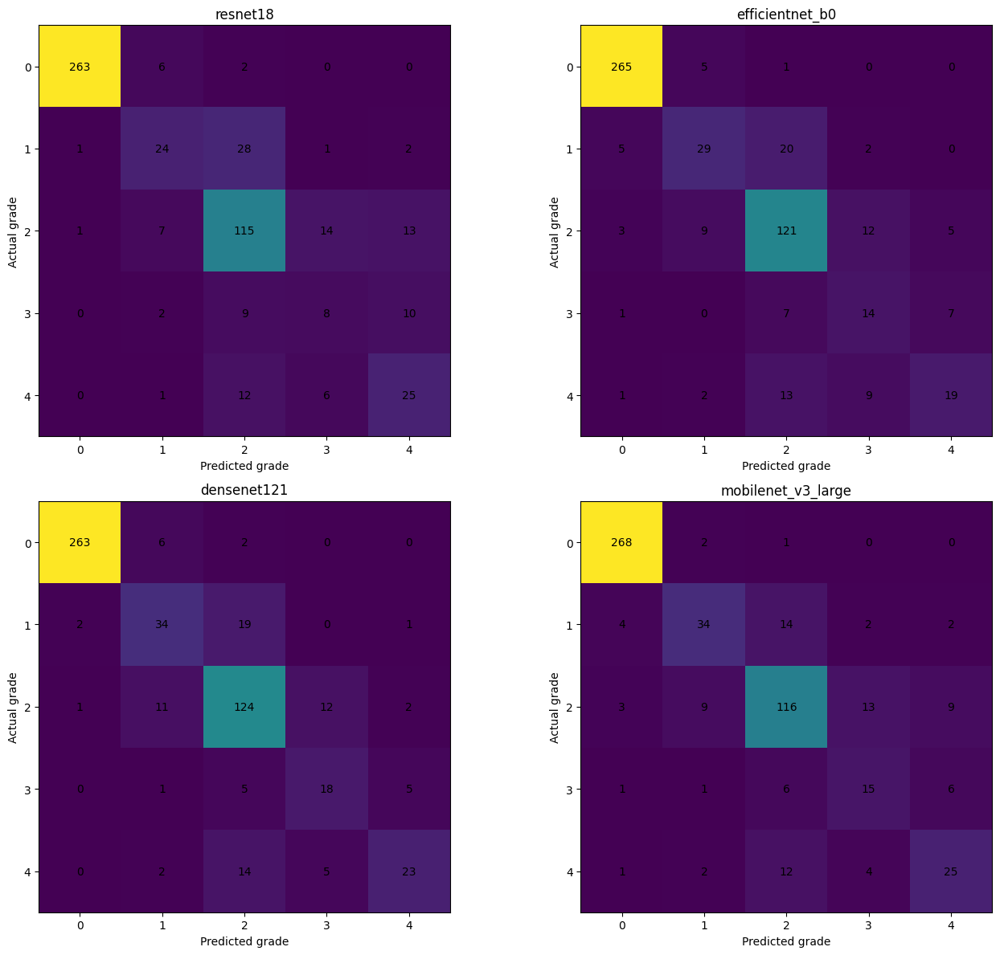


Reports saved in: /kaggle/working/DR-XAI-Comparison-Report
Files:
- densenet121_confusion_matrix.csv
- efficientnet_b0_confusion_matrix.csv
- four_model_confusion_matrices.png
- mobilenet_v3_large_confusion_matrix.csv
- model_comparison.csv
- per_class_metrics.csv
- resnet18_confusion_matrix.csv


In [52]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    confusion_matrix,
    classification_report,
)

BASE = Path("/kaggle/working/DR-XAI-Improved-Experiment-version")
OUTPUT = Path("/kaggle/working/DR-XAI-Comparison-Report")
OUTPUT.mkdir(parents=True, exist_ok=True)

MODELS = [
    "resnet18",
    "efficientnet_b0",
    "densenet121",
    "mobilenet_v3_large",
]

CLASS_NAMES = {
    0: "No DR",
    1: "Mild",
    2: "Moderate",
    3: "Severe",
    4: "Proliferative DR",
}
LABELS = [0, 1, 2, 3, 4]

comparison_rows = []
per_class_rows = []
confusion_matrices = {}
standardized_predictions = {}
reference_actual = None

print("=" * 75)
print("DR-XAI FOUR-MODEL TEST SET COMPARISON")
print("=" * 75)

for model in MODELS:
    path = BASE / "results" / model / "test_predictions.csv"
    df = pd.read_csv(path)

    # Different models used different names for the true-label column.
    actual_col = next(
        (c for c in ["actual_label", "true_label", "diagnosis"]
         if c in df.columns),
        None
    )
    pred_col = next(
        (c for c in ["predicted_label", "prediction", "predicted"]
         if c in df.columns),
        None
    )

    if actual_col is None or pred_col is None:
        raise ValueError(
            f"{model}: cannot identify actual/predicted columns. "
            f"Available columns: {list(df.columns)}"
        )

    actual = pd.to_numeric(df[actual_col], errors="raise").astype(int)
    pred = pd.to_numeric(df[pred_col], errors="raise").astype(int)

    if not set(actual.unique()).issubset(set(LABELS)):
        raise ValueError(f"{model}: unexpected actual class labels.")
    if not set(pred.unique()).issubset(set(LABELS)):
        raise ValueError(f"{model}: unexpected predicted class labels.")

    if reference_actual is None:
        reference_actual = actual.to_numpy()
    elif not np.array_equal(reference_actual, actual.to_numpy()):
        raise ValueError(
            f"{model}: test rows or actual-label order differs from "
            "the first model. Check row alignment before comparing."
        )

    accuracy = accuracy_score(actual, pred)
    macro_precision = precision_score(
        actual, pred, labels=LABELS,
        average="macro", zero_division=0
    )
    macro_recall = recall_score(
        actual, pred, labels=LABELS,
        average="macro", zero_division=0
    )
    macro_f1 = f1_score(
        actual, pred, labels=LABELS,
        average="macro", zero_division=0
    )
    qwk = cohen_kappa_score(
        actual, pred, labels=LABELS, weights="quadratic"
    )

    cm = confusion_matrix(actual, pred, labels=LABELS)
    confusion_matrices[model] = cm

    comparison_rows.append({
        "model": model,
        "test_samples": len(df),
        "accuracy": accuracy,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "quadratic_weighted_kappa": qwk,
    })

    report = classification_report(
        actual,
        pred,
        labels=LABELS,
        output_dict=True,
        zero_division=0,
    )

    for label in LABELS:
        row = report[str(label)]
        per_class_rows.append({
            "model": model,
            "class_id": label,
            "class_name": CLASS_NAMES[label],
            "precision": row["precision"],
            "recall": row["recall"],
            "f1_score": row["f1-score"],
            "support": int(row["support"]),
        })

    standardized_predictions[model] = pd.DataFrame({
        "actual_label": actual,
        "predicted_label": pred,
    })

    print(
        f"{model}: {len(df)} samples | "
        f"Accuracy {accuracy:.4f} | "
        f"Macro-F1 {macro_f1:.4f} | QWK {qwk:.4f}"
    )

# Save the overall comparison
comparison = pd.DataFrame(comparison_rows)
comparison = comparison.sort_values(
    "quadratic_weighted_kappa", ascending=False
).reset_index(drop=True)

per_class = pd.DataFrame(per_class_rows)

comparison.to_csv(
    OUTPUT / "model_comparison.csv", index=False
)
per_class.to_csv(
    OUTPUT / "per_class_metrics.csv", index=False
)

print("\n--- OVERALL COMPARISON (ranked by test QWK) ---")
display(
    comparison.style.format({
        "accuracy": "{:.4f}",
        "macro_precision": "{:.4f}",
        "macro_recall": "{:.4f}",
        "macro_f1": "{:.4f}",
        "quadratic_weighted_kappa": "{:.4f}",
    })
)

print("\n--- PER-CLASS METRICS ---")
display(
    per_class.sort_values(["class_id", "model"]).style.format({
        "precision": "{:.3f}",
        "recall": "{:.3f}",
        "f1_score": "{:.3f}",
    })
)

# Save a separate confusion matrix CSV for every model
for model, cm in confusion_matrices.items():
    cm_df = pd.DataFrame(
        cm,
        index=[f"Actual: {CLASS_NAMES[i]}" for i in LABELS],
        columns=[f"Predicted: {CLASS_NAMES[i]}" for i in LABELS],
    )
    cm_df.to_csv(OUTPUT / f"{model}_confusion_matrix.csv")

# Display all four confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for ax, model in zip(axes, MODELS):
    cm = confusion_matrices[model]
    ax.imshow(cm, interpolation="nearest")
    ax.set_title(model)
    ax.set_xlabel("Predicted grade")
    ax.set_ylabel("Actual grade")
    ax.set_xticks(LABELS)
    ax.set_yticks(LABELS)
    ax.set_xticklabels(LABELS)
    ax.set_yticklabels(LABELS)

    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")

plt.tight_layout()
plt.savefig(
    OUTPUT / "four_model_confusion_matrices.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print("\nReports saved in:", OUTPUT)
print("Files:")
for path in sorted(OUTPUT.iterdir()):
    print("-", path.name)


In [53]:

from pathlib import Path
import json
import pandas as pd

BASE = Path("/kaggle/working/DR-XAI-Improved-Experiment-version")

config_path = BASE / "results" / "densenet121" / "config.json"
config = json.loads(config_path.read_text(encoding="utf-8"))

print("=" * 60)
print("DENSENET121 BASELINE CONFIGURATION")
print("=" * 60)

for key, value in config.items():
    print(f"{key}: {value}")

print("\n" + "=" * 60)
print("TRAINING SPLIT CLASS DISTRIBUTION")
print("=" * 60)

TRAIN_CSV = Path(
    "/kaggle/input/datasets/dharshini2362005/taptos/train_split.csv"
)

train_df = pd.read_csv(TRAIN_CSV)

print("Columns:", list(train_df.columns))

target_col = "diagnosis"
if target_col not in train_df.columns:
    raise ValueError(
        f"Expected '{target_col}' column. Found: {list(train_df.columns)}"
    )

counts = (
    train_df[target_col]
    .astype(int)
    .value_counts()
    .reindex([0, 1, 2, 3, 4], fill_value=0)
)

class_names = {
    0: "No DR",
    1: "Mild",
    2: "Moderate",
    3: "Severe",
    4: "Proliferative DR",
}

distribution = pd.DataFrame({
    "class_id": [0, 1, 2, 3, 4],
    "class_name": [class_names[i] for i in range(5)],
    "training_images": [int(counts[i]) for i in range(5)],
    "percentage": [
        round(100 * counts[i] / len(train_df), 2)
        for i in range(5)
    ],
})

display(distribution)

print("Total training images:", len(train_df))
print("Total validation images: 549")
print("Total test images: 550")


DENSENET121 BASELINE CONFIGURATION
model: densenet121
image_size: 384
batch_size: 16
loss: FocalLoss
focal_gamma: 2.0
focal_alpha: None
ben_graham: True
augmentation: same AdvancedFundusTransform as prior models
learning_rate: 0.0001
weight_decay: 0.0001
max_epochs: 20
early_stopping_patience: 5
optimizer: AdamW
scheduler: ReduceLROnPlateau
model_selection_metric: validation QWK
seed: 42

TRAINING SPLIT CLASS DISTRIBUTION
Columns: ['id_code', 'diagnosis']


,class_id,class_name,training_images,percentage
0,0,No DR,1263,49.28
1,1,Mild,259,10.11
2,2,Moderate,699,27.27
3,3,Severe,135,5.27
4,4,Proliferative DR,207,8.08


Total training images: 2563
Total validation images: 549
Total test images: 550


In [54]:

import inspect
from pathlib import Path

print("=" * 65)
print("EXISTING TRAINING PIPELINE INSPECTION")
print("=" * 65)

# Check important objects already defined in the notebook.
important_names = [
    "FocalLoss",
    "train_one_epoch",
    "validate_one_epoch",
    "save_checkpoint",
    "DEVICE",
    "train_loader",
    "val_loader",
    "test_loader",
    "model",
    "criterion",
    "optimizer",
    "scheduler",
    "train_transform",
    "val_transform",
    "AdvancedFundusTransform",
]

for name in important_names:
    obj = globals().get(name)
    print(f"\n{name}: {'AVAILABLE' if obj is not None else 'not defined'}")

    if obj is not None and callable(obj):
        try:
            print("Signature:", inspect.signature(obj))
        except (TypeError, ValueError):
            pass

        if name in [
            "FocalLoss",
            "train_one_epoch",
            "validate_one_epoch",
            "save_checkpoint",
            "AdvancedFundusTransform",
        ]:
            try:
                print(inspect.getsource(obj)[:5000])
            except (OSError, TypeError):
                print("Source not available in this notebook environment.")

# Inspect the saved baseline checkpoint structure.
checkpoint_path = Path(
    "/kaggle/working/DR-XAI-Improved-Experiment-version/"
    "checkpoints/densenet121/best_model.pt"
)

print("\n" + "=" * 65)
print("DENSENET121 CHECKPOINT STRUCTURE")
print("=" * 65)

if checkpoint_path.is_file():
    try:
        import torch

        try:
            checkpoint = torch.load(
                checkpoint_path,
                map_location="cpu",
                weights_only=False,
            )
        except TypeError:
            checkpoint = torch.load(
                checkpoint_path,
                map_location="cpu",
            )

        if isinstance(checkpoint, dict):
            print("Top-level keys:", list(checkpoint.keys()))

            for key, value in checkpoint.items():
                if isinstance(value, dict):
                    print(
                        f"{key}: dictionary with "
                        f"{len(value)} entries"
                    )
                elif hasattr(value, "shape"):
                    print(f"{key}: tensor shape {tuple(value.shape)}")
                else:
                    print(f"{key}: {type(value).__name__} = {value}")
        else:
            print("Checkpoint object type:", type(checkpoint).__name__)

    except Exception as exc:
        print("Checkpoint inspection error:", repr(exc))
else:
    print("Checkpoint not found:", checkpoint_path)

print("\nInspection complete. No training was performed.")


EXISTING TRAINING PIPELINE INSPECTION

FocalLoss: AVAILABLE
Signature: (gamma=2.0, alpha=None)
Source not available in this notebook environment.

train_one_epoch: AVAILABLE
Signature: (model, loader, optimizer, scaler)
def train_one_epoch(
    model,
    loader,
    optimizer,
    scaler
):

    model.train()

    running_loss = 0.0
    total_samples = 0

    all_true = []
    all_pred = []

    for images, labels in loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        # Mixed precision for Tesla T4
        with torch.amp.autocast(
            device_type="cuda",
            enabled=(DEVICE.type == "cuda")
        ):

            logits = model(
                images
            )

            loss = criterion(
                logits,
                labels
            )

    

In [55]:

from pathlib import Path
import pandas as pd
import numpy as np

TRAIN_CSV = Path(
    "/kaggle/input/datasets/dharshini2362005/taptos/train_split.csv"
)

train_df = pd.read_csv(TRAIN_CSV)

class_ids = [0, 1, 2, 3, 4]
class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR",
]

counts = (
    train_df["diagnosis"]
    .astype(int)
    .value_counts()
    .reindex(class_ids, fill_value=0)
    .to_numpy(dtype=np.float64)
)

if np.any(counts == 0):
    raise ValueError(
        "At least one class is missing from the training split."
    )

# Moderate class weights: square root of inverse frequency.
weights = np.sqrt(counts.sum() / (len(class_ids) * counts))

# Normalize weights so their mean is 1.
weights = weights / weights.mean()

weight_table = pd.DataFrame({
    "class_id": class_ids,
    "class_name": class_names,
    "training_images": counts.astype(int),
    "class_weight": weights,
})

print("Training images:", int(counts.sum()))
print("\nClass weights for the proposed experiment:")
display(weight_table.style.format({"class_weight": "{:.4f}"}))

print("\nPyTorch class-weight tensor values:")
print([round(float(w), 4) for w in weights])

print(
    "\nThese weights are calculated from the training split only. "
    "No validation or test labels were used to calculate them."
)


Training images: 2563

Class weights for the proposed experiment:


,class_id,class_name,training_images,class_weight
0,0,No DR,1263,0.4960
1,1,Mild,259,1.0952
2,2,Moderate,699,0.6667
3,3,Severe,135,1.5170
4,4,Proliferative DR,207,1.2251



PyTorch class-weight tensor values:
[0.496, 1.0952, 0.6667, 1.517, 1.2251]

These weights are calculated from the training split only. No validation or test labels were used to calculate them.


In [56]:

import inspect

if "FocalLoss" not in globals():
    print("FocalLoss is not defined in the current notebook kernel.")
else:
    print("FocalLoss signature:")
    print(inspect.signature(FocalLoss))

    print("\nFocalLoss implementation:")
    try:
        print(inspect.getsource(FocalLoss))
    except (OSError, TypeError):
        print("Source unavailable; please share the class definition cell.")


FocalLoss signature:
(gamma=2.0, alpha=None)

FocalLoss implementation:
Source unavailable; please share the class definition cell.


In [57]:

import torch
import torch.nn as nn
import torch.nn.functional as F

class WeightedFocalLoss(nn.Module):
    """
    Multiclass focal loss with a separate weight for each class.

    logits: [batch_size, number_of_classes]
    targets: [batch_size] with integer class labels
    """
    def __init__(self, class_weights, gamma=2.0):
        super().__init__()

        weights = torch.as_tensor(
            class_weights, dtype=torch.float32
        )

        if weights.ndim != 1 or len(weights) != 5:
            raise ValueError("Expected five class weights for DR grades 0–4.")

        if not torch.isfinite(weights).all() or (weights <= 0).any():
            raise ValueError("Class weights must be finite and positive.")

        self.register_buffer("class_weights", weights)
        self.gamma = float(gamma)

    def forward(self, logits, targets):
        targets = targets.long()

        log_probs = F.log_softmax(logits, dim=1)
        log_pt = log_probs.gather(
            dim=1, index=targets.unsqueeze(1)
        ).squeeze(1)

        pt = log_pt.exp()
        alpha_t = self.class_weights[targets]

        loss = -alpha_t * (1.0 - pt).pow(self.gamma) * log_pt

        return loss.mean()


class_weights = [0.4960, 1.0952, 0.6667, 1.5170, 1.2251]

criterion_weighted = WeightedFocalLoss(
    class_weights=class_weights,
    gamma=2.0,
)

# Small synthetic test only; no real images or model training.
dummy_logits = torch.randn(4, 5, requires_grad=True)
dummy_targets = torch.tensor([0, 1, 3, 4])

dummy_loss = criterion_weighted(dummy_logits, dummy_targets)
dummy_loss.backward()

print("Weighted Focal Loss:", round(dummy_loss.item(), 6))
print("Gradient computed:", dummy_logits.grad is not None)
print("Class weights:", criterion_weighted.class_weights.tolist())
print("Gamma:", criterion_weighted.gamma)

assert torch.isfinite(dummy_loss), "Loss is not finite."
assert dummy_logits.grad is not None, "Gradient computation failed."

print("\nPASS: Weighted Focal Loss is ready for integration.")
print("No training was performed.")


Weighted Focal Loss: 1.584084
Gradient computed: True
Class weights: [0.4959999918937683, 1.0951999425888062, 0.666700005531311, 1.5169999599456787, 1.225100040435791]
Gamma: 2.0

PASS: Weighted Focal Loss is ready for integration.
No training was performed.


In [58]:

import inspect

names_to_check = [
    "train_one_epoch",
    "validate_one_epoch",
    "save_checkpoint",
    "AdvancedFundusTransform",
    "FocalLoss",
    "WeightedFocalLoss",
    "DEVICE",
    "train_loader",
    "val_loader",
    "model",
    "optimizer",
    "scheduler",
]

print("=" * 70)
print("DENSENET121 FINE-TUNING READINESS CHECK")
print("=" * 70)

for name in names_to_check:
    obj = globals().get(name)

    print(f"\n{name}: {'AVAILABLE' if obj is not None else 'NOT DEFINED'}")

    if obj is not None and callable(obj):
        try:
            print("Signature:", inspect.signature(obj))
        except (TypeError, ValueError):
            pass

        if name in [
            "train_one_epoch",
            "validate_one_epoch",
            "save_checkpoint",
            "AdvancedFundusTransform",
        ]:
            try:
                print(inspect.getsource(obj))
            except (OSError, TypeError):
                print("Source unavailable in this environment.")

print("\nInspection complete. No training was performed.")


DENSENET121 FINE-TUNING READINESS CHECK

train_one_epoch: AVAILABLE
Signature: (model, loader, optimizer, scaler)
def train_one_epoch(
    model,
    loader,
    optimizer,
    scaler
):

    model.train()

    running_loss = 0.0
    total_samples = 0

    all_true = []
    all_pred = []

    for images, labels in loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        # Mixed precision for Tesla T4
        with torch.amp.autocast(
            device_type="cuda",
            enabled=(DEVICE.type == "cuda")
        ):

            logits = model(
                images
            )

            loss = criterion(
                logits,
                labels
            )

        scaler.scale(
            loss
        ).backward()

        scaler.step(
            optimizer
      

In [59]:

from pathlib import Path
import json
import torch
import torch.nn as nn
from torchvision import models

# Separate experiment folder
EXPERIMENT_DIR = Path(
    "/kaggle/working/DR_XAI_Project/experiments/"
    "densenet121_weighted_focal"
)
CHECKPOINT_DIR = EXPERIMENT_DIR / "checkpoints"
RESULTS_DIR = EXPERIMENT_DIR / "results"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

BASELINE_CHECKPOINT = Path(
    "/kaggle/working/DR-XAI-Improved-Experiment-version/"
    "checkpoints/densenet121/best_model.pt"
)

# Confirm required objects exist
required_objects = [
    "DEVICE",
    "train_loader",
    "val_loader",
    "WeightedFocalLoss",
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Required notebook objects are missing: {missing_objects}"
    )

if not BASELINE_CHECKPOINT.is_file():
    raise FileNotFoundError(BASELINE_CHECKPOINT)

# Rebuild DenseNet121 with the five-class output head.
# weights=None avoids downloading/reloading ImageNet weights;
# the trained checkpoint supplies the model parameters.
new_model = models.densenet121(weights=None)
new_model.classifier = nn.Linear(
    new_model.classifier.in_features, 5
)

try:
    saved = torch.load(
        BASELINE_CHECKPOINT,
        map_location="cpu",
        weights_only=False,
    )
except TypeError:
    saved = torch.load(
        BASELINE_CHECKPOINT,
        map_location="cpu",
    )

state_dict = saved.get("model_state", saved.get("model_state_dict"))

if state_dict is None:
    raise KeyError(
        "Could not find model_state/model_state_dict in the checkpoint. "
        f"Available keys: {list(saved.keys())}"
    )

new_model.load_state_dict(state_dict, strict=True)
new_model = new_model.to(DEVICE)

# Separate weighted loss; do not overwrite the original criterion.
class_weights = [0.4960, 1.0952, 0.6667, 1.5170, 1.2251]

weighted_criterion = WeightedFocalLoss(
    class_weights=class_weights,
    gamma=2.0,
).to(DEVICE)

print("Baseline checkpoint loaded into a separate model.")
print("Device:", DEVICE)
print("Checkpoint epoch:", saved.get("epoch", "not recorded"))
print("Checkpoint best validation QWK:", saved.get("best_val_qwk", "not recorded"))
print("Weighted loss:", weighted_criterion)
print("Experiment directory:", EXPERIMENT_DIR)
print("Baseline checkpoint left unchanged.")
print("\nNo training has been performed.")


Baseline checkpoint loaded into a separate model.
Device: cuda
Checkpoint epoch: 18
Checkpoint best validation QWK: 0.8874448140503186
Weighted loss: WeightedFocalLoss()
Experiment directory: /kaggle/working/DR_XAI_Project/experiments/densenet121_weighted_focal
Baseline checkpoint left unchanged.

No training has been performed.


In [60]:

import torch

print("=" * 65)
print("WEIGHTED-LOSS EXPERIMENT: DATA VALIDATION")
print("=" * 65)

for loader_name in ["train_loader", "val_loader"]:
    loader = globals().get(loader_name)

    if loader is None:
        raise RuntimeError(f"{loader_name} is not defined.")

    dataset = loader.dataset

    print(f"\n{loader_name}")
    print("Dataset size:", len(dataset))
    print("Batch size:", loader.batch_size)
    print("Number of batches:", len(loader))
    print("Dataset class:", type(dataset).__name__)
    print("Dataset transform:", getattr(dataset, "transform", "not exposed"))

    if hasattr(dataset, "indices"):
        print("Subset indices:", len(dataset.indices))

# Inspect one batch from each loader without performing a forward pass.
for loader_name in ["train_loader", "val_loader"]:
    loader = globals()[loader_name]

    images, labels = next(iter(loader))

    print(f"\nFirst batch from {loader_name}")
    print("Image shape:", tuple(images.shape))
    print("Image dtype:", images.dtype)
    print("Label shape:", tuple(labels.shape))
    print("Label dtype:", labels.dtype)
    print("Labels in batch:", sorted(set(labels.cpu().tolist())))

    if images.ndim != 4 or images.shape[1] != 3:
        raise ValueError(
            f"{loader_name}: expected images shaped [B, 3, H, W]."
        )

    if not torch.isfinite(images).all():
        raise ValueError(f"{loader_name}: non-finite image values found.")

    if not torch.isin(labels, torch.arange(5)).all():
        raise ValueError(
            f"{loader_name}: labels must be integers from 0 through 4."
        )

print("\nData-loader batch checks passed.")
print("No training was performed.")


WEIGHTED-LOSS EXPERIMENT: DATA VALIDATION

train_loader
Dataset size: 2563
Batch size: 16
Number of batches: 161
Dataset class: APTOSDataset
Dataset transform: <__main__.AdvancedFundusTransform object at 0x7e8ba166ae90>

val_loader
Dataset size: 549
Batch size: 16
Number of batches: 35
Dataset class: APTOSDataset
Dataset transform: <__main__.AdvancedFundusTransform object at 0x7e8a44efb230>

First batch from train_loader
Image shape: (16, 3, 384, 384)
Image dtype: torch.float32
Label shape: (16,)
Label dtype: torch.int64
Labels in batch: [0, 1, 2, 3, 4]

First batch from val_loader
Image shape: (16, 3, 384, 384)
Image dtype: torch.float32
Label shape: (16,)
Label dtype: torch.int64
Labels in batch: [0, 1, 2, 4]

Data-loader batch checks passed.
No training was performed.


In [61]:

import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
)

# ---------------------------------------------------------
# 1. Experiment configuration
# ---------------------------------------------------------
SEED = 42
EPOCHS = 20
PATIENCE = 5
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

EXPERIMENT_DIR = Path(
    "/kaggle/working/DR_XAI_Project/experiments/"
    "densenet121_weighted_focal"
)
CHECKPOINT_DIR = EXPERIMENT_DIR / "checkpoints"
RESULTS_DIR = EXPERIMENT_DIR / "results"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

best_path = CHECKPOINT_DIR / "best_model.pt"
last_path = CHECKPOINT_DIR / "last_model.pt"
history_path = RESULTS_DIR / "training_history.csv"
config_path = RESULTS_DIR / "config.json"

# Refuse to overwrite a previous experiment.
if best_path.exists() or last_path.exists() or history_path.exists():
    raise FileExistsError(
        "Experiment outputs already exist. Inspect or back them up "
        "before starting another run; this cell will not overwrite them."
    )

# ---------------------------------------------------------
# 2. Verify model, loaders, loss, and device
# ---------------------------------------------------------
assert "new_model" in globals(), "Run the checkpoint-loading cell first."
assert "weighted_criterion" in globals(), "Weighted loss is missing."
assert len(train_loader.dataset) == 2563
assert len(val_loader.dataset) == 549

device = DEVICE
new_model = new_model.to(device)
weighted_criterion = weighted_criterion.to(device)

optimizer_weighted = AdamW(
    new_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

scheduler_weighted = ReduceLROnPlateau(
    optimizer_weighted,
    mode="max",
    factor=0.5,
    patience=2,
)

scaler_weighted = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda"),
)

config = {
    "experiment": "DenseNet121 class-weighted Focal Loss fine-tuning",
    "baseline_model": "densenet121",
    "baseline_checkpoint": str(BASELINE_CHECKPOINT),
    "baseline_checkpoint_epoch": 18,
    "baseline_best_validation_qwk": 0.8874448140503186,
    "image_size": 384,
    "batch_size": 16,
    "training_samples": len(train_loader.dataset),
    "validation_samples": len(val_loader.dataset),
    "loss": "WeightedFocalLoss",
    "focal_gamma": 2.0,
    "class_weights": [0.4960, 1.0952, 0.6667, 1.5170, 1.2251],
    "ben_graham": True,
    "augmentation": "Existing AdvancedFundusTransform pipeline",
    "optimizer": "AdamW",
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "scheduler": "ReduceLROnPlateau",
    "scheduler_mode": "max",
    "model_selection_metric": "validation QWK",
    "epochs_requested": EPOCHS,
    "early_stopping_patience": PATIENCE,
    "seed": SEED,
    "test_set_used_for_selection": False,
}

config_path.write_text(
    json.dumps(config, indent=2),
    encoding="utf-8",
)

# ---------------------------------------------------------
# 3. Dedicated training and validation functions
# ---------------------------------------------------------
def weighted_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(
            y_true, y_pred, labels=[0, 1, 2, 3, 4],
            average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            y_true, y_pred, labels=[0, 1, 2, 3, 4],
            average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            y_true, y_pred, labels=[0, 1, 2, 3, 4],
            average="macro", zero_division=0
        ),
        "qwk": cohen_kappa_score(
            y_true, y_pred, labels=[0, 1, 2, 3, 4],
            weights="quadratic"
        ),
    }


def run_weighted_epoch(model, loader, training):
    model.train(training)

    total_loss = 0.0
    total_samples = 0
    all_true = []
    all_pred = []

    context = torch.enable_grad if training else torch.no_grad

    with context():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            if training:
                optimizer_weighted.zero_grad(set_to_none=True)

            with torch.amp.autocast(
                device_type=device.type,
                enabled=(device.type == "cuda"),
            ):
                logits = model(images)
                loss = weighted_criterion(logits, labels)

            if training:
                scaler_weighted.scale(loss).backward()
                scaler_weighted.step(optimizer_weighted)
                scaler_weighted.update()

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_samples += batch_size

            all_true.extend(labels.detach().cpu().numpy().tolist())
            all_pred.extend(
                logits.argmax(dim=1).detach().cpu().numpy().tolist()
            )

    metrics = weighted_metrics(
        np.asarray(all_true),
        np.asarray(all_pred),
    )
    metrics["loss"] = total_loss / total_samples
    return metrics


# ---------------------------------------------------------
# 4. Fine-tune and select using validation QWK
# ---------------------------------------------------------
history = []
best_val_qwk = -float("inf")
best_epoch = None
epochs_without_improvement = 0

print("=" * 70)
print("STARTING DENSENET121 WEIGHTED-FOCAL EXPERIMENT")
print("Device:", device)
print("Training samples:", len(train_loader.dataset))
print("Validation samples:", len(val_loader.dataset))
print("Baseline checkpoint remains unchanged.")
print("=" * 70)

for epoch in range(1, EPOCHS + 1):
    start_time = time.time()

    train_metrics = run_weighted_epoch(
        new_model, train_loader, training=True
    )
    val_metrics = run_weighted_epoch(
        new_model, val_loader, training=False
    )

    scheduler_weighted.step(val_metrics["qwk"])
    current_lr = optimizer_weighted.param_groups[0]["lr"]

    row = {
        "epoch": epoch,
        "learning_rate": current_lr,
        "epoch_seconds": time.time() - start_time,
    }

    row.update({
        f"train_{key}": value
        for key, value in train_metrics.items()
    })
    row.update({
        f"val_{key}": value
        for key, value in val_metrics.items()
    })

    history.append(row)
    pd.DataFrame(history).to_csv(history_path, index=False)

    improved = val_metrics["qwk"] > best_val_qwk

    if improved:
        best_val_qwk = val_metrics["qwk"]
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "baseline_checkpoint_epoch": 18,
                "model_state": new_model.state_dict(),
                "optimizer_state": optimizer_weighted.state_dict(),
                "scheduler_state": scheduler_weighted.state_dict(),
                "metrics": val_metrics,
                "best_val_qwk": best_val_qwk,
                "loss": "WeightedFocalLoss",
                "focal_gamma": 2.0,
                "class_weights": config["class_weights"],
                "ben_graham": True,
                "image_size": 384,
                "seed": SEED,
            },
            best_path,
        )
    else:
        epochs_without_improvement += 1

    # Save the latest state each epoch for recovery.
    torch.save(
        {
            "epoch": epoch,
            "model_state": new_model.state_dict(),
            "optimizer_state": optimizer_weighted.state_dict(),
            "scheduler_state": scheduler_weighted.state_dict(),
            "metrics": val_metrics,
            "best_val_qwk": best_val_qwk,
            "loss": "WeightedFocalLoss",
            "focal_gamma": 2.0,
            "class_weights": config["class_weights"],
            "ben_graham": True,
            "image_size": 384,
            "seed": SEED,
        },
        last_path,
    )

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train loss {train_metrics['loss']:.4f} | "
        f"Val loss {val_metrics['loss']:.4f} | "
        f"Val accuracy {val_metrics['accuracy']:.4f} | "
        f"Val macro-F1 {val_metrics['macro_f1']:.4f} | "
        f"Val QWK {val_metrics['qwk']:.4f} | "
        f"Best QWK {best_val_qwk:.4f} "
        f"(epoch {best_epoch}) | "
        f"LR {current_lr:.2e}"
    )

    if epochs_without_improvement >= PATIENCE:
        print(
            f"\nEarly stopping after {epoch} epochs. "
            f"Best validation QWK was {best_val_qwk:.4f} "
            f"at epoch {best_epoch}."
        )
        break

# Record the final run summary.
summary = {
    "epochs_completed": len(history),
    "best_epoch": best_epoch,
    "best_validation_qwk": best_val_qwk,
    "best_checkpoint": str(best_path),
    "last_checkpoint": str(last_path),
    "training_history": str(history_path),
    "config": str(config_path),
}

(RESULTS_DIR / "experiment_summary.json").write_text(
    json.dumps(summary, indent=2),
    encoding="utf-8",
)

print("\n" + "=" * 70)
print("WEIGHTED-FOCAL TRAINING FINISHED")
print(json.dumps(summary, indent=2))
print("No test-set evaluation was performed.")
print("=" * 70)


STARTING DENSENET121 WEIGHTED-FOCAL EXPERIMENT
Device: cuda
Training samples: 2563
Validation samples: 549
Baseline checkpoint remains unchanged.
Epoch 01/20 | Train loss 0.0533 | Val loss 0.3528 | Val accuracy 0.8051 | Val macro-F1 0.6439 | Val QWK 0.8498 | Best QWK 0.8498 (epoch 1) | LR 1.00e-04
Epoch 02/20 | Train loss 0.0542 | Val loss 0.3656 | Val accuracy 0.7832 | Val macro-F1 0.6116 | Val QWK 0.8630 | Best QWK 0.8630 (epoch 2) | LR 1.00e-04
Epoch 03/20 | Train loss 0.0538 | Val loss 0.3761 | Val accuracy 0.8033 | Val macro-F1 0.6493 | Val QWK 0.8778 | Best QWK 0.8778 (epoch 3) | LR 1.00e-04
Epoch 04/20 | Train loss 0.0500 | Val loss 0.3453 | Val accuracy 0.8215 | Val macro-F1 0.6393 | Val QWK 0.8791 | Best QWK 0.8791 (epoch 4) | LR 1.00e-04
Epoch 05/20 | Train loss 0.0366 | Val loss 0.3812 | Val accuracy 0.8179 | Val macro-F1 0.6323 | Val QWK 0.8852 | Best QWK 0.8852 (epoch 5) | LR 1.00e-04
Epoch 06/20 | Train loss 0.0427 | Val loss 0.4823 | Val accuracy 0.8015 | Val macro-F1 0.

In [62]:

import torch
import numpy as np
import pandas as pd
from pathlib import Path
from torchvision import models
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    cohen_kappa_score,
)

BASELINE_PATH = Path(
    "/kaggle/working/DR-XAI-Improved-Experiment-version/"
    "checkpoints/densenet121/best_model.pt"
)

WEIGHTED_PATH = Path(
    "/kaggle/working/DR_XAI_Project/experiments/"
    "densenet121_weighted_focal/checkpoints/best_model.pt"
)

CLASS_NAMES = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR",
]

def load_densenet_checkpoint(path):
    try:
        ckpt = torch.load(
            path, map_location="cpu", weights_only=False
        )
    except TypeError:
        ckpt = torch.load(path, map_location="cpu")

    state = ckpt.get("model_state", ckpt.get("model_state_dict"))
    if state is None:
        raise KeyError(f"No model state found in {path}")

    net = models.densenet121(weights=None)
    net.classifier = nn.Linear(net.classifier.in_features, 5)
    net.load_state_dict(state, strict=True)
    return net.to(DEVICE).eval()

@torch.no_grad()
def get_validation_predictions(net):
    y_true, y_pred = [], []

    for images, labels in val_loader:
        images = images.to(DEVICE, non_blocking=True)

        with torch.amp.autocast(
            device_type=DEVICE.type,
            enabled=(DEVICE.type == "cuda"),
        ):
            logits = net(images)

        y_true.extend(labels.cpu().numpy().tolist())
        y_pred.extend(
            logits.argmax(dim=1).cpu().numpy().tolist()
        )

    return np.asarray(y_true), np.asarray(y_pred)

models_to_compare = {
    "Baseline DenseNet121": load_densenet_checkpoint(BASELINE_PATH),
    "Weighted-Focal DenseNet121": load_densenet_checkpoint(WEIGHTED_PATH),
}

all_rows = []
reference_labels = None

for model_name, net in models_to_compare.items():
    y_true, y_pred = get_validation_predictions(net)

    if reference_labels is None:
        reference_labels = y_true.copy()
    elif not np.array_equal(reference_labels, y_true):
        raise ValueError("Validation label order differs between models.")

    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3, 4],
        zero_division=0,
    )

    print(
        f"\n{model_name}: "
        f"accuracy={accuracy_score(y_true, y_pred):.4f}, "
        f"macro-F1={np.mean(f1):.4f}, "
        f"QWK={cohen_kappa_score(y_true, y_pred, labels=[0,1,2,3,4], weights='quadratic'):.4f}"
    )

    for class_id in range(5):
        all_rows.append({
            "model": model_name,
            "class_id": class_id,
            "class_name": CLASS_NAMES[class_id],
            "precision": precision[class_id],
            "recall": recall[class_id],
            "f1_score": f1[class_id],
            "support": support[class_id],
        })

comparison_df = pd.DataFrame(all_rows)

print("\n--- PER-CLASS VALIDATION RESULTS ---")
display(
    comparison_df.style.format({
        "precision": "{:.3f}",
        "recall": "{:.3f}",
        "f1_score": "{:.3f}",
    })
)

out_path = Path(
    "/kaggle/working/DR_XAI_Project/experiments/"
    "densenet121_weighted_focal/results/"
    "baseline_vs_weighted_validation_per_class.csv"
)
comparison_df.to_csv(out_path, index=False)
print("\nSaved comparison:", out_path)
print("Test set was not used.")



Baseline DenseNet121: accuracy=0.8361, macro-F1=0.6771, QWK=0.8874

Weighted-Focal DenseNet121: accuracy=0.8179, macro-F1=0.6323, QWK=0.8852

--- PER-CLASS VALIDATION RESULTS ---


,model,class_id,class_name,precision,recall,f1_score,support
0,Baseline DenseNet121,0,No DR,0.996,0.985,0.991,271
1,Baseline DenseNet121,1,Mild,0.673,0.600,0.635,55
2,Baseline DenseNet121,2,Moderate,0.715,0.853,0.778,150
3,Baseline DenseNet121,3,Severe,0.467,0.483,0.475,29
4,Baseline DenseNet121,4,Proliferative DR,0.739,0.386,0.507,44
5,Weighted-Focal DenseNet121,0,No DR,0.982,0.985,0.983,271
6,Weighted-Focal DenseNet121,1,Mild,0.682,0.545,0.606,55
7,Weighted-Focal DenseNet121,2,Moderate,0.731,0.833,0.779,150
8,Weighted-Focal DenseNet121,3,Severe,0.356,0.552,0.432,29
9,Weighted-Focal DenseNet121,4,Proliferative DR,0.647,0.250,0.361,44



Saved comparison: /kaggle/working/DR_XAI_Project/experiments/densenet121_weighted_focal/results/baseline_vs_weighted_validation_per_class.csv
Test set was not used.


In [63]:

import torch
import torch.nn as nn
import torch.nn.functional as F

class CumulativeOrdinalLoss(nn.Module):
    """
    Four cumulative binary targets for five ordered DR grades.
    Grade y becomes [y>0, y>1, y>2, y>3].
    """
    def __init__(self):
        super().__init__()

    def forward(self, ordinal_logits, labels):
        if ordinal_logits.ndim != 2 or ordinal_logits.shape[1] != 4:
            raise ValueError(
                "Expected logits with shape [batch_size, 4]."
            )

        labels = labels.long()

        thresholds = torch.arange(
            4, device=labels.device
        ).unsqueeze(0)

        targets = (labels.unsqueeze(1) > thresholds).float()

        return F.binary_cross_entropy_with_logits(
            ordinal_logits, targets
        )


def ordinal_targets(labels):
    thresholds = torch.arange(4, device=labels.device)
    return (labels.unsqueeze(1) > thresholds).float()


# Example labels: grades 0, 1, 2, 3, 4
example_labels = torch.tensor([0, 1, 2, 3, 4])
print("Example grades:")
print(example_labels.tolist())

print("\nCumulative targets:")
print(ordinal_targets(example_labels).int())

# Verify loss and gradient computation
dummy_logits = torch.randn(5, 4, requires_grad=True)
loss_fn = CumulativeOrdinalLoss()
loss = loss_fn(dummy_logits, example_labels)

loss.backward()

print("\nSynthetic ordinal loss:", round(loss.item(), 6))
print("Gradient computed:", dummy_logits.grad is not None)

assert torch.isfinite(loss)
assert dummy_logits.grad is not None

print("\nPASS: Ordinal loss smoke test completed.")
print("No model training performed.")


Example grades:
[0, 1, 2, 3, 4]

Cumulative targets:
tensor([[0, 0, 0, 0],
        [1, 0, 0, 0],
        [1, 1, 0, 0],
        [1, 1, 1, 0],
        [1, 1, 1, 1]], dtype=torch.int32)

Synthetic ordinal loss: 0.875417
Gradient computed: True

PASS: Ordinal loss smoke test completed.
No model training performed.


In [64]:

from pathlib import Path
import json
import torch
import torch.nn as nn
from torchvision import models

BASELINE_PATH = Path(
    "/kaggle/working/DR-XAI-Improved-Experiment-version/"
    "checkpoints/densenet121/best_model.pt"
)

EXPERIMENT_DIR = Path(
    "/kaggle/working/DR_XAI_Project/experiments/"
    "densenet121_ordinal"
)
CHECKPOINT_DIR = EXPERIMENT_DIR / "checkpoints"
RESULTS_DIR = EXPERIMENT_DIR / "results"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

if not BASELINE_PATH.is_file():
    raise FileNotFoundError(BASELINE_PATH)

# Refuse to overwrite an existing ordinal experiment.
if any(EXPERIMENT_DIR.rglob("*.pt")):
    raise FileExistsError(
        "Ordinal checkpoint files already exist. "
        "Inspect or back them up before proceeding."
    )

try:
    checkpoint = torch.load(
        BASELINE_PATH,
        map_location="cpu",
        weights_only=False,
    )
except TypeError:
    checkpoint = torch.load(
        BASELINE_PATH,
        map_location="cpu",
    )

state_dict = checkpoint.get(
    "model_state",
    checkpoint.get("model_state_dict"),
)

if state_dict is None:
    raise KeyError(
        f"No model state found. Keys: {list(checkpoint.keys())}"
    )

# Create a fresh DenseNet121 and load the learned backbone.
ordinal_model = models.densenet121(weights=None)
ordinal_model.classifier = nn.Linear(
    ordinal_model.classifier.in_features, 5
)
ordinal_model.load_state_dict(state_dict, strict=True)

# Replace the five-class head with four cumulative-threshold logits.
ordinal_model.classifier = nn.Linear(
    ordinal_model.classifier.in_features, 4
)
ordinal_model = ordinal_model.to(DEVICE)

ordinal_criterion = CumulativeOrdinalLoss().to(DEVICE)

ordinal_config = {
    "experiment": "DenseNet121 cumulative ordinal classification",
    "baseline_checkpoint": str(BASELINE_PATH),
    "baseline_best_epoch": checkpoint.get("epoch", 18),
    "baseline_best_validation_qwk": checkpoint.get(
        "best_val_qwk", 0.8874448140503186
    ),
    "backbone": "DenseNet121",
    "output_type": "four cumulative thresholds",
    "number_of_dr_grades": 5,
    "image_size": 384,
    "batch_size": 16,
    "training_samples": len(train_loader.dataset),
    "validation_samples": len(val_loader.dataset),
    "ben_graham": True,
    "augmentation": "Existing AdvancedFundusTransform pipeline",
    "optimizer": "AdamW",
    "learning_rate": 0.0001,
    "weight_decay": 0.0001,
    "model_selection_metric": "validation QWK",
    "test_set_used_for_selection": False,
    "seed": 42,
}

(RESULTS_DIR / "config.json").write_text(
    json.dumps(ordinal_config, indent=2),
    encoding="utf-8",
)

print("Ordinal model prepared successfully.")
print("Device:", DEVICE)
print("Output layer:", ordinal_model.classifier)
print("Baseline checkpoint epoch:", checkpoint.get("epoch", "unknown"))
print("Experiment directory:", EXPERIMENT_DIR)
print("Original baseline checkpoint unchanged.")
print("No training performed.")


Ordinal model prepared successfully.
Device: cuda
Output layer: Linear(in_features=1024, out_features=4, bias=True)
Baseline checkpoint epoch: 18
Experiment directory: /kaggle/working/DR_XAI_Project/experiments/densenet121_ordinal
Original baseline checkpoint unchanged.
No training performed.


In [65]:

import time
import json
import random
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
)

# ---------------------------------------------------------
# Experiment settings
# ---------------------------------------------------------
SEED = 42
MAX_EPOCHS = 20
PATIENCE = 5
LR = 1e-4
WEIGHT_DECAY = 1e-4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

EXPERIMENT_DIR = Path(
    "/kaggle/working/DR_XAI_Project/experiments/densenet121_ordinal"
)
CHECKPOINT_DIR = EXPERIMENT_DIR / "checkpoints"
RESULTS_DIR = EXPERIMENT_DIR / "results"

best_path = CHECKPOINT_DIR / "best_model.pt"
last_path = CHECKPOINT_DIR / "last_model.pt"
history_path = RESULTS_DIR / "training_history.csv"
summary_path = RESULTS_DIR / "experiment_summary.json"

# Avoid accidentally overwriting a completed experiment.
if best_path.exists() or last_path.exists() or history_path.exists():
    raise FileExistsError(
        "Ordinal experiment outputs already exist. "
        "Back them up or choose a new experiment directory."
    )

assert len(train_loader.dataset) == 2563
assert len(val_loader.dataset) == 549

ordinal_model = ordinal_model.to(DEVICE)
ordinal_criterion = CumulativeOrdinalLoss().to(DEVICE)

optimizer_ordinal = AdamW(
    ordinal_model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY,
)

scheduler_ordinal = ReduceLROnPlateau(
    optimizer_ordinal,
    mode="max",
    factor=0.5,
    patience=2,
)

scaler_ordinal = torch.amp.GradScaler(
    "cuda",
    enabled=(DEVICE.type == "cuda"),
)

# ---------------------------------------------------------
# Decode four cumulative logits into a DR grade.
# Grade = number of thresholds whose sigmoid probability
# is at least 0.5.
# ---------------------------------------------------------
def decode_ordinal_logits(logits):
    threshold_probabilities = torch.sigmoid(logits)

    # Count positive thresholds.
    predictions = (threshold_probabilities >= 0.5).sum(dim=1)

    # Count-based decoding always returns a value from 0 to 4.
    return predictions, threshold_probabilities


def ordinal_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(
            y_true, y_pred, labels=[0, 1, 2, 3, 4],
            average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            y_true, y_pred, labels=[0, 1, 2, 3, 4],
            average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            y_true, y_pred, labels=[0, 1, 2, 3, 4],
            average="macro", zero_division=0
        ),
        "qwk": cohen_kappa_score(
            y_true, y_pred, labels=[0, 1, 2, 3, 4],
            weights="quadratic"
        ),
    }


def run_ordinal_epoch(model, loader, training):
    model.train(training)

    running_loss = 0.0
    total_samples = 0
    all_true = []
    all_pred = []
    all_probs = []

    grad_context = torch.enable_grad if training else torch.no_grad

    with grad_context():
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            if training:
                optimizer_ordinal.zero_grad(set_to_none=True)

            with torch.amp.autocast(
                device_type=DEVICE.type,
                enabled=(DEVICE.type == "cuda"),
            ):
                logits = model(images)
                loss = ordinal_criterion(logits, labels)

            if training:
                scaler_ordinal.scale(loss).backward()
                scaler_ordinal.step(optimizer_ordinal)
                scaler_ordinal.update()

            predictions, probabilities = decode_ordinal_logits(logits)

            batch_size = labels.size(0)
            running_loss += loss.item() * batch_size
            total_samples += batch_size

            all_true.extend(labels.detach().cpu().numpy().tolist())
            all_pred.extend(predictions.detach().cpu().numpy().tolist())
            all_probs.extend(probabilities.detach().cpu().numpy().tolist())

    metrics = ordinal_metrics(
        np.asarray(all_true),
        np.asarray(all_pred),
    )
    metrics["loss"] = running_loss / total_samples

    return metrics, np.asarray(all_true), np.asarray(all_pred), np.asarray(all_probs)


# ---------------------------------------------------------
# Training and checkpoint selection by validation QWK
# ---------------------------------------------------------
history = []
best_val_qwk = -float("inf")
best_epoch = None
epochs_without_improvement = 0

print("=" * 70)
print("STARTING DENSENET121 ORDINAL EXPERIMENT")
print("Device:", DEVICE)
print("Training samples:", len(train_loader.dataset))
print("Validation samples:", len(val_loader.dataset))
print("Baseline remains unchanged.")
print("=" * 70)

for epoch in range(1, MAX_EPOCHS + 1):
    start = time.time()

    train_metrics, _, _, _ = run_ordinal_epoch(
        ordinal_model, train_loader, training=True
    )
    val_metrics, _, _, _ = run_ordinal_epoch(
        ordinal_model, val_loader, training=False
    )

    scheduler_ordinal.step(val_metrics["qwk"])
    current_lr = optimizer_ordinal.param_groups[0]["lr"]

    row = {
        "epoch": epoch,
        "learning_rate": current_lr,
        "epoch_seconds": time.time() - start,
    }

    row.update({f"train_{k}": v for k, v in train_metrics.items()})
    row.update({f"val_{k}": v for k, v in val_metrics.items()})
    history.append(row)

    pd.DataFrame(history).to_csv(history_path, index=False)

    if val_metrics["qwk"] > best_val_qwk:
        best_val_qwk = val_metrics["qwk"]
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state": ordinal_model.state_dict(),
                "optimizer_state": optimizer_ordinal.state_dict(),
                "scheduler_state": scheduler_ordinal.state_dict(),
                "metrics": val_metrics,
                "best_val_qwk": best_val_qwk,
                "loss": "CumulativeOrdinalLoss",
                "thresholds": 4,
                "image_size": 384,
                "seed": SEED,
                "ben_graham": True,
            },
            best_path,
        )
    else:
        epochs_without_improvement += 1

    torch.save(
        {
            "epoch": epoch,
            "model_state": ordinal_model.state_dict(),
            "optimizer_state": optimizer_ordinal.state_dict(),
            "scheduler_state": scheduler_ordinal.state_dict(),
            "metrics": val_metrics,
            "best_val_qwk": best_val_qwk,
            "loss": "CumulativeOrdinalLoss",
            "thresholds": 4,
            "image_size": 384,
            "seed": SEED,
            "ben_graham": True,
        },
        last_path,
    )

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train loss {train_metrics['loss']:.4f} | "
        f"Val loss {val_metrics['loss']:.4f} | "
        f"Val accuracy {val_metrics['accuracy']:.4f} | "
        f"Val macro-F1 {val_metrics['macro_f1']:.4f} | "
        f"Val QWK {val_metrics['qwk']:.4f} | "
        f"Best QWK {best_val_qwk:.4f} (epoch {best_epoch}) | "
        f"LR {current_lr:.2e}"
    )

    if epochs_without_improvement >= PATIENCE:
        print(
            f"\nEarly stopping at epoch {epoch}. "
            f"Best validation QWK: {best_val_qwk:.4f} "
            f"at epoch {best_epoch}."
        )
        break

summary = {
    "epochs_completed": len(history),
    "best_epoch": best_epoch,
    "best_validation_qwk": best_val_qwk,
    "best_checkpoint": str(best_path),
    "last_checkpoint": str(last_path),
    "training_history": str(history_path),
    "selection_metric": "validation QWK",
    "test_set_used_for_selection": False,
}

summary_path.write_text(
    json.dumps(summary, indent=2),
    encoding="utf-8",
)

print("\n" + "=" * 70)
print("ORDINAL TRAINING FINISHED")
print(json.dumps(summary, indent=2))
print("No test-set evaluation was performed.")
print("=" * 70)


STARTING DENSENET121 ORDINAL EXPERIMENT
Device: cuda
Training samples: 2563
Validation samples: 549
Baseline remains unchanged.
Epoch 01/20 | Train loss 0.1882 | Val loss 0.1816 | Val accuracy 0.8015 | Val macro-F1 0.5840 | Val QWK 0.8456 | Best QWK 0.8456 (epoch 1) | LR 1.00e-04
Epoch 02/20 | Train loss 0.0981 | Val loss 0.1527 | Val accuracy 0.8324 | Val macro-F1 0.6591 | Val QWK 0.8890 | Best QWK 0.8890 (epoch 2) | LR 1.00e-04
Epoch 03/20 | Train loss 0.0778 | Val loss 0.1688 | Val accuracy 0.7869 | Val macro-F1 0.6252 | Val QWK 0.8926 | Best QWK 0.8926 (epoch 3) | LR 1.00e-04
Epoch 04/20 | Train loss 0.0604 | Val loss 0.1738 | Val accuracy 0.8270 | Val macro-F1 0.6571 | Val QWK 0.8709 | Best QWK 0.8926 (epoch 3) | LR 1.00e-04
Epoch 05/20 | Train loss 0.0595 | Val loss 0.1724 | Val accuracy 0.8233 | Val macro-F1 0.6627 | Val QWK 0.8780 | Best QWK 0.8926 (epoch 3) | LR 1.00e-04
Epoch 06/20 | Train loss 0.0544 | Val loss 0.2329 | Val accuracy 0.8033 | Val macro-F1 0.5986 | Val QWK 0.8

In [66]:

from pathlib import Path
import torch

checkpoint_paths = {
    "Baseline DenseNet121": Path(
        "/kaggle/working/DR-XAI-Improved-Experiment-version/"
        "checkpoints/densenet121/best_model.pt"
    ),
    "Weighted Focal DenseNet121": Path(
        "/kaggle/working/DR_XAI_Project/experiments/"
        "densenet121_weighted_focal/checkpoints/best_model.pt"
    ),
    "Ordinal DenseNet121": Path(
        "/kaggle/working/DR_XAI_Project/experiments/"
        "densenet121_ordinal/checkpoints/best_model.pt"
    ),
}

print("=" * 65)
print("CHECKING DENSENET121 EXPERIMENT CHECKPOINTS")
print("=" * 65)

for name, path in checkpoint_paths.items():
    print(f"\n{name}")
    print("Path:", path)
    print("Exists:", path.exists())

    if path.exists():
        checkpoint = torch.load(
            path, map_location="cpu", weights_only=False
        )
        print("Saved object type:", type(checkpoint).__name__)

        if isinstance(checkpoint, dict):
            print("Checkpoint keys:", list(checkpoint.keys()))

            for key in (
                "epoch",
                "best_val_qwk",
                "best_validation_qwk",
                "metrics",
            ):
                if key in checkpoint:
                    print(f"{key}:", checkpoint[key])
    else:
        print("WARNING: Checkpoint not found at this path.")

print("\nValidation loader available:", "val_loader" in globals())
print("Device:", DEVICE if "DEVICE" in globals() else "Not defined")
print("=" * 65)


CHECKING DENSENET121 EXPERIMENT CHECKPOINTS

Baseline DenseNet121
Path: /kaggle/working/DR-XAI-Improved-Experiment-version/checkpoints/densenet121/best_model.pt
Exists: True
Saved object type: dict
Checkpoint keys: ['epoch', 'model_state', 'optimizer_state', 'scheduler_state', 'metrics', 'best_val_qwk', 'class_names', 'image_size', 'batch_size', 'loss', 'focal_gamma', 'ben_graham']
epoch: 18
best_val_qwk: 0.8874448140503186
metrics: {'epoch': 18, 'train_accuracy': 0.9801014436207569, 'train_macro_precision': 0.9660013597526008, 'train_macro_recall': 0.9626302462422933, 'train_macro_f1': 0.9643036784179774, 'train_qwk': 0.9907360460790442, 'train_loss': 0.024181478354866226, 'val_accuracy': 0.8360655737704918, 'val_macro_precision': 0.7181237889606955, 'val_macro_recall': 0.6615390885570298, 'val_macro_f1': 0.677098681208176, 'val_qwk': 0.8874448140503186, 'val_loss': 0.3179802138395251, 'learning_rate': 5e-05, 'epoch_time_seconds': 518.6192615032196}

Weighted Focal DenseNet121
Path: /

In [67]:

from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    cohen_kappa_score,
    confusion_matrix,
)

# --------------------------------------------------
# 1. Paths and settings
# --------------------------------------------------
checkpoint_paths = {
    "Baseline DenseNet121": Path(
        "/kaggle/working/DR-XAI-Improved-Experiment-version/"
        "checkpoints/densenet121/best_model.pt"
    ),
    "Weighted Focal DenseNet121": Path(
        "/kaggle/working/DR_XAI_Project/experiments/"
        "densenet121_weighted_focal/checkpoints/best_model.pt"
    ),
    "Ordinal DenseNet121": Path(
        "/kaggle/working/DR_XAI_Project/experiments/"
        "densenet121_ordinal/checkpoints/best_model.pt"
    ),
}

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR",
]

device = DEVICE
num_classes = 5

for name, path in checkpoint_paths.items():
    if not path.exists():
        raise FileNotFoundError(f"{name} checkpoint missing: {path}")

if "val_loader" not in globals():
    raise RuntimeError("val_loader is not defined. Run the setup cells first.")

# --------------------------------------------------
# 2. Build model and load checkpoint
# --------------------------------------------------
def load_densenet_checkpoint(checkpoint_path, ordinal=False):
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    model = models.densenet121(weights=None)
    output_units = 4 if ordinal else 5

    model.classifier = nn.Linear(
        model.classifier.in_features,
        output_units
    )

    model.load_state_dict(checkpoint["model_state"], strict=True)
    model = model.to(device)
    model.eval()

    return model, checkpoint

# --------------------------------------------------
# 3. Evaluate validation data only
# --------------------------------------------------
def evaluate_model(model, ordinal=False):
    all_labels = []
    all_predictions = []

    with torch.inference_mode():
        for batch in val_loader:
            images, labels = batch[0], batch[1]

            images = images.to(device)
            labels = labels.to(device).long()

            logits = model(images)

            if ordinal:
                # Same threshold decoding used in ordinal training:
                # grade = number of cumulative probabilities >= 0.5
                probabilities = torch.sigmoid(logits)
                predictions = (probabilities >= 0.5).sum(dim=1)
            else:
                predictions = torch.argmax(logits, dim=1)

            all_labels.extend(labels.cpu().numpy().tolist())
            all_predictions.extend(
                predictions.cpu().numpy().astype(int).tolist()
            )

    y_true = np.asarray(all_labels, dtype=int)
    y_pred = np.asarray(all_predictions, dtype=int)

    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=list(range(num_classes)),
        zero_division=0,
    )

    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": precision.mean(),
        "macro_recall": recall.mean(),
        "macro_f1": f1.mean(),
        "qwk": cohen_kappa_score(
            y_true, y_pred, weights="quadratic"
        ),
        "samples": len(y_true),
    }

    per_class = pd.DataFrame({
        "grade": list(range(num_classes)),
        "class": class_names,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "support": support,
    })

    cm = confusion_matrix(
        y_true, y_pred, labels=list(range(num_classes))
    )

    return metrics, per_class, cm

# --------------------------------------------------
# 4. Load and compare all three saved models
# --------------------------------------------------
summary_rows = []
per_class_tables = []
confusion_matrices = {}

for name, path in checkpoint_paths.items():
    is_ordinal = name == "Ordinal DenseNet121"

    print(f"\nEvaluating: {name}")

    model, checkpoint = load_densenet_checkpoint(
        path, ordinal=is_ordinal
    )

    metrics, per_class, cm = evaluate_model(
        model, ordinal=is_ordinal
    )

    summary_rows.append({
        "model": name,
        "checkpoint_epoch": checkpoint["epoch"],
        "best_saved_val_qwk": float(checkpoint["best_val_qwk"]),
        **metrics,
    })

    per_class.insert(0, "model", name)
    per_class_tables.append(per_class)
    confusion_matrices[name] = cm

    print(
        f"Accuracy: {metrics['accuracy']:.4f} | "
        f"Macro-F1: {metrics['macro_f1']:.4f} | "
        f"QWK: {metrics['qwk']:.4f}"
    )

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# --------------------------------------------------
# 5. Display results
# --------------------------------------------------
comparison_df = pd.DataFrame(summary_rows)
per_class_df = pd.concat(per_class_tables, ignore_index=True)

print("\n" + "=" * 80)
print("VALIDATION COMPARISON — NO TEST DATA USED")
print("=" * 80)

display(
    comparison_df.sort_values(
        "qwk", ascending=False
    ).round(4)
)

print("\nPER-CLASS PRECISION, RECALL AND F1")
display(per_class_df.round(4))

print("\nCONFUSION MATRICES (rows = actual, columns = predicted)")
for name, cm in confusion_matrices.items():
    print(f"\n{name}")
    display(pd.DataFrame(
        cm,
        index=[f"Actual: {c}" for c in class_names],
        columns=[f"Pred: {c}" for c in class_names],
    ))

# --------------------------------------------------
# 6. Save reports separately from model checkpoints
# --------------------------------------------------
output_dir = Path(
    "/kaggle/working/DR_XAI_Project/results/"
    "densenet_validation_comparison"
)
output_dir.mkdir(parents=True, exist_ok=True)

comparison_df.to_csv(
    output_dir / "validation_model_comparison.csv",
    index=False
)
per_class_df.to_csv(
    output_dir / "validation_per_class_metrics.csv",
    index=False
)

for name, cm in confusion_matrices.items():
    safe_name = (
        name.lower().replace(" ", "_").replace("-", "_")
    )
    pd.DataFrame(
        cm,
        index=class_names,
        columns=class_names,
    ).to_csv(output_dir / f"{safe_name}_confusion_matrix.csv")

with open(output_dir / "comparison_metadata.json", "w") as f:
    json.dump({
        "evaluation_split": "validation",
        "test_set_used": False,
        "models": list(checkpoint_paths.keys()),
        "class_names": class_names,
    }, f, indent=2)

print("\nReports saved to:", output_dir)
print("No checkpoints were changed.")



Evaluating: Baseline DenseNet121
Accuracy: 0.8361 | Macro-F1: 0.6771 | QWK: 0.8874

Evaluating: Weighted Focal DenseNet121
Accuracy: 0.8179 | Macro-F1: 0.6323 | QWK: 0.8852

Evaluating: Ordinal DenseNet121
Accuracy: 0.7869 | Macro-F1: 0.6252 | QWK: 0.8926

VALIDATION COMPARISON — NO TEST DATA USED


,model,checkpoint_epoch,best_saved_val_qwk,accuracy,macro_precision,macro_recall,macro_f1,qwk,samples
2,Ordinal DenseNet121,3,0.8926,0.7869,0.6543,0.6275,0.6252,0.8926,549
0,Baseline DenseNet121,18,0.8874,0.8361,0.7181,0.6615,0.6771,0.8874,549
1,Weighted Focal DenseNet121,5,0.8852,0.8179,0.6794,0.6332,0.6323,0.8852,549



PER-CLASS PRECISION, RECALL AND F1


,model,grade,class,precision,recall,f1,support
0,Baseline DenseNet121,0,No DR,0.9963,0.9852,0.9907,271
1,Baseline DenseNet121,1,Mild,0.6735,0.6000,0.6346,55
2,Baseline DenseNet121,2,Moderate,0.7151,0.8533,0.7781,150
3,Baseline DenseNet121,3,Severe,0.4667,0.4828,0.4746,29
4,Baseline DenseNet121,4,Proliferative DR,0.7391,0.3864,0.5075,44
5,Weighted Focal DenseNet121,0,No DR,0.9816,0.9852,0.9834,271
6,Weighted Focal DenseNet121,1,Mild,0.6818,0.5455,0.6061,55
7,Weighted Focal DenseNet121,2,Moderate,0.7310,0.8333,0.7788,150
8,Weighted Focal DenseNet121,3,Severe,0.3556,0.5517,0.4324,29
9,Weighted Focal DenseNet121,4,Proliferative DR,0.6471,0.2500,0.3607,44



CONFUSION MATRICES (rows = actual, columns = predicted)

Baseline DenseNet121


...


Weighted Focal DenseNet121


,Pred: No DR,Pred: Mild,Pred: Moderate,Pred: Severe,Pred: Proliferative DR
Actual: No DR,267,3,1,0,0
Actual: Mild,5,30,19,0,1
Actual: Moderate,0,7,125,16,2
Actual: Severe,0,1,9,16,3
Actual: Proliferative DR,0,3,17,13,11



Ordinal DenseNet121


,Pred: No DR,Pred: Mild,Pred: Moderate,Pred: Severe,Pred: Proliferative DR
Actual: No DR,259,8,4,0,0
Actual: Mild,4,20,30,0,1
Actual: Moderate,0,4,115,26,5
Actual: Severe,0,0,8,16,5
Actual: Proliferative DR,0,0,15,7,22



Reports saved to: /kaggle/working/DR_XAI_Project/results/densenet_validation_comparison
No checkpoints were changed.


In [68]:

# FINAL HELD-OUT TEST EVALUATION
# Selected model: Original baseline DenseNet121
# Do not use these results to tune or select models.

from pathlib import Path
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    cohen_kappa_score,
    confusion_matrix,
    classification_report,
)
from IPython.display import display

checkpoint_path = Path(
    "/kaggle/working/DR-XAI-Improved-Experiment-version/"
    "checkpoints/densenet121/best_model.pt"
)

assert checkpoint_path.exists(), "Baseline checkpoint not found."
assert "test_loader" in globals(), "test_loader is not defined."

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

model = models.densenet121(weights=None)
model.classifier = nn.Linear(model.classifier.in_features, 5)
model.load_state_dict(checkpoint["model_state"], strict=True)
model = model.to(DEVICE)
model.eval()

all_true = []
all_pred = []

with torch.inference_mode():
    for batch in test_loader:
        images, labels = batch[0], batch[1]
        images = images.to(DEVICE)
        logits = model(images)
        predictions = logits.argmax(dim=1)

        all_true.extend(labels.cpu().numpy().astype(int).tolist())
        all_pred.extend(
            predictions.cpu().numpy().astype(int).tolist()
        )

y_true = np.asarray(all_true)
y_pred = np.asarray(all_pred)

class_names = [
    "No DR", "Mild", "Moderate", "Severe", "Proliferative DR"
]

precision, recall, f1, support = precision_recall_fscore_support(
    y_true, y_pred, labels=[0, 1, 2, 3, 4], zero_division=0
)

test_metrics = {
    "model": "Baseline DenseNet121",
    "test_samples": len(y_true),
    "accuracy": accuracy_score(y_true, y_pred),
    "macro_precision": precision.mean(),
    "macro_recall": recall.mean(),
    "macro_f1": f1.mean(),
    "test_qwk": cohen_kappa_score(
        y_true, y_pred, weights="quadratic"
    ),
}

print("=" * 65)
print("FINAL BASELINE DENSENET121 TEST RESULTS")
print("=" * 65)
display(pd.DataFrame([test_metrics]).round(4))

per_class_test = pd.DataFrame({
    "grade": range(5),
    "class": class_names,
    "precision": precision,
    "recall": recall,
    "f1": f1,
    "support": support,
})

print("\nPER-CLASS TEST METRICS")
display(per_class_test.round(4))

print("\nCONFUSION MATRIX (rows = actual, columns = predicted)")
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3, 4])
display(pd.DataFrame(cm, index=class_names, columns=class_names))

print("\nClassification report:")
print(classification_report(
    y_true, y_pred, labels=[0, 1, 2, 3, 4],
    target_names=class_names, zero_division=0
))

print("\nTest evaluation complete. Do not tune the model using these results.")


FINAL BASELINE DENSENET121 TEST RESULTS


,model,test_samples,accuracy,macro_precision,macro_recall,macro_f1,test_qwk
0,Baseline DenseNet121,550,0.84,0.7261,0.7095,0.7127,0.9026



PER-CLASS TEST METRICS


,grade,class,precision,recall,f1,support
0,0,No DR,0.9887,0.9705,0.9795,271
1,1,Mild,0.6296,0.6071,0.6182,56
2,2,Moderate,0.7561,0.8267,0.7898,150
3,3,Severe,0.5143,0.6207,0.5625,29
4,4,Proliferative DR,0.7419,0.5227,0.6133,44



CONFUSION MATRIX (rows = actual, columns = predicted)


,No DR,Mild,Moderate,Severe,Proliferative DR
No DR,263,6,2,0,0
Mild,2,34,19,0,1
Moderate,1,11,124,12,2
Severe,0,1,5,18,5
Proliferative DR,0,2,14,5,23



Classification report:
                  precision    recall  f1-score   support

           No DR       0.99      0.97      0.98       271
            Mild       0.63      0.61      0.62        56
        Moderate       0.76      0.83      0.79       150
          Severe       0.51      0.62      0.56        29
Proliferative DR       0.74      0.52      0.61        44

        accuracy                           0.84       550
       macro avg       0.73      0.71      0.71       550
    weighted avg       0.84      0.84      0.84       550


Test evaluation complete. Do not tune the model using these results.


In [69]:

from pathlib import Path
import torch
import torch.nn as nn
from torchvision import models

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------
CHECKPOINT_PATH = Path(
    "/kaggle/working/DR-XAI-Improved-Experiment-version/"
    "checkpoints/densenet121/best_model.pt"
)

CLASS_NAMES = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR",
]

assert CHECKPOINT_PATH.exists(), (
    f"Checkpoint not found: {CHECKPOINT_PATH}"
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# --------------------------------------------------
# 2. Load the saved baseline model
# --------------------------------------------------
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

gradcam_model = models.densenet121(weights=None)
gradcam_model.classifier = nn.Linear(
    gradcam_model.classifier.in_features, 5
)

gradcam_model.load_state_dict(
    checkpoint["model_state"],
    strict=True
)

gradcam_model = gradcam_model.to(DEVICE)
gradcam_model.eval()

# --------------------------------------------------
# 3. Identify the target convolutional layer
# --------------------------------------------------
target_layer = gradcam_model.features.denseblock4

# --------------------------------------------------
# 4. Verify model setup
# --------------------------------------------------
print("=" * 60)
print("GRAD-CAM MODEL SETUP")
print("=" * 60)
print("Checkpoint:", CHECKPOINT_PATH)
print("Checkpoint epoch:", checkpoint["epoch"])
print("Saved validation QWK:", checkpoint["best_val_qwk"])
print("Device:", DEVICE)
print("Model: DenseNet121 baseline")
print("Target layer: features.denseblock4")
print("Output classes:", len(CLASS_NAMES))
print("Model ready:", not gradcam_model.training)
print("=" * 60)


GRAD-CAM MODEL SETUP
Checkpoint: /kaggle/working/DR-XAI-Improved-Experiment-version/checkpoints/densenet121/best_model.pt
Checkpoint epoch: 18
Saved validation QWK: 0.8874448140503186
Device: cuda
Model: DenseNet121 baseline
Target layer: features.denseblock4
Output classes: 5
Model ready: True


In [70]:

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None

        self.forward_handle = target_layer.register_forward_hook(
            self._save_activations
        )

        self.backward_handle = target_layer.register_full_backward_hook(
            self._save_gradients
        )

    def _save_activations(self, module, inputs, output):
        self.activations = output.detach()

    def _save_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor, target_class=None):
        self.model.eval()
        self.model.zero_grad(set_to_none=True)

        input_tensor = input_tensor.to(DEVICE)

        # Gradients are required for Grad-CAM.
        with torch.enable_grad():
            logits = self.model(input_tensor)

            probabilities = torch.softmax(logits, dim=1)
            predicted_class = int(logits.argmax(dim=1).item())

            if target_class is None:
                target_class = predicted_class

            if not 0 <= int(target_class) < len(CLASS_NAMES):
                raise ValueError("target_class must be between 0 and 4.")

            score = logits[:, int(target_class)].sum()
            score.backward()

        # Average gradients spatially to obtain channel weights.
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)

        # Weighted sum of the activation maps.
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = F.relu(cam)

        cam = F.interpolate(
            cam,
            size=input_tensor.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        cam = cam[0, 0].detach().cpu().numpy()

        # Normalize heatmap to [0, 1].
        cam_min, cam_max = cam.min(), cam.max()
        if cam_max > cam_min:
            cam = (cam - cam_min) / (cam_max - cam_min)
        else:
            cam = np.zeros_like(cam)

        result = {
            "heatmap": cam,
            "predicted_class": predicted_class,
            "predicted_label": CLASS_NAMES[predicted_class],
            "target_class": int(target_class),
            "target_label": CLASS_NAMES[int(target_class)],
            "probabilities": probabilities[0].detach().cpu().numpy(),
        }

        self.model.zero_grad(set_to_none=True)
        return result

    def remove_hooks(self):
        self.forward_handle.remove()
        self.backward_handle.remove()


gradcam = GradCAM(gradcam_model, target_layer)

print("Grad-CAM function created successfully.")
print("Target layer:", target_layer.__class__.__name__)
print("Ready to generate a heatmap.")


Grad-CAM function created successfully.
Target layer: _DenseBlock
Ready to generate a heatmap.


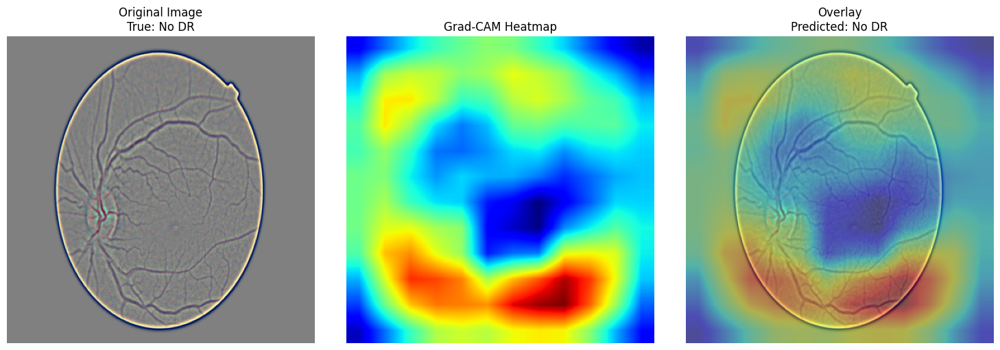

FIRST GRAD-CAM RESULT
True grade: No DR
Predicted grade: No DR
Prediction correct: True

Class probabilities:
No DR               : 0.9899
Mild                : 0.0086
Moderate            : 0.0008
Severe              : 0.0001
Proliferative DR    : 0.0005


In [71]:

import matplotlib.pyplot as plt
import numpy as np
import torch

# Get one batch from the validation set
images, labels = next(iter(val_loader))

# Select the first image
image_tensor = images[0:1].to(DEVICE)
true_class = int(labels[0].item())

# Generate Grad-CAM for the model's predicted class
result = gradcam.generate(image_tensor)

heatmap = result["heatmap"]
predicted_class = result["predicted_class"]
probabilities = result["probabilities"]

# Convert normalized tensor back to displayable RGB
mean = np.array([0.485, 0.456, 0.406]).reshape(1, 1, 3)
std = np.array([0.229, 0.224, 0.225]).reshape(1, 1, 3)

image = image_tensor[0].detach().cpu().permute(1, 2, 0).numpy()
image = np.clip(image * std + mean, 0, 1)

# Display original image, heatmap, and overlay
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title(f"Original Image\nTrue: {CLASS_NAMES[true_class]}")
axes[0].axis("off")

axes[1].imshow(heatmap, cmap="jet", vmin=0, vmax=1)
axes[1].set_title("Grad-CAM Heatmap")
axes[1].axis("off")

axes[2].imshow(image)
axes[2].imshow(heatmap, cmap="jet", alpha=0.4, vmin=0, vmax=1)
axes[2].set_title(
    f"Overlay\nPredicted: {CLASS_NAMES[predicted_class]}"
)
axes[2].axis("off")

plt.tight_layout()
plt.show()

print("=" * 55)
print("FIRST GRAD-CAM RESULT")
print("=" * 55)
print("True grade:", CLASS_NAMES[true_class])
print("Predicted grade:", CLASS_NAMES[predicted_class])
print(f"Prediction correct: {true_class == predicted_class}")
print("\nClass probabilities:")

for class_name, probability in zip(CLASS_NAMES, probabilities):
    print(f"{class_name:20s}: {probability:.4f}")

print("=" * 55)


Image 1: True=No DR | Predicted=No DR | Correct=True
Image 2: True=No DR | Predicted=No DR | Correct=True
Image 3: True=Proliferative DR | Predicted=Moderate | Correct=False
Image 4: True=No DR | Predicted=No DR | Correct=True
Image 5: True=No DR | Predicted=No DR | Correct=True


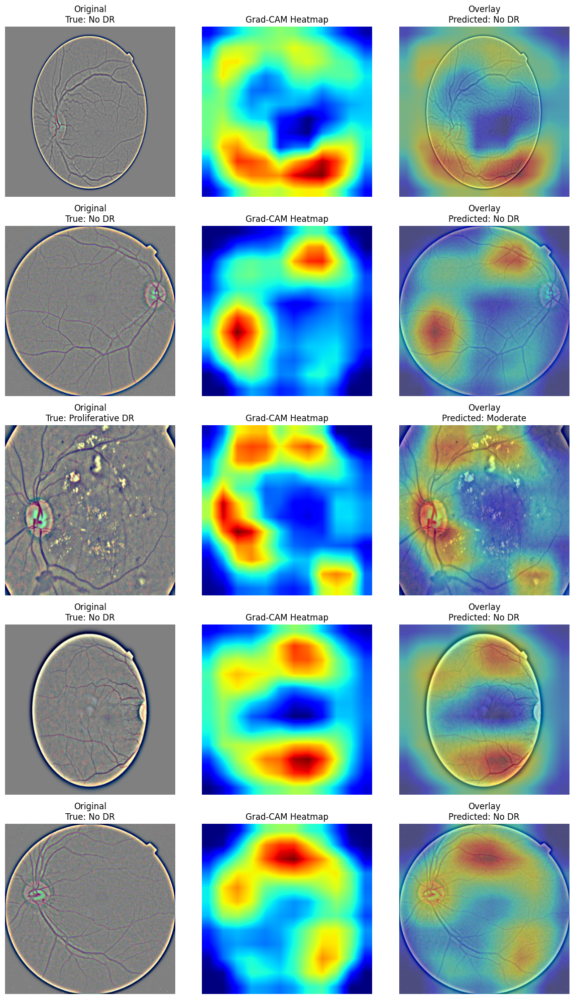

In [72]:

import matplotlib.pyplot as plt
import numpy as np
import torch

# Use a small batch from the validation set.
# No training and no test-set access.
images, labels = next(iter(val_loader))

num_images = min(5, len(labels))

fig, axes = plt.subplots(
    num_images, 3, figsize=(12, 4 * num_images)
)

if num_images == 1:
    axes = np.expand_dims(axes, axis=0)

mean = np.array([0.485, 0.456, 0.406]).reshape(1, 1, 3)
std = np.array([0.229, 0.224, 0.225]).reshape(1, 1, 3)

for i in range(num_images):
    input_tensor = images[i:i+1].to(DEVICE)
    true_class = int(labels[i].item())

    result = gradcam.generate(input_tensor)
    heatmap = result["heatmap"]
    predicted_class = result["predicted_class"]

    image = (
        images[i].detach().cpu().permute(1, 2, 0).numpy()
    )
    image = np.clip(image * std + mean, 0, 1)

    axes[i, 0].imshow(image)
    axes[i, 0].set_title(
        f"Original\nTrue: {CLASS_NAMES[true_class]}"
    )
    axes[i, 0].axis("off")

    axes[i, 1].imshow(heatmap, cmap="jet", vmin=0, vmax=1)
    axes[i, 1].set_title("Grad-CAM Heatmap")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(image)
    axes[i, 2].imshow(
        heatmap, cmap="jet", alpha=0.4, vmin=0, vmax=1
    )
    axes[i, 2].set_title(
        f"Overlay\nPredicted: {CLASS_NAMES[predicted_class]}"
    )
    axes[i, 2].axis("off")

    print(
        f"Image {i+1}: True={CLASS_NAMES[true_class]} | "
        f"Predicted={CLASS_NAMES[predicted_class]} | "
        f"Correct={true_class == predicted_class}"
    )

plt.tight_layout()
plt.show()


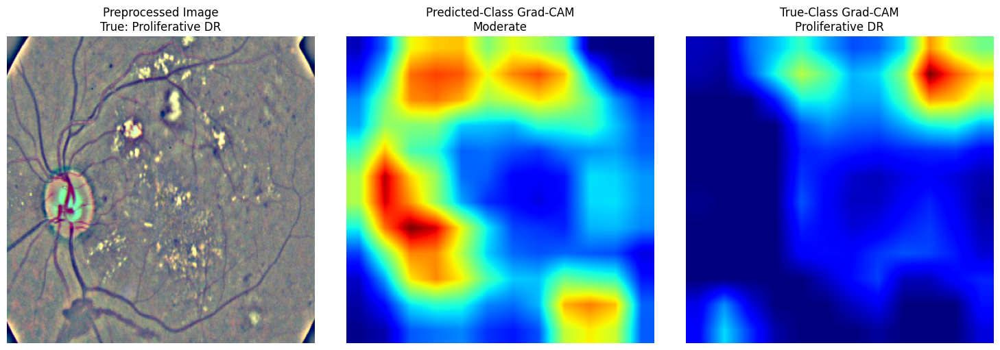

True class: Proliferative DR
Predicted class: Moderate
Correct prediction: False
Predicted-class probability: 0.9145
True-class probability: 0.0353


In [73]:

# Explain the misclassified Proliferative DR image.
# Uses validation data only; no training.

import matplotlib.pyplot as plt
import numpy as np
import torch

images, labels = next(iter(val_loader))

# Third image in this batch was the observed failure case.
sample_index = 2
input_tensor = images[sample_index:sample_index + 1].to(DEVICE)
true_class = int(labels[sample_index].item())

# First pass: explain the model's predicted class.
predicted_result = gradcam.generate(input_tensor)
predicted_class = predicted_result["predicted_class"]

# Second pass: explain the true class.
true_result = gradcam.generate(
    input_tensor,
    target_class=true_class
)

# Convert the preprocessed tensor for display.
mean = np.array([0.485, 0.456, 0.406]).reshape(1, 1, 3)
std = np.array([0.229, 0.224, 0.225]).reshape(1, 1, 3)

image = images[sample_index].detach().cpu().permute(1, 2, 0).numpy()
image = np.clip(image * std + mean, 0, 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title(f"Preprocessed Image\nTrue: {CLASS_NAMES[true_class]}")
axes[0].axis("off")

axes[1].imshow(predicted_result["heatmap"], cmap="jet", vmin=0, vmax=1)
axes[1].set_title(f"Predicted-Class Grad-CAM\n{CLASS_NAMES[predicted_class]}")
axes[1].axis("off")

axes[2].imshow(true_result["heatmap"], cmap="jet", vmin=0, vmax=1)
axes[2].set_title(f"True-Class Grad-CAM\n{CLASS_NAMES[true_class]}")
axes[2].axis("off")

plt.tight_layout()
plt.show()

print("True class:", CLASS_NAMES[true_class])
print("Predicted class:", CLASS_NAMES[predicted_class])
print(
    "Correct prediction:",
    true_class == predicted_class
)
print(
    "Predicted-class probability:",
    round(float(predicted_result["probabilities"][predicted_class]), 4)
)
print(
    "True-class probability:",
    round(float(predicted_result["probabilities"][true_class]), 4)
)


In [74]:

from pathlib import Path
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# --------------------------------------------------
# 1. Output folder
# --------------------------------------------------
GRADCAM_DIR = Path(
    "/kaggle/working/DR_XAI_Project/results/gradcam_validation"
)
ORIGINAL_DIR = GRADCAM_DIR / "original_images"
HEATMAP_DIR = GRADCAM_DIR / "heatmaps"
OVERLAY_DIR = GRADCAM_DIR / "overlays"

for folder in [ORIGINAL_DIR, HEATMAP_DIR, OVERLAY_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 2. Collect up to 10 validation examples
# --------------------------------------------------
MAX_IMAGES = 10
records = []

mean = np.array([0.485, 0.456, 0.406]).reshape(1, 1, 3)
std = np.array([0.229, 0.224, 0.225]).reshape(1, 1, 3)

image_counter = 0

for batch in val_loader:
    images, labels = batch[0], batch[1]

    for i in range(len(labels)):
        if image_counter >= MAX_IMAGES:
            break

        input_tensor = images[i:i+1].to(DEVICE)
        true_class = int(labels[i].item())

        # Explain the model's predicted class
        result = gradcam.generate(input_tensor)
        predicted_class = result["predicted_class"]
        heatmap = result["heatmap"]
        probabilities = result["probabilities"]

        # Reconstruct the normalized image for display.
        # This does not reverse Ben Graham preprocessing.
        image = (
            images[i].detach().cpu().permute(1, 2, 0).numpy()
        )
        image = np.clip(image * std + mean, 0, 1)

        filename = f"validation_{image_counter + 1:03d}"

        # Save original preprocessed image
        plt.imsave(ORIGINAL_DIR / f"{filename}.png", image)

        # Save heatmap
        plt.imsave(
            HEATMAP_DIR / f"{filename}.png",
            heatmap,
            cmap="jet",
            vmin=0,
            vmax=1
        )

        # Save overlay
        fig, ax = plt.subplots(figsize=(6, 6))
        ax.imshow(image)
        ax.imshow(
            heatmap,
            cmap="jet",
            alpha=0.4,
            vmin=0,
            vmax=1
        )
        ax.axis("off")
        fig.savefig(
            OVERLAY_DIR / f"{filename}.png",
            bbox_inches="tight",
            pad_inches=0,
            dpi=200
        )
        plt.close(fig)

        records.append({
            "image_id": filename,
            "true_grade": true_class,
            "true_label": CLASS_NAMES[true_class],
            "predicted_grade": predicted_class,
            "predicted_label": CLASS_NAMES[predicted_class],
            "correct": true_class == predicted_class,
            "predicted_class_probability": float(
                probabilities[predicted_class]
            ),
            "true_class_probability": float(
                probabilities[true_class]
            ),
            **{
                f"probability_{CLASS_NAMES[c].replace(' ', '_')}":
                    float(probabilities[c])
                for c in range(len(CLASS_NAMES))
            }
        })

        image_counter += 1

    if image_counter >= MAX_IMAGES:
        break

# --------------------------------------------------
# 3. Save metadata and summarize
# --------------------------------------------------
metadata_df = pd.DataFrame(records)
metadata_path = GRADCAM_DIR / "gradcam_metadata.csv"
metadata_df.to_csv(metadata_path, index=False)

print("=" * 65)
print("GRAD-CAM VALIDATION EXPORT COMPLETE")
print("=" * 65)
print("Images saved:", len(metadata_df))
print("Correct predictions:", int(metadata_df["correct"].sum()))
print("Incorrect predictions:", int((~metadata_df["correct"]).sum()))
print("Metadata CSV:", metadata_path)
print("Original images:", ORIGINAL_DIR)
print("Heatmaps:", HEATMAP_DIR)
print("Overlays:", OVERLAY_DIR)

display(metadata_df[
    ["image_id", "true_label", "predicted_label",
     "correct", "predicted_class_probability"]
])


GRAD-CAM VALIDATION EXPORT COMPLETE
Images saved: 10
Correct predictions: 9
Incorrect predictions: 1
Metadata CSV: /kaggle/working/DR_XAI_Project/results/gradcam_validation/gradcam_metadata.csv
Original images: /kaggle/working/DR_XAI_Project/results/gradcam_validation/original_images
Heatmaps: /kaggle/working/DR_XAI_Project/results/gradcam_validation/heatmaps
Overlays: /kaggle/working/DR_XAI_Project/results/gradcam_validation/overlays


,image_id,true_label,predicted_label,correct,predicted_class_probability
0,validation_001,No DR,No DR,True,0.989886
1,validation_002,No DR,No DR,True,0.993720
2,validation_003,Proliferative DR,Moderate,False,0.914492
3,validation_004,No DR,No DR,True,0.998189
4,validation_005,No DR,No DR,True,0.980871
5,validation_006,No DR,No DR,True,0.992250
6,validation_007,No DR,No DR,True,0.998836
7,validation_008,Moderate,Moderate,True,0.487164
8,validation_009,Mild,Mild,True,0.921566
9,validation_010,Moderate,Moderate,True,0.644482


In [75]:

from pathlib import Path
import pandas as pd

metadata_path = Path(
    "/kaggle/working/DR_XAI_Project/results/"
    "gradcam_validation/gradcam_metadata.csv"
)

assert metadata_path.exists(), "Grad-CAM metadata CSV not found."

df = pd.read_csv(metadata_path)

print("PREDICTION OUTCOMES BY TRUE GRADE")
summary = (
    df.groupby(["true_label", "correct"])
      .size()
      .unstack(fill_value=0)
      .rename(columns={False: "Incorrect", True: "Correct"})
)

display(summary)

print("\nAVAILABLE CORRECT EXAMPLES BY GRADE")
display(
    df[df["correct"]][
        ["image_id", "true_label", "predicted_label",
         "predicted_class_probability"]
    ].sort_values("true_label")
)

print("\nAVAILABLE MISCLASSIFIED EXAMPLES")
display(
    df[~df["correct"]][
        ["image_id", "true_label", "predicted_label",
         "predicted_class_probability", "true_class_probability"]
    ]
)


PREDICTION OUTCOMES BY TRUE GRADE


correct,Incorrect,Correct
true_label,,
Mild,0,1
Moderate,0,2
No DR,0,6
Proliferative DR,1,0



AVAILABLE CORRECT EXAMPLES BY GRADE


,image_id,true_label,predicted_label,predicted_class_probability
8,validation_009,Mild,Mild,0.921566
7,validation_008,Moderate,Moderate,0.487164
9,validation_010,Moderate,Moderate,0.644482
0,validation_001,No DR,No DR,0.989886
1,validation_002,No DR,No DR,0.993720
3,validation_004,No DR,No DR,0.998189
4,validation_005,No DR,No DR,0.980871
5,validation_006,No DR,No DR,0.992250
6,validation_007,No DR,No DR,0.998836



AVAILABLE MISCLASSIFIED EXAMPLES


,image_id,true_label,predicted_label,predicted_class_probability,true_class_probability
2,validation_003,Proliferative DR,Moderate,0.914492,0.035278


In [76]:

import torch
import pandas as pd

CLASS_NAMES = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR",
]

# Scan validation data only
candidate_rows = []
global_index = 0

gradcam_model.eval()

with torch.inference_mode():
    for images, labels in val_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE).long()

        logits = gradcam_model(images)
        probabilities = torch.softmax(logits, dim=1)
        predictions = logits.argmax(dim=1)
        confidences = probabilities.max(dim=1).values

        for i in range(len(labels)):
            true_grade = int(labels[i].item())
            predicted_grade = int(predictions[i].item())

            candidate_rows.append({
                "validation_index": global_index,
                "true_grade": true_grade,
                "true_label": CLASS_NAMES[true_grade],
                "predicted_grade": predicted_grade,
                "predicted_label": CLASS_NAMES[predicted_grade],
                "correct": true_grade == predicted_grade,
                "predicted_probability": float(confidences[i].item()),
                "true_class_probability": float(
                    probabilities[i, true_grade].item()
                ),
            })

            global_index += 1

candidates_df = pd.DataFrame(candidate_rows)

print("Validation images scanned:", len(candidates_df))

print("\nPER-GRADE CORRECT AND INCORRECT COUNTS")
display(
    candidates_df.groupby(["true_label", "correct"])
    .size()
    .unstack(fill_value=0)
    .rename(columns={False: "Incorrect", True: "Correct"})
)

print("\nCORRECTLY CLASSIFIED CANDIDATES")
display(
    candidates_df[candidates_df["correct"]]
    .sort_values(["true_grade", "predicted_probability"], ascending=[True, False])
    .groupby("true_grade", group_keys=False)
    .head(3)
    .reset_index(drop=True)
)

print("\nMISCLASSIFIED CANDIDATES")
display(
    candidates_df[~candidates_df["correct"]]
    .sort_values("true_grade")
    .head(20)
    .reset_index(drop=True)
)


Validation images scanned: 549

PER-GRADE CORRECT AND INCORRECT COUNTS


correct,Incorrect,Correct
true_label,,
Mild,22,33
Moderate,22,128
No DR,4,267
Proliferative DR,27,17
Severe,15,14



CORRECTLY CLASSIFIED CANDIDATES


,validation_index,true_grade,true_label,predicted_grade,predicted_label,correct,predicted_probability,true_class_probability
0,251,0,No DR,0,No DR,True,0.999504,0.999504
1,540,0,No DR,0,No DR,True,0.999299,0.999299
2,17,0,No DR,0,No DR,True,0.999239,0.999239
3,357,1,Mild,1,Mild,True,0.965231,0.965231
4,202,1,Mild,1,Mild,True,0.959658,0.959658
5,78,1,Mild,1,Mild,True,0.946032,0.946032
6,326,2,Moderate,2,Moderate,True,0.985414,0.985414
7,242,2,Moderate,2,Moderate,True,0.969254,0.969254
8,15,2,Moderate,2,Moderate,True,0.967741,0.967741
9,74,3,Severe,3,Severe,True,0.985295,0.985295



MISCLASSIFIED CANDIDATES


,validation_index,true_grade,true_label,predicted_grade,predicted_label,correct,predicted_probability,true_class_probability
0,23,0,No DR,1,Mild,False,0.638747,0.051639
1,327,0,No DR,1,Mild,False,0.606932,0.299133
2,432,0,No DR,1,Mild,False,0.905036,0.086974
3,495,0,No DR,2,Moderate,False,0.558941,0.020563
4,142,1,Mild,2,Moderate,False,0.827302,0.117704
5,161,1,Mild,2,Moderate,False,0.924787,0.059503
6,95,1,Mild,2,Moderate,False,0.956514,0.016671
7,52,1,Mild,2,Moderate,False,0.848141,0.112421
8,162,1,Mild,2,Moderate,False,0.790251,0.201733
9,338,1,Mild,2,Moderate,False,0.495720,0.426299


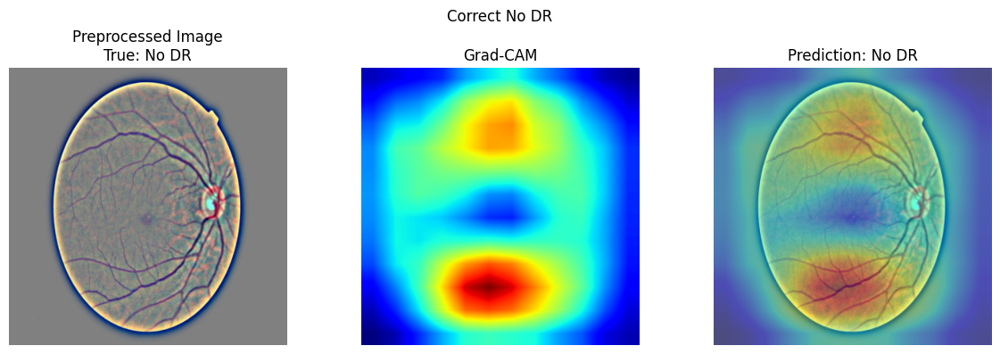

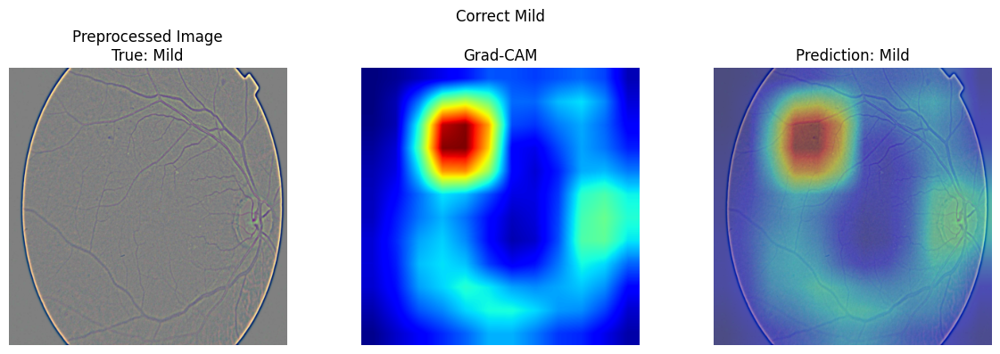

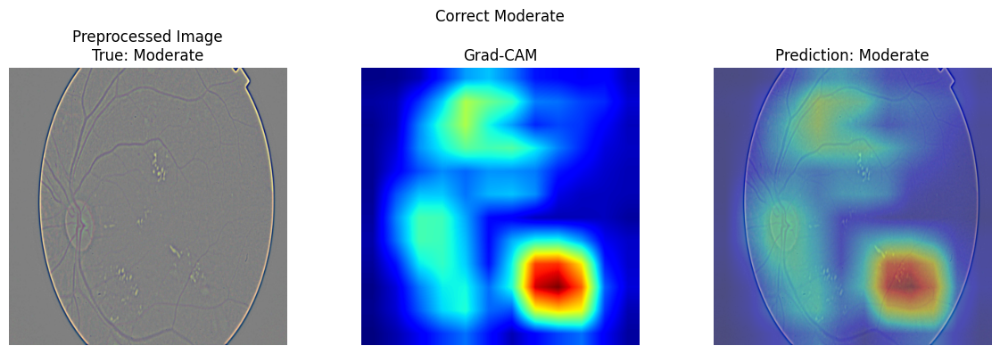

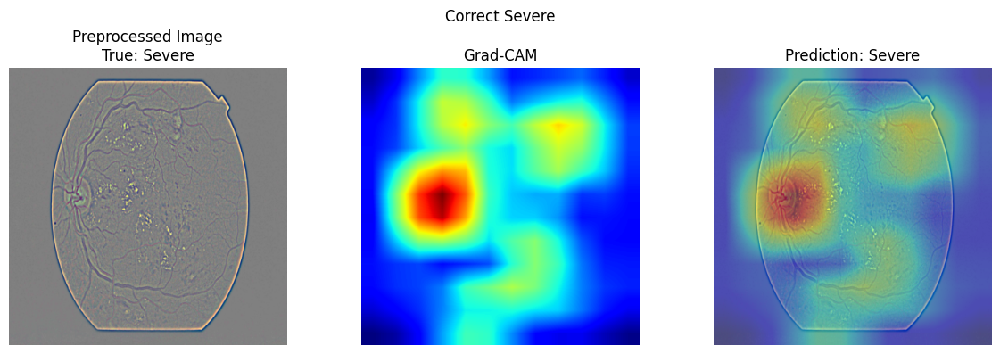

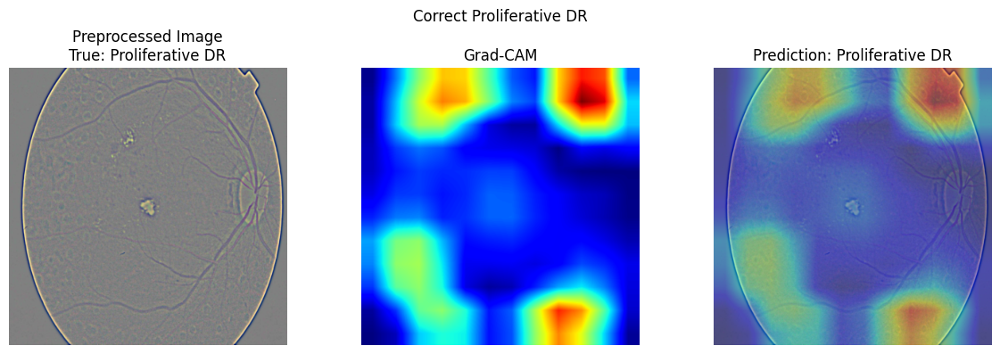

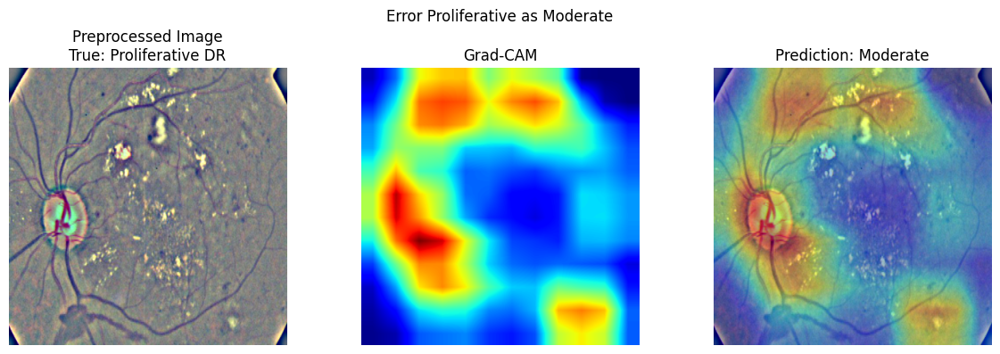

Representative figures saved to: /kaggle/working/DR_XAI_Project/results/gradcam_representative


,case,validation_index,true_label,predicted_label,correct,predicted_probability,true_class_probability,figure
0,Correct_No_DR,251,No DR,No DR,True,0.999504,0.999504,Correct_No_DR.png
1,Correct_Mild,357,Mild,Mild,True,0.965231,0.965231,Correct_Mild.png
2,Correct_Moderate,326,Moderate,Moderate,True,0.985414,0.985414,Correct_Moderate.png
3,Correct_Severe,74,Severe,Severe,True,0.985295,0.985295,Correct_Severe.png
4,Correct_Proliferative_DR,479,Proliferative DR,Proliferative DR,True,0.999201,0.999201,Correct_Proliferative_DR.png
5,Error_Proliferative_as_Moderate,2,Proliferative DR,Moderate,False,0.914492,0.035278,Error_Proliferative_as_Moderate.png


In [77]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# Validation indices selected from the full validation scan
selected_cases = [
    {"index": 251, "case": "Correct_No_DR"},
    {"index": 357, "case": "Correct_Mild"},
    {"index": 326, "case": "Correct_Moderate"},
    {"index": 74,  "case": "Correct_Severe"},
    {"index": 479, "case": "Correct_Proliferative_DR"},
    {"index": 2,   "case": "Error_Proliferative_as_Moderate"},
]

FIG_DIR = Path(
    "/kaggle/working/DR_XAI_Project/results/"
    "gradcam_representative"
)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Retrieve selected images by their sequential validation index.
selected_indices = {case["index"] for case in selected_cases}
selected_images = {}
global_index = 0

for images, labels in val_loader:
    for i in range(len(labels)):
        if global_index in selected_indices:
            selected_images[global_index] = (
                images[i].detach().cpu(),
                int(labels[i].item())
            )
        global_index += 1

missing = selected_indices - set(selected_images)
if missing:
    raise ValueError(f"Could not retrieve validation indices: {missing}")

mean = np.array([0.485, 0.456, 0.406]).reshape(1, 1, 3)
std = np.array([0.229, 0.224, 0.225]).reshape(1, 1, 3)

records = []

for case in selected_cases:
    idx = case["index"]
    image_tensor_cpu, true_class = selected_images[idx]
    input_tensor = image_tensor_cpu.unsqueeze(0).to(DEVICE)

    result = gradcam.generate(input_tensor)
    predicted_class = result["predicted_class"]
    heatmap = result["heatmap"]
    probabilities = result["probabilities"]

    image = image_tensor_cpu.permute(1, 2, 0).numpy()
    image = np.clip(image * std + mean, 0, 1)

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(image)
    axes[0].set_title(f"Preprocessed Image\nTrue: {CLASS_NAMES[true_class]}")
    axes[1].imshow(heatmap, cmap="jet", vmin=0, vmax=1)
    axes[1].set_title("Grad-CAM")
    axes[2].imshow(image)
    axes[2].imshow(heatmap, cmap="jet", alpha=0.4, vmin=0, vmax=1)
    axes[2].set_title(f"Prediction: {CLASS_NAMES[predicted_class]}")

    for ax in axes:
        ax.axis("off")

    fig.suptitle(case["case"].replace("_", " "), fontsize=12)
    fig.tight_layout()

    filename = f"{case['case']}.png"
    fig.savefig(FIG_DIR / filename, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    records.append({
        "case": case["case"],
        "validation_index": idx,
        "true_label": CLASS_NAMES[true_class],
        "predicted_label": CLASS_NAMES[predicted_class],
        "correct": true_class == predicted_class,
        "predicted_probability": float(probabilities[predicted_class]),
        "true_class_probability": float(probabilities[true_class]),
        "figure": filename,
    })

metadata = pd.DataFrame(records)
metadata.to_csv(FIG_DIR / "representative_gradcam_metadata.csv", index=False)

print("Representative figures saved to:", FIG_DIR)
display(metadata)


In [78]:

from pathlib import Path
import pandas as pd

FIG_DIR = Path(
    "/kaggle/working/DR_XAI_Project/results/"
    "gradcam_representative"
)

print("Folder exists:", FIG_DIR.exists())

print("\nFiles:")
for path in sorted(FIG_DIR.iterdir()):
    if path.is_file():
        print(f"{path.name:45s} {path.stat().st_size / 1024:.1f} KB")

metadata_path = FIG_DIR / "representative_gradcam_metadata.csv"
assert metadata_path.exists(), "Metadata CSV is missing."

df = pd.read_csv(metadata_path)

assert len(df) == 6, f"Expected 6 cases, found {len(df)}"
assert df["figure"].nunique() == 6, "Duplicate figure names found."

print("\nCases:", len(df))
print("Correct:", int(df["correct"].sum()))
print("Incorrect:", int((~df["correct"]).sum()))
print("All figures listed in metadata:",
      all((FIG_DIR / name).exists() for name in df["figure"]))

display(df[["case", "true_label", "predicted_label", "correct", "figure"]])


Folder exists: True

Files:
Correct_Mild.png                              1146.8 KB
Correct_Moderate.png                          1048.8 KB
Correct_No_DR.png                             956.4 KB
Correct_Proliferative_DR.png                  1214.8 KB
Correct_Severe.png                            1114.7 KB
Error_Proliferative_as_Moderate.png           1430.6 KB
representative_gradcam_metadata.csv           0.7 KB

Cases: 6
Correct: 5
Incorrect: 1
All figures listed in metadata: True


,case,true_label,predicted_label,correct,figure
0,Correct_No_DR,No DR,No DR,True,Correct_No_DR.png
1,Correct_Mild,Mild,Mild,True,Correct_Mild.png
2,Correct_Moderate,Moderate,Moderate,True,Correct_Moderate.png
3,Correct_Severe,Severe,Severe,True,Correct_Severe.png
4,Correct_Proliferative_DR,Proliferative DR,Proliferative DR,True,Correct_Proliferative_DR.png
5,Error_Proliferative_as_Moderate,Proliferative DR,Moderate,False,Error_Proliferative_as_Moderate.png


In [79]:

from pathlib import Path
import shutil

# Source: verified Grad-CAM outputs
source_dir = Path(
    "/kaggle/working/DR_XAI_Project/results/"
    "gradcam_representative"
)

# Destination: existing persistent Kaggle artifact staging folder
backup_root = Path(
    "/kaggle/working/DR-XAI-Improved-Experiment-version"
)
backup_results = backup_root / "results" / "gradcam_representative"
backup_docs = backup_root / "docs"

assert source_dir.exists(), "Grad-CAM source folder is missing."
assert (source_dir / "representative_gradcam_metadata.csv").exists()
assert backup_root.exists(), "Backup staging folder is missing."

backup_results.mkdir(parents=True, exist_ok=True)
backup_docs.mkdir(parents=True, exist_ok=True)

# Copy figures and metadata without modifying the originals.
for path in source_dir.iterdir():
    if path.is_file():
        destination = backup_results / path.name
        if destination.exists():
            raise FileExistsError(
                f"Destination already exists; not overwriting: {destination}"
            )
        shutil.copy2(path, destination)

report = """# Grad-CAM Explainability Results

## Objective
Generate visual explanations for the selected baseline DenseNet121
diabetic-retinopathy classifier.

## Model and method
- Model: Baseline DenseNet121
- Checkpoint: best baseline checkpoint, epoch 18
- Target layer: `features.denseblock4`
- Explanation method: Grad-CAM
- Data split used for these figures: validation
- Selected cases: five correct predictions, one incorrect prediction

## Representative cases
The figure set contains one correctly classified example for each grade:
No DR, Mild, Moderate, Severe, and Proliferative DR.
It also contains a Proliferative DR image misclassified as Moderate DR.

See `../results/gradcam_representative/representative_gradcam_metadata.csv`
for case labels, predictions, correctness, and prediction probabilities.

## Interpretation and limitations
Grad-CAM highlights image regions that contribute positively to a selected
class score. These maps do not prove that the model detects specific lesions
or relies on clinically valid features.

The displayed images reverse ImageNet normalization, but do not reverse
Ben Graham preprocessing. They are preprocessed images, not raw originals.

The six cases are illustrative examples, not a representative statistical
evaluation of explanation quality. Clinical review and further validation
would be needed before making claims about clinical usefulness.

## Reproducibility
The original baseline checkpoint was loaded without retraining.
The held-out test set was not used to select these Grad-CAM examples.
"""

report_path = backup_docs / "GRADCAM_RESULTS.md"
if report_path.exists():
    raise FileExistsError(
        f"Report already exists; not overwriting: {report_path}"
    )
report_path.write_text(report, encoding="utf-8")

print("Grad-CAM artifacts copied successfully.")
print("Figures and metadata:", backup_results)
print("Report:", report_path)
print("Copied files:", len(list(backup_results.iterdir())))
print("Model checkpoints were not changed.")
print("\nNext: review these staged files, then publish a new version")
print("of the persistent Kaggle artifact backup.")


Grad-CAM artifacts copied successfully.
Figures and metadata: /kaggle/working/DR-XAI-Improved-Experiment-version/results/gradcam_representative
Report: /kaggle/working/DR-XAI-Improved-Experiment-version/docs/GRADCAM_RESULTS.md
Copied files: 7
Model checkpoints were not changed.

Next: review these staged files, then publish a new version
of the persistent Kaggle artifact backup.


In [80]:

from pathlib import Path
import hashlib

source_dir = Path(
    "/kaggle/working/DR_XAI_Project/results/gradcam_representative"
)
backup_dir = Path(
    "/kaggle/working/DR-XAI-Improved-Experiment-version/"
    "results/gradcam_representative"
)
report_path = Path(
    "/kaggle/working/DR-XAI-Improved-Experiment-version/"
    "docs/GRADCAM_RESULTS.md"
)

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

source_files = sorted(p for p in source_dir.iterdir() if p.is_file())

print("=" * 60)
print("GRAD-CAM BACKUP VERIFICATION")
print("=" * 60)

all_match = True

for src in source_files:
    dst = backup_dir / src.name
    exists = dst.exists()
    matches = exists and sha256_file(src) == sha256_file(dst)
    all_match = all_match and matches

    print(f"{src.name}: exists={exists}, contents_match={matches}")

print("\nReport exists:", report_path.exists())
print("Source files:", len(source_files))
print("All copied files match:", all_match)

assert len(source_files) == 7, "Expected 7 Grad-CAM artifact files."
assert all_match, "A copied file is missing or differs from its source."
assert report_path.exists(), "Grad-CAM report is missing."

print("\nVerification successful. Safe to proceed to publishing.")


GRAD-CAM BACKUP VERIFICATION
Correct_Mild.png: exists=True, contents_match=True
Correct_Moderate.png: exists=True, contents_match=True
Correct_No_DR.png: exists=True, contents_match=True
Correct_Proliferative_DR.png: exists=True, contents_match=True
Correct_Severe.png: exists=True, contents_match=True
Error_Proliferative_as_Moderate.png: exists=True, contents_match=True
representative_gradcam_metadata.csv: exists=True, contents_match=True

Report exists: True
Source files: 7
All copied files match: True

Verification successful. Safe to proceed to publishing.


In [81]:

import subprocess

staging_dir = (
    "/kaggle/working/DR-XAI-Improved-Experiment-version"
)

command = [
    "kaggle", "datasets", "version",
    "-p", staging_dir,
    "-m", "Add verified Grad-CAM figures, metadata, and report",
    "--dir-mode", "tar",
]

result = subprocess.run(
    command,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("\nSTDOUT:\n", result.stdout)
print("\nSTDERR:\n", result.stderr)

if result.returncode != 0:
    raise RuntimeError(
        "Kaggle dataset version publishing failed. "
        "Review the output above before retrying."
    )

print("\nPublishing command completed successfully.")


Return code: 0

STDOUT:
Starting upload for file results.tar
Upload successful: results.tar (7MB)
Starting upload for file checkpoints.tar
Upload successful: checkpoints.tar (607MB)
Starting upload for file docs.tar
Upload successful: docs.tar (10KB)
Starting upload for file experiment_manifest.json
Upload successful: experiment_manifest.json (590B)
Dataset version is being created. Please check progress at https://www.kaggle.com/datasets/dharshini2362005/dr-xai-improved-experiment


STDERR:
 
  0%|          | 0.00/7.01M [00:00<?, ?B/s]
 52%|█████▏    | 3.67M/7.01M [00:00<00:00, 38.0MB/s]
100%|██████████| 7.01M/7.01M [00:00<00:00, 13.8MB/s]

  0%|          | 0.00/607M [00:00<?, ?B/s]
  1%|          | 6.27M/607M [00:00<00:09, 65.4MB/s]
  3%|▎         | 20.4M/607M [00:00<00:05, 112MB/s] 
  5%|▌         | 31.0M/607M [00:00<00:06, 92.9MB/s]
  7%|▋         | 40.2M/607M [00:00<00:06, 87.0MB/s]
  8%|▊         | 48.7M/607M [00:00<00:07, 75.7MB/s]
  9%|▉         | 56.1M/607M [00:00<00:07, 72.9M

In [1]:

from pathlib import Path
import torch

CHECKPOINT_ROOT = Path(
    "/kaggle/working/DR-XAI-Improved-Experiment-version/checkpoints"
)

MODEL_NAMES = [
    "resnet18",
    "efficientnet_b0",
    "densenet121",
    "mobilenet_v3_large",
]

print("=" * 70)
print("FOUR-MODEL ENSEMBLE — CHECKPOINT VERIFICATION")
print("=" * 70)

checkpoint_info = {}

for model_name in MODEL_NAMES:
    path = CHECKPOINT_ROOT / model_name / "best_model.pt"

    print(f"\nModel: {model_name}")
    print("Checkpoint:", path)
    print("Exists:", path.exists())

    if not path.exists():
        print("WARNING: Best checkpoint not found.")
        continue

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    state = checkpoint.get("model_state", {})
    classifier_shapes = {
        key: tuple(value.shape)
        for key, value in state.items()
        if key.endswith("classifier.weight")
        or key.endswith("fc.weight")
        or key.endswith("head.weight")
    }

    checkpoint_info[model_name] = {
        "path": str(path),
        "epoch": checkpoint.get("epoch"),
        "class_names": checkpoint.get("class_names"),
        "image_size": checkpoint.get("image_size"),
        "best_val_qwk": checkpoint.get("best_val_qwk"),
        "state_keys": list(state.keys()),
        "classifier_shapes": classifier_shapes,
    }

    print("Saved epoch:", checkpoint.get("epoch"))
    print("Saved class names:", checkpoint.get("class_names"))
    print("Image size:", checkpoint.get("image_size"))
    print("Best saved validation QWK:", checkpoint.get("best_val_qwk"))
    print("Classifier output shapes:", classifier_shapes)

print("\n" + "=" * 70)
print("CHECKPOINTS FOUND:", len(checkpoint_info), "of", len(MODEL_NAMES))
print("Validation loader available:", "val_loader" in globals())
print("Device:", DEVICE if "DEVICE" in globals() else "Not defined")
print("=" * 70)

if len(checkpoint_info) != 4:
    print("STOP: Resolve missing checkpoints before continuing.")
else:
    print("Checkpoint verification complete. No model was retrained.")


FOUR-MODEL ENSEMBLE — CHECKPOINT VERIFICATION

Model: resnet18
Checkpoint: /kaggle/working/DR-XAI-Improved-Experiment-version/checkpoints/resnet18/best_model.pt
Exists: False

Model: efficientnet_b0
Checkpoint: /kaggle/working/DR-XAI-Improved-Experiment-version/checkpoints/efficientnet_b0/best_model.pt
Exists: False

Model: densenet121
Checkpoint: /kaggle/working/DR-XAI-Improved-Experiment-version/checkpoints/densenet121/best_model.pt
Exists: False

Model: mobilenet_v3_large
Checkpoint: /kaggle/working/DR-XAI-Improved-Experiment-version/checkpoints/mobilenet_v3_large/best_model.pt
Exists: False

CHECKPOINTS FOUND: 0 of 4
Validation loader available: False
Device: Not defined
STOP: Resolve missing checkpoints before continuing.


In [2]:

from pathlib import Path

SEARCH_ROOTS = [
    Path("/kaggle/working"),
    Path("/kaggle/input")
]

print("=" * 70)
print("SEARCHING FOR EXISTING MODEL CHECKPOINTS")
print("=" * 70)

checkpoint_files = []

for root in SEARCH_ROOTS:
    if not root.exists():
        print(f"\nFolder unavailable: {root}")
        continue

    print(f"\nSearching: {root}")

    for pattern in ["best_model.pt", "last_model.pt"]:
        for path in root.rglob(pattern):
            checkpoint_files.append(path)
            print(f"FOUND: {path}")

print("\n" + "=" * 70)
print("TOTAL CHECKPOINT FILES FOUND:", len(checkpoint_files))
print("=" * 70)

print("\nKaggle working-directory folders:")
for path in Path("/kaggle/working").iterdir():
    print(path)


SEARCHING FOR EXISTING MODEL CHECKPOINTS

Searching: /kaggle/working

Searching: /kaggle/input
FOUND: /kaggle/input/datasets/dharshini2362005/dr-xai-improved-experiment/checkpoints/efficientnet_b0/best_model.pt
FOUND: /kaggle/input/datasets/dharshini2362005/dr-xai-improved-experiment/checkpoints/mobilenet_v3_large/best_model.pt
FOUND: /kaggle/input/datasets/dharshini2362005/dr-xai-improved-experiment/checkpoints/densenet121/best_model.pt
FOUND: /kaggle/input/datasets/dharshini2362005/dr-xai-improved-experiment/checkpoints/resnet18/best_model.pt
FOUND: /kaggle/input/datasets/dharshini2362005/dr-xai-improved-experiment/checkpoints/efficientnet_b0/last_model.pt
FOUND: /kaggle/input/datasets/dharshini2362005/dr-xai-improved-experiment/checkpoints/mobilenet_v3_large/last_model.pt
FOUND: /kaggle/input/datasets/dharshini2362005/dr-xai-improved-experiment/checkpoints/densenet121/last_model.pt
FOUND: /kaggle/input/datasets/dharshini2362005/dr-xai-improved-experiment/checkpoints/resnet18/last_mo

In [3]:

from pathlib import Path
import torch

CHECKPOINT_ROOT = Path(
    "/kaggle/input/datasets/dharshini2362005/"
    "dr-xai-improved-experiment/checkpoints"
)

MODEL_NAMES = [
    "resnet18",
    "efficientnet_b0",
    "densenet121",
    "mobilenet_v3_large"
]

checkpoint_info = {}

print("=" * 70)
print("VERIFYING ORIGINAL BEST CHECKPOINTS")
print("=" * 70)

for model_name in MODEL_NAMES:
    path = CHECKPOINT_ROOT / model_name / "best_model.pt"

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    state = checkpoint.get(
        "model_state",
        checkpoint.get("state_dict", {})
    )

    classifier_shapes = {
        key: tuple(value.shape)
        for key, value in state.items()
        if any(
            key.endswith(name)
            for name in [
                "classifier.weight",
                "fc.weight",
                "head.weight"
            ]
        )
    }

    checkpoint_info[model_name] = {
        "path": str(path),
        "epoch": checkpoint.get("epoch"),
        "best_val_qwk": checkpoint.get("best_val_qwk"),
        "class_names": checkpoint.get("class_names"),
        "image_size": checkpoint.get("image_size"),
        "state_keys": list(state.keys()),
        "classifier_shapes": classifier_shapes
    }

    print(f"\nModel: {model_name}")
    print(f"Checkpoint exists: {path.exists()}")
    print(f"Saved epoch: {checkpoint.get('epoch')}")
    print(f"Best validation QWK: {checkpoint.get('best_val_qwk')}")
    print(f"Class names: {checkpoint.get('class_names')}")
    print(f"Image size: {checkpoint.get('image_size')}")
    print(f"Classifier shapes: {classifier_shapes}")

print("\nVerified:", len(checkpoint_info), "of", len(MODEL_NAMES))


VERIFYING ORIGINAL BEST CHECKPOINTS

Model: resnet18
Checkpoint exists: True
Saved epoch: 5
Best validation QWK: 0.8563860015214431
Class names: ['No_DR', 'Mild', 'Moderate', 'Severe', 'Proliferative_DR']
Image size: 384
Classifier shapes: {'fc.weight': (5, 512)}

Model: efficientnet_b0
Checkpoint exists: True
Saved epoch: 10
Best validation QWK: 0.8854932438286361
Class names: ['No_DR', 'Mild', 'Moderate', 'Severe', 'Proliferative_DR']
Image size: 384
Classifier shapes: {}

Model: densenet121
Checkpoint exists: True
Saved epoch: 18
Best validation QWK: 0.8874448140503186
Class names: ['No_DR', 'Mild', 'Moderate', 'Severe', 'Proliferative_DR']
Image size: 384
Classifier shapes: {'classifier.weight': (5, 1024)}

Model: mobilenet_v3_large
Checkpoint exists: True
Saved epoch: 15
Best validation QWK: 0.8800384254042672
Class names: ['No_DR', 'Mild', 'Moderate', 'Severe', 'Proliferative_DR']
Image size: 384
Classifier shapes: {}

Verified: 4 of 4


In [4]:

from pathlib import Path
import pandas as pd

DATA_ROOT = Path(
    "/kaggle/input/competitions/aptos2019-blindness-detection"
)

SPLIT_ROOT = Path(
    "/kaggle/input/datasets/dharshini2362005/taptos"
)

IMAGE_ROOT = DATA_ROOT / "train_images"
TRAIN_CSV = SPLIT_ROOT / "train_split.csv"
VAL_CSV = SPLIT_ROOT / "val_split.csv"
TEST_CSV = SPLIT_ROOT / "test_split.csv"

print("=" * 70)
print("ENSEMBLE DATA PIPELINE CHECK")
print("=" * 70)

for label, path in [
    ("Image folder", IMAGE_ROOT),
    ("Training split", TRAIN_CSV),
    ("Validation split", VAL_CSV),
    ("Test split (existence only)", TEST_CSV),
]:
    print(f"{label}: {path}")
    print(f"Exists: {path.exists()}")

if VAL_CSV.exists():
    val_df = pd.read_csv(VAL_CSV)
    print("\nValidation rows:", len(val_df))
    print("Columns:", val_df.columns.tolist())
    print("Class distribution:")
    print(val_df["diagnosis"].value_counts().sort_index())

    missing_images = [
        image_id
        for image_id in val_df["id_code"].astype(str)
        if not (
            IMAGE_ROOT / f"{image_id}.png"
        ).exists()
    ]

    print("Validation images missing:", len(missing_images))
    if missing_images:
        print("First missing IDs:", missing_images[:10])

if TRAIN_CSV.exists() and VAL_CSV.exists() and TEST_CSV.exists():
    train_df = pd.read_csv(TRAIN_CSV)
    test_df = pd.read_csv(TEST_CSV)

    train_ids = set(train_df["id_code"].astype(str))
    val_ids = set(val_df["id_code"].astype(str))
    test_ids = set(test_df["id_code"].astype(str))

    print("\nSplit overlap check:")
    print("Train ∩ Validation:", len(train_ids & val_ids))
    print("Train ∩ Test:", len(train_ids & test_ids))
    print("Validation ∩ Test:", len(val_ids & test_ids))


ENSEMBLE DATA PIPELINE CHECK
Image folder: /kaggle/input/competitions/aptos2019-blindness-detection/train_images
Exists: True
Training split: /kaggle/input/datasets/dharshini2362005/taptos/train_split.csv
Exists: True
Validation split: /kaggle/input/datasets/dharshini2362005/taptos/val_split.csv
Exists: True
Test split (existence only): /kaggle/input/datasets/dharshini2362005/taptos/test_split.csv
Exists: True

Validation rows: 549
Columns: ['id_code', 'diagnosis']
Class distribution:
diagnosis
0    271
1     55
2    150
3     29
4     44
Name: count, dtype: int64
Validation images missing: 0

Split overlap check:
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


In [5]:

from pathlib import Path
import torch

checkpoint_path = (
    Path("/kaggle/input/datasets/dharshini2362005/")
    / "dr-xai-improved-experiment/checkpoints/densenet121/best_model.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("=" * 70)
print("DENSENET121 CHECKPOINT METADATA")
print("=" * 70)

for key, value in checkpoint.items():
    if key not in ["model_state", "state_dict", "optimizer_state", "scheduler_state"]:
        print(f"{key}: {value}")

print("\n" + "=" * 70)
print("SEARCHING FOR CONFIGURATION FILES")
print("=" * 70)

search_roots = [
    Path("/kaggle/input/datasets/dharshini2362005/dr-xai-improved-experiment"),
    Path("/kaggle/working")
]

found = 0

for root in search_roots:
    if root.exists():
        for pattern in ["*.yaml", "*.yml", "*.json", "*.py"]:
            for path in root.rglob(pattern):
                name = path.name.lower()
                if any(word in name for word in [
                    "config", "train", "transform", "preprocess", "model"
                ]):
                    print(path)
                    found += 1
                    if found >= 40:
                        break
            if found >= 40:
                break
    if found >= 40:
        break

print(f"\nConfiguration/script files listed: {found}")


DENSENET121 CHECKPOINT METADATA
epoch: 18
metrics: {'epoch': 18, 'train_accuracy': 0.9801014436207569, 'train_macro_precision': 0.9660013597526008, 'train_macro_recall': 0.9626302462422933, 'train_macro_f1': 0.9643036784179774, 'train_qwk': 0.9907360460790442, 'train_loss': 0.024181478354866226, 'val_accuracy': 0.8360655737704918, 'val_macro_precision': 0.7181237889606955, 'val_macro_recall': 0.6615390885570298, 'val_macro_f1': 0.677098681208176, 'val_qwk': 0.8874448140503186, 'val_loss': 0.3179802138395251, 'learning_rate': 5e-05, 'epoch_time_seconds': 518.6192615032196}
best_val_qwk: 0.8874448140503186
class_names: ['No_DR', 'Mild', 'Moderate', 'Severe', 'Proliferative_DR']
image_size: 384
batch_size: 16
loss: FocalLoss
focal_gamma: 2.0
ben_graham: True

SEARCHING FOR CONFIGURATION FILES
/kaggle/input/datasets/dharshini2362005/dr-xai-improved-experiment/results/efficientnet_b0/config.json
/kaggle/input/datasets/dharshini2362005/dr-xai-improved-experiment/results/mobilenet_v3_large/co

In [6]:

from pathlib import Path
import json

RESULTS_ROOT = Path(
    "/kaggle/input/datasets/dharshini2362005/"
    "dr-xai-improved-experiment/results"
)

MODEL_NAMES = [
    "resnet18",
    "efficientnet_b0",
    "densenet121",
    "mobilenet_v3_large"
]

print("=" * 70)
print("ORIGINAL FOUR-MODEL CONFIGURATIONS")
print("=" * 70)

for model_name in MODEL_NAMES:
    config_path = RESULTS_ROOT / model_name / "config.json"

    print(f"\n{'-' * 70}")
    print(f"MODEL: {model_name}")
    print(f"CONFIG: {config_path}")
    print(f"Exists: {config_path.exists()}")

    if config_path.exists():
        with open(config_path, "r", encoding="utf-8") as file:
            config = json.load(file)

        print(json.dumps(config, indent=2))
    else:
        print("Configuration file not found.")


ORIGINAL FOUR-MODEL CONFIGURATIONS

----------------------------------------------------------------------
MODEL: resnet18
CONFIG: /kaggle/input/datasets/dharshini2362005/dr-xai-improved-experiment/results/resnet18/config.json
Exists: True
{
  "model": "resnet18",
  "image_size": 384,
  "batch_size": 16,
  "loss": "FocalLoss",
  "focal_gamma": 2.0,
  "ben_graham": true,
  "learning_rate": 0.0001,
  "weight_decay": 0.0001,
  "max_epochs": 20,
  "early_stopping_patience": 5
}

----------------------------------------------------------------------
MODEL: efficientnet_b0
CONFIG: /kaggle/input/datasets/dharshini2362005/dr-xai-improved-experiment/results/efficientnet_b0/config.json
Exists: True
{
  "model": "efficientnet_b0",
  "image_size": 384,
  "batch_size": 16,
  "loss": "FocalLoss",
  "focal_gamma": 2.0,
  "ben_graham": true,
  "learning_rate": 0.0001,
  "weight_decay": 0.0001,
  "max_epochs": 20,
  "early_stopping_patience": 5
}

-------------------------------------------------------

In [7]:

from pathlib import Path
import torch
import torchvision
from torchvision import models

CHECKPOINT_ROOT = Path(
    "/kaggle/input/datasets/dharshini2362005/"
    "dr-xai-improved-experiment/checkpoints"
)

MODEL_NAMES = [
    "resnet18",
    "efficientnet_b0",
    "densenet121",
    "mobilenet_v3_large"
]

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

try:
    import cv2
    print("OpenCV:", cv2.__version__)
except ImportError:
    print("OpenCV: NOT AVAILABLE")

print("\n" + "=" * 70)
print("CLASSIFIER AND CHECKPOINT KEY INSPECTION")
print("=" * 70)

for model_name in MODEL_NAMES:
    path = CHECKPOINT_ROOT / model_name / "best_model.pt"
    checkpoint = torch.load(
        path, map_location="cpu", weights_only=False
    )
    state = checkpoint.get(
        "model_state", checkpoint.get("state_dict", {})
    )

    print(f"\n{model_name}")
    print("Output layer weight keys:")
    for key, value in state.items():
        if (
            key.endswith(".weight")
            and len(value.shape) == 2
            and value.shape[0] == 5
        ):
            print(f"  {key}: {tuple(value.shape)}")

    print("Sample state keys:")
    for key in list(state.keys())[-8:]:
        print(" ", key)


PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
OpenCV: 4.14.0

CLASSIFIER AND CHECKPOINT KEY INSPECTION

resnet18
Output layer weight keys:
  fc.weight: (5, 512)
Sample state keys:
  layer4.1.conv2.weight
  layer4.1.bn2.weight
  layer4.1.bn2.bias
  layer4.1.bn2.running_mean
  layer4.1.bn2.running_var
  layer4.1.bn2.num_batches_tracked
  fc.weight
  fc.bias

efficientnet_b0
Output layer weight keys:
  classifier.1.weight: (5, 1280)
Sample state keys:
  features.8.0.weight
  features.8.1.weight
  features.8.1.bias
  features.8.1.running_mean
  features.8.1.running_var
  features.8.1.num_batches_tracked
  classifier.1.weight
  classifier.1.bias

densenet121
Output layer weight keys:
  classifier.weight: (5, 1024)
Sample state keys:
  features.denseblock4.denselayer16.conv2.weight
  features.norm5.weight
  features.norm5.bias
  features.norm5.running_mean
  features.norm5.running_var
  features.norm5.num_batches_tracked
  classifier.weight
  classifier.bias

mobilenet_v3_large
Output laye

In [8]:

from pathlib import Path

SEARCH_ROOTS = [
    Path("/kaggle/input/datasets/dharshini2362005"),
    Path("/kaggle/working")
]

keywords = [
    "AdvancedFundusTransform",
    "ben_graham",
    "Ben Graham",
    "GaussianBlur",
    "ColorJitter"
]

extensions = {".py", ".ipynb", ".txt"}

print("=" * 70)
print("SEARCHING FOR ORIGINAL PREPROCESSING SOURCE")
print("=" * 70)

matches = []
seen = set()

for root in SEARCH_ROOTS:
    if not root.exists():
        continue

    for path in root.rglob("*"):
        if not path.is_file() or path.suffix.lower() not in extensions:
            continue

        if path in seen:
            continue
        seen.add(path)

        try:
            if path.stat().st_size > 5_000_000:
                continue
            content = path.read_text(encoding="utf-8", errors="ignore")
        except Exception:
            continue

        found = [word for word in keywords if word.lower() in content.lower()]

        if found:
            matches.append((path, found, content))
            print(f"\nFILE: {path}")
            print("Matched terms:", ", ".join(found))

print("\nTotal matching files:", len(matches))

for path, found, content in matches[:5]:
    print(f"\n{'=' * 70}\nEXCERPTS FROM: {path}")
    lines = content.splitlines()
    relevant = [
        i for i, line in enumerate(lines)
        if any(word.lower() in line.lower() for word in keywords)
    ]
    shown = set()
    for i in relevant[:8]:
        for j in range(max(0, i - 3), min(len(lines), i + 9)):
            if j not in shown:
                print(f"{j + 1}: {lines[j]}")
                shown.add(j)
        print("---")


SEARCHING FOR ORIGINAL PREPROCESSING SOURCE

FILE: /kaggle/working/.virtual_documents/__notebook_source__.ipynb
Matched terms: AdvancedFundusTransform, ben_graham, Ben Graham, GaussianBlur, ColorJitter

Total matching files: 1

EXCERPTS FROM: /kaggle/working/.virtual_documents/__notebook_source__.ipynb
395: 
396: 
397: # ================================================================
398: # STEP 3 — BEN GRAHAM PREPROCESSING
399: #              + 384x384 ADVANCED FUNDUS TRANSFORM
400: # ================================================================
401: 
402: import cv2
403: import numpy as np
404: import torch
405: 
406: from PIL import Image
---
427: 
428: 
429: # ================================================================
430: # 2. BEN GRAHAM PREPROCESSING
431: # ================================================================
432: 
433: def ben_graham_preprocessing(
434:     image,
435:     sigmaX=10
436: ):
437:     """
438:     Ben Graham-style illumination normalization
-

In [10]:

from pathlib import Path

source_path = Path(
    "/kaggle/working/.virtual_documents/__notebook_source__.ipynb"
)

print("File exists:", source_path.exists())

if source_path.exists():
    print("File size:", source_path.stat().st_size, "bytes")

    text = source_path.read_text(
        encoding="utf-8",
        errors="replace"
    )

    print("Text length:", len(text))

    if not text.strip():
        print(
            "\nThe source file is empty in this session. "
            "Do not continue with this file."
        )
    else:
        lines = text.splitlines()

        terms = [
            "def ben_graham_preprocessing",
            "class AdvancedFundusTransform"
        ]

        found = False

        for term in terms:
            matches = [
                i for i, line in enumerate(lines)
                if term.lower() in line.lower()
            ]

            for i in matches:
                found = True
                start = max(0, i - 5)
                end = min(len(lines), i + 100)

                print(f"\n{'=' * 60}")
                print(f"Found: {term} — line {i + 1}")
                print("=" * 60)

                for j in range(start, end):
                    print(f"{j + 1}: {lines[j]}")

        if not found:
            print("Transform definitions were not found in the text.")


File exists: True
File size: 238828 bytes
Text length: 238573

Found: def ben_graham_preprocessing — line 433
428: 
429: # ================================================================
430: # 2. BEN GRAHAM PREPROCESSING
431: # ================================================================
432: 
433: def ben_graham_preprocessing(
434:     image,
435:     sigmaX=10
436: ):
437:     """
438:     Ben Graham-style illumination normalization
439:     for retinal fundus images.
440: 
441:     Pipeline:
442: 
443:     Original RGB image
444:             ↓
445:     Gaussian illumination estimate
446:             ↓
447:     Illumination correction
448:             ↓
449:     Clipping to [0,255]
450:             ↓
451:     PIL RGB image
452:     """
453: 
454:     # Ensure RGB
455:     if isinstance(image, Image.Image):
456: 
457:         image = image.convert("RGB")
458: 
459:         image = np.array(
460:             image
461:         )
462: 
463:     else:
464: 
465:         image = np.

In [11]:

from pathlib import Path

source_path = Path(
    "/kaggle/working/.virtual_documents/__notebook_source__.ipynb"
)

lines = source_path.read_text(
    encoding="utf-8",
    errors="replace"
).splitlines()

# Print the original transform definitions and wrapper.
start_line = 510
end_line = 610

print("=" * 70)
print("ORIGINAL TRAINING, EVALUATION AND WRAPPER CODE")
print("=" * 70)

for i in range(start_line - 1, min(end_line, len(lines))):
    print(f"{i + 1}: {lines[i]}")


ORIGINAL TRAINING, EVALUATION AND WRAPPER CODE
510: # ================================================================
511: # 3. TRAINING TRANSFORM
512: # ================================================================
513: 
514: train_transform = transforms.Compose([
515: 
516:     # 384 x 384
517:     transforms.Resize(
518:         (IMAGE_SIZE, IMAGE_SIZE)
519:     ),
520: 
521:     # Geometric augmentation
522:     transforms.RandomHorizontalFlip(
523:         p=0.5
524:     ),
525: 
526:     transforms.RandomRotation(
527:         degrees=15
528:     ),
529: 
530:     transforms.RandomAffine(
531:         degrees=0,
532:         translate=(0.05, 0.05),
533:         scale=(0.95, 1.05)
534:     ),
535: 
536:     # Mild photometric augmentation
537:     transforms.ColorJitter(
538:         brightness=0.15,
539:         contrast=0.15,
540:         saturation=0.10,
541:         hue=0.02
542:     ),
543: 
544:     # Convert to tensor
545:     transforms.ToTensor(),
546: 
547:     # Ima

In [12]:

from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import torch

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# --------------------------------------------------
# Paths and settings
# --------------------------------------------------
IMAGE_ROOT = Path(
    "/kaggle/input/competitions/aptos2019-blindness-detection/train_images"
)
VAL_CSV = Path(
    "/kaggle/input/datasets/dharshini2362005/taptos/val_split.csv"
)

IMAGE_SIZE = 384
BATCH_SIZE = 16
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# --------------------------------------------------
# Original Ben Graham preprocessing
# --------------------------------------------------
def ben_graham_preprocessing(image, sigmaX=10):
    if isinstance(image, Image.Image):
        image = np.array(image.convert("RGB"))
    else:
        image = np.asarray(image)

    if image.dtype != np.uint8:
        image = np.clip(image, 0, 255).astype(np.uint8)

    blurred = cv2.GaussianBlur(image, (0, 0), sigmaX=sigmaX)

    processed = cv2.addWeighted(
        image, 4.0,
        blurred, -4.0,
        128
    )

    processed = np.clip(processed, 0, 255).astype(np.uint8)
    return Image.fromarray(processed)

# --------------------------------------------------
# Original evaluation transform
# --------------------------------------------------
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

class AdvancedFundusTransform:
    def __init__(self, train=False):
        if train:
            raise ValueError(
                "This cell is for validation only; do not enable training augmentation."
            )
        self.transform = eval_transform

    def __call__(self, image):
        image = ben_graham_preprocessing(image)
        return self.transform(image)

# --------------------------------------------------
# Validation dataset
# --------------------------------------------------
class APTOSValidationDataset(Dataset):
    def __init__(self, csv_path, image_root, transform):
        self.df = pd.read_csv(csv_path).reset_index(drop=True)
        self.image_root = Path(image_root)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        image_path = self.image_root / f"{row['id_code']}.png"

        with Image.open(image_path) as image:
            image = image.convert("RGB")
            image = self.transform(image)

        label = int(row["diagnosis"])
        return image, label

val_dataset = APTOSValidationDataset(
    VAL_CSV,
    IMAGE_ROOT,
    AdvancedFundusTransform(train=False)
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# --------------------------------------------------
# Sanity checks
# --------------------------------------------------
images, labels = next(iter(val_loader))

print("=" * 70)
print("VALIDATION LOADER CHECK")
print("=" * 70)
print("Device:", DEVICE)
print("Validation samples:", len(val_dataset))
print("Batch image shape:", tuple(images.shape))
print("Batch label shape:", tuple(labels.shape))
print("Image tensor dtype:", images.dtype)
print("Label dtype:", labels.dtype)
print("Labels in first batch:", labels.tolist())
print("All image values finite:", bool(torch.isfinite(images).all()))
print("Total validation batches:", len(val_loader))


VALIDATION LOADER CHECK
Device: cuda
Validation samples: 549
Batch image shape: (16, 3, 384, 384)
Batch label shape: (16,)
Image tensor dtype: torch.float32
Label dtype: torch.int64
Labels in first batch: [0, 0, 4, 0, 0, 0, 0, 2, 1, 2, 0, 0, 2, 2, 4, 2]
All image values finite: True
Total validation batches: 35


In [13]:

from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from torchvision import models

# --------------------------------------------------
# Paths and settings
# --------------------------------------------------
CHECKPOINT_ROOT = Path(
    "/kaggle/input/datasets/dharshini2362005/"
    "dr-xai-improved-experiment/checkpoints"
)

MODEL_NAMES = [
    "resnet18",
    "efficientnet_b0",
    "densenet121",
    "mobilenet_v3_large"
]

CLASS_NAMES = [
    "No_DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative_DR"
]

assert len(val_dataset) == 549
assert len(CLASS_NAMES) == 5

# --------------------------------------------------
# Reconstruct the exact classifier architectures
# --------------------------------------------------
def build_model(model_name):
    if model_name == "resnet18":
        model = models.resnet18(weights=None)
        model.fc = nn.Linear(model.fc.in_features, 5)

    elif model_name == "efficientnet_b0":
        model = models.efficientnet_b0(weights=None)
        model.classifier[1] = nn.Linear(
            model.classifier[1].in_features, 5
        )

    elif model_name == "densenet121":
        model = models.densenet121(weights=None)
        model.classifier = nn.Linear(
            model.classifier.in_features, 5
        )

    elif model_name == "mobilenet_v3_large":
        model = models.mobilenet_v3_large(weights=None)
        model.classifier[3] = nn.Linear(
            model.classifier[3].in_features, 5
        )

    else:
        raise ValueError(f"Unknown model: {model_name}")

    return model

# --------------------------------------------------
# Load checkpoints and run inference
# --------------------------------------------------
validation_probabilities = {}
validation_predictions = {}
validation_labels = None

print("=" * 70)
print("FOUR-MODEL VALIDATION INFERENCE")
print("=" * 70)
print("Device:", DEVICE)

for model_name in MODEL_NAMES:
    checkpoint_path = (
        CHECKPOINT_ROOT / model_name / "best_model.pt"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    saved_classes = checkpoint.get("class_names")
    if saved_classes is not None:
        assert saved_classes == CLASS_NAMES, (
            f"Class order mismatch for {model_name}: {saved_classes}"
        )

    state = checkpoint.get(
        "model_state",
        checkpoint.get("state_dict")
    )
    if state is None:
        raise KeyError(
            f"No model_state/state_dict in {checkpoint_path}"
        )

    model = build_model(model_name)
    model.load_state_dict(state, strict=True)
    model = model.to(DEVICE)
    model.eval()

    all_probabilities = []
    all_labels = []

    with torch.inference_mode():
        for images, labels in val_loader:
            images = images.to(DEVICE, non_blocking=True)

            logits = model(images)

            if logits.ndim != 2 or logits.shape[1] != 5:
                raise ValueError(
                    f"{model_name} returned unexpected shape {tuple(logits.shape)}"
                )

            probabilities = torch.softmax(logits, dim=1)

            all_probabilities.append(probabilities.cpu())
            all_labels.append(labels.cpu())

    probabilities = torch.cat(all_probabilities, dim=0).numpy()
    labels_array = torch.cat(all_labels, dim=0).numpy()

    if validation_labels is None:
        validation_labels = labels_array
    else:
        assert np.array_equal(validation_labels, labels_array), (
            "Validation label order changed between models."
        )

    assert probabilities.shape == (549, 5)
    assert np.isfinite(probabilities).all()
    assert np.allclose(probabilities.sum(axis=1), 1.0, atol=1e-5)

    validation_probabilities[model_name] = probabilities
    validation_predictions[model_name] = probabilities.argmax(axis=1)

    print(
        f"{model_name}: loaded successfully | "
        f"checkpoint epoch={checkpoint.get('epoch')} | "
        f"probabilities={probabilities.shape}"
    )

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nAll four models completed validation inference.")
print("Validation samples:", len(validation_labels))
print("Models evaluated:", len(validation_probabilities))
print("Test set used: NO")


FOUR-MODEL VALIDATION INFERENCE
Device: cuda
resnet18: loaded successfully | checkpoint epoch=5 | probabilities=(549, 5)
efficientnet_b0: loaded successfully | checkpoint epoch=10 | probabilities=(549, 5)
densenet121: loaded successfully | checkpoint epoch=18 | probabilities=(549, 5)
mobilenet_v3_large: loaded successfully | checkpoint epoch=15 | probabilities=(549, 5)

All four models completed validation inference.
Validation samples: 549
Models evaluated: 4
Test set used: NO


In [14]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    confusion_matrix,
    classification_report
)

# --------------------------------------------------
# 1. Build hard-voting predictions
# Tie-break rule: among tied classes, choose the class
# with the largest summed probability across the models.
# --------------------------------------------------
individual_preds = np.stack(
    [validation_predictions[name] for name in MODEL_NAMES],
    axis=0
)  # shape: (4 models, 549 samples)

individual_probs = np.stack(
    [validation_probabilities[name] for name in MODEL_NAMES],
    axis=0
)  # shape: (4 models, 549 samples, 5 classes)

hard_predictions = []

for sample_index in range(len(validation_labels)):
    votes = individual_preds[:, sample_index]
    counts = np.bincount(votes, minlength=5)
    tied_classes = np.flatnonzero(counts == counts.max())

    if len(tied_classes) == 1:
        selected_class = int(tied_classes[0])
    else:
        summed_probabilities = individual_probs[
            :, sample_index, :
        ].sum(axis=0)

        selected_class = int(
            tied_classes[
                np.argmax(summed_probabilities[tied_classes])
            ]
        )

    hard_predictions.append(selected_class)

hard_predictions = np.asarray(hard_predictions)

# --------------------------------------------------
# 2. Build soft-voting predictions
# --------------------------------------------------
mean_probabilities = individual_probs.mean(axis=0)
soft_predictions = mean_probabilities.argmax(axis=1)

# --------------------------------------------------
# 3. Evaluate all methods on validation only
# --------------------------------------------------
predictions_to_compare = {
    **validation_predictions,
    "hard_voting": hard_predictions,
    "soft_voting": soft_predictions
}

rows = []

for method_name, predictions in predictions_to_compare.items():
    rows.append({
        "Method": method_name,
        "Accuracy": accuracy_score(
            validation_labels, predictions
        ),
        "Macro_Precision": precision_score(
            validation_labels, predictions,
            average="macro", zero_division=0
        ),
        "Macro_Recall": recall_score(
            validation_labels, predictions,
            average="macro", zero_division=0
        ),
        "Macro_F1": f1_score(
            validation_labels, predictions,
            average="macro", zero_division=0
        ),
        "QWK": cohen_kappa_score(
            validation_labels, predictions,
            weights="quadratic"
        )
    })

comparison_df = pd.DataFrame(rows).sort_values(
    "QWK", ascending=False
).reset_index(drop=True)

print("=" * 90)
print("VALIDATION COMPARISON — HIGHER IS BETTER FOR ALL METRICS")
print("=" * 90)
print(comparison_df.round(4).to_string(index=False))

# --------------------------------------------------
# 4. Best validation-QWK method and its class metrics
# --------------------------------------------------
best_method = comparison_df.iloc[0]["Method"]
best_predictions = predictions_to_compare[best_method]

print("\nBest method by validation QWK:", best_method)
print("\nPer-class report for this method:")
print(classification_report(
    validation_labels,
    best_predictions,
    labels=[0, 1, 2, 3, 4],
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))

print("Confusion matrix (rows=actual, columns=predicted):")
print(confusion_matrix(
    validation_labels,
    best_predictions,
    labels=[0, 1, 2, 3, 4]
))

print("\nTest set used: NO")


VALIDATION COMPARISON — HIGHER IS BETTER FOR ALL METRICS
            Method  Accuracy  Macro_Precision  Macro_Recall  Macro_F1    QWK
       hard_voting    0.8342           0.7401        0.6820    0.6906 0.8895
       soft_voting    0.8324           0.7377        0.6844    0.6924 0.8893
       densenet121    0.8361           0.7181        0.6615    0.6771 0.8874
   efficientnet_b0    0.8124           0.7052        0.6456    0.6499 0.8846
mobilenet_v3_large    0.8179           0.6870        0.6860    0.6763 0.8794
          resnet18    0.7760           0.6049        0.5951    0.5962 0.8564

Best method by validation QWK: hard_voting

Per-class report for this method:
                  precision    recall  f1-score   support

           No_DR     0.9852    0.9852    0.9852       271
            Mild     0.6977    0.5455    0.6122        55
        Moderate     0.7251    0.8267    0.7726       150
          Severe     0.4286    0.6207    0.5070        29
Proliferative_DR     0.8636    0.4

In [15]:

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import confusion_matrix

# --------------------------------------------------
# 1. Collect predictions
# --------------------------------------------------
model_names = [
    "resnet18",
    "efficientnet_b0",
    "densenet121",
    "mobilenet_v3_large"
]

class_names = [
    "No_DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative_DR"
]

y_true = np.asarray(validation_labels)

pred_matrix = np.stack(
    [validation_predictions[name] for name in model_names],
    axis=1
)

densenet_pred = validation_predictions["densenet121"]
hard_pred = np.asarray(hard_predictions)
soft_pred = np.asarray(soft_predictions)

assert pred_matrix.shape == (len(y_true), 4)
assert len(hard_pred) == len(y_true)
assert len(soft_pred) == len(y_true)

# --------------------------------------------------
# 2. Count model agreement
# --------------------------------------------------
agreement_count = np.array([
    len(np.unique(pred_matrix[i]))
    for i in range(len(y_true))
])

all_four_agree = agreement_count == 1
three_or_more_agree = np.array([
    np.bincount(row, minlength=5).max() >= 3
    for row in pred_matrix
])

print("=" * 75)
print("MODEL AGREEMENT")
print("=" * 75)
print("Validation images:", len(y_true))
print("All four models agree:", int(all_four_agree.sum()))
print("All four agreement rate:", round(all_four_agree.mean() * 100, 2), "%")
print("At least three models agree:", int(three_or_more_agree.sum()))
print("At least three agreement rate:",
      round(three_or_more_agree.mean() * 100, 2), "%")

# --------------------------------------------------
# 3. Compare ensemble changes against DenseNet121
# --------------------------------------------------
densenet_correct = densenet_pred == y_true
hard_correct = hard_pred == y_true
soft_correct = soft_pred == y_true

hard_corrected = (~densenet_correct) & hard_correct
hard_new_errors = densenet_correct & (~hard_correct)

soft_corrected = (~densenet_correct) & soft_correct
soft_new_errors = densenet_correct & (~soft_correct)

print("\n" + "=" * 75)
print("ENSEMBLE CHANGES COMPARED WITH DENSENET121")
print("=" * 75)

print("Hard voting:")
print("  DenseNet mistakes corrected:", int(hard_corrected.sum()))
print("  DenseNet correct predictions changed to errors:",
      int(hard_new_errors.sum()))

print("\nSoft voting:")
print("  DenseNet mistakes corrected:", int(soft_corrected.sum()))
print("  DenseNet correct predictions changed to errors:",
      int(soft_new_errors.sum()))

# --------------------------------------------------
# 4. Images all four models misclassify
# --------------------------------------------------
all_four_wrong = np.all(pred_matrix != y_true[:, None], axis=1)

print("\n" + "=" * 75)
print("IMAGES MISCLASSIFIED BY ALL FOUR MODELS")
print("=" * 75)
print("Count:", int(all_four_wrong.sum()))

# --------------------------------------------------
# 5. Per-grade comparison of corrected/new errors
# --------------------------------------------------
grade_rows = []

for grade in range(5):
    mask = y_true == grade
    grade_rows.append({
        "Grade": class_names[grade],
        "Support": int(mask.sum()),
        "DenseNet_correct": int(densenet_correct[mask].sum()),
        "Hard_correct": int(hard_correct[mask].sum()),
        "Hard_corrected_DenseNet_errors": int(
            (hard_corrected & mask).sum()
        ),
        "Hard_new_errors": int((hard_new_errors & mask).sum()),
        "Soft_correct": int(soft_correct[mask].sum()),
        "Soft_corrected_DenseNet_errors": int(
            (soft_corrected & mask).sum()
        ),
        "Soft_new_errors": int((soft_new_errors & mask).sum())
    })

grade_comparison_df = pd.DataFrame(grade_rows)

print("\n" + "=" * 110)
print("PER-GRADE COMPARISON")
print("=" * 110)
print(grade_comparison_df.to_string(index=False))

# --------------------------------------------------
# 6. Save validation-only records for later analysis
# --------------------------------------------------
output_dir = Path("/kaggle/working/DR_XAI_Project/results/ensemble_analysis")
output_dir.mkdir(parents=True, exist_ok=True)

record_df = pd.DataFrame({
    "validation_index": np.arange(len(y_true)),
    "true_grade": y_true,
    "densenet121_prediction": densenet_pred,
    "hard_voting_prediction": hard_pred,
    "soft_voting_prediction": soft_pred,
    "all_four_models_agree": all_four_agree,
    "at_least_three_agree": three_or_more_agree,
    "all_four_models_wrong": all_four_wrong,
    "densenet121_correct": densenet_correct,
    "hard_voting_correct": hard_correct,
    "soft_voting_correct": soft_correct
})

record_df.to_csv(output_dir / "validation_disagreement_records.csv", index=False)
grade_comparison_df.to_csv(
    output_dir / "per_grade_ensemble_changes.csv",
    index=False
)

print("\nSaved validation-only analysis to:", output_dir)
print("Test set used: NO")


MODEL AGREEMENT
Validation images: 549
All four models agree: 421
All four agreement rate: 76.68 %
At least three models agree: 507
At least three agreement rate: 92.35 %

ENSEMBLE CHANGES COMPARED WITH DENSENET121
Hard voting:
  DenseNet mistakes corrected: 14
  DenseNet correct predictions changed to errors: 15

Soft voting:
  DenseNet mistakes corrected: 15
  DenseNet correct predictions changed to errors: 17

IMAGES MISCLASSIFIED BY ALL FOUR MODELS
Count: 53

PER-GRADE COMPARISON
           Grade  Support  DenseNet_correct  Hard_correct  Hard_corrected_DenseNet_errors  Hard_new_errors  Soft_correct  Soft_corrected_DenseNet_errors  Soft_new_errors
           No_DR      271               267           267                               0                0           266                               0                1
            Mild       55                33            30                               1                4            30                               1                4
 

In [16]:

from pathlib import Path
import numpy as np
import pandas as pd

# --------------------------------------------------
# Output and validation metadata
# --------------------------------------------------
OUTPUT_DIR = Path(
    "/kaggle/working/DR_XAI_Project/results/ensemble_analysis"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

val_df = pd.read_csv(VAL_CSV).reset_index(drop=True)

assert len(val_df) == len(validation_labels) == 549

# --------------------------------------------------
# Prepare model predictions and confidence scores
# --------------------------------------------------
record_df = pd.DataFrame({
    "validation_index": np.arange(len(validation_labels)),
    "image_id": val_df["id_code"].astype(str),
    "true_grade": np.asarray(validation_labels),
    "true_grade_name": [
        CLASS_NAMES[int(y)] for y in validation_labels
    ],
    "densenet_prediction": validation_predictions["densenet121"],
    "densenet_confidence": validation_probabilities["densenet121"].max(axis=1),
    "hard_voting_prediction": hard_predictions,
    "hard_voting_confidence_mean": np.stack(
        [validation_probabilities[name] for name in MODEL_NAMES]
    ).mean(axis=0).max(axis=1),
    "soft_voting_prediction": soft_predictions,
    "soft_voting_confidence": mean_probabilities.max(axis=1)
})

for model_name in MODEL_NAMES:
    probabilities = validation_probabilities[model_name]
    record_df[f"{model_name}_prediction"] = probabilities.argmax(axis=1)
    record_df[f"{model_name}_confidence"] = probabilities.max(axis=1)

# --------------------------------------------------
# Identify the three groups
# --------------------------------------------------
prediction_matrix = np.stack([
    validation_predictions[name] for name in MODEL_NAMES
], axis=1)

record_df["all_four_wrong"] = np.all(
    prediction_matrix != np.asarray(validation_labels)[:, None],
    axis=1
)

record_df["hard_corrected_densenet"] = (
    (validation_predictions["densenet121"] != validation_labels)
    & (np.asarray(hard_predictions) == validation_labels)
)

record_df["hard_new_error"] = (
    (validation_predictions["densenet121"] == validation_labels)
    & (np.asarray(hard_predictions) != validation_labels)
)

group_a = record_df[record_df["all_four_wrong"]].copy()
group_b = record_df[record_df["hard_corrected_densenet"]].copy()
group_c = record_df[record_df["hard_new_error"]].copy()

# --------------------------------------------------
# Save full records and group-specific CSVs
# --------------------------------------------------
record_df.to_csv(
    OUTPUT_DIR / "validation_error_analysis_all.csv",
    index=False
)
group_a.to_csv(
    OUTPUT_DIR / "group_A_all_four_wrong.csv",
    index=False
)
group_b.to_csv(
    OUTPUT_DIR / "group_B_hard_voting_corrected.csv",
    index=False
)
group_c.to_csv(
    OUTPUT_DIR / "group_C_hard_voting_new_errors.csv",
    index=False
)

print("=" * 75)
print("VALIDATION ERROR-ANALYSIS GROUPS")
print("=" * 75)
print("Group A — all four models wrong:", len(group_a))
print("Group B — hard voting corrected DenseNet121:", len(group_b))
print("Group C — hard voting introduced a new error:", len(group_c))

print("\nGroup A: true grade versus predictions")
columns_to_show = [
    "image_id", "true_grade_name",
    "resnet18_prediction", "efficientnet_b0_prediction",
    "densenet_prediction", "mobilenet_v3_large_prediction",
    "hard_voting_prediction", "soft_voting_prediction"
]
print(group_a[columns_to_show].head(15).to_string(index=False))

print("\nGroup B: examples corrected by hard voting")
print(group_b[columns_to_show].head(15).to_string(index=False))

print("\nGroup C: examples where hard voting introduced an error")
print(group_c[columns_to_show].head(15).to_string(index=False))

print("\nFiles saved in:", OUTPUT_DIR)
print("Test set used: NO")


VALIDATION ERROR-ANALYSIS GROUPS
Group A — all four models wrong: 53
Group B — hard voting corrected DenseNet121: 14
Group C — hard voting introduced a new error: 15

Group A: true grade versus predictions
    image_id  true_grade_name  resnet18_prediction  efficientnet_b0_prediction  densenet_prediction  mobilenet_v3_large_prediction  hard_voting_prediction  soft_voting_prediction
262ad704319c Proliferative_DR                    2                           2                    2                              2                       2                       2
15e96e848b46 Proliferative_DR                    2                           2                    2                              2                       2                       2
ee1ec90b980f Proliferative_DR                    3                           2                    3                              3                       3                       3
c1799a6f5c65 Proliferative_DR                    2                           2

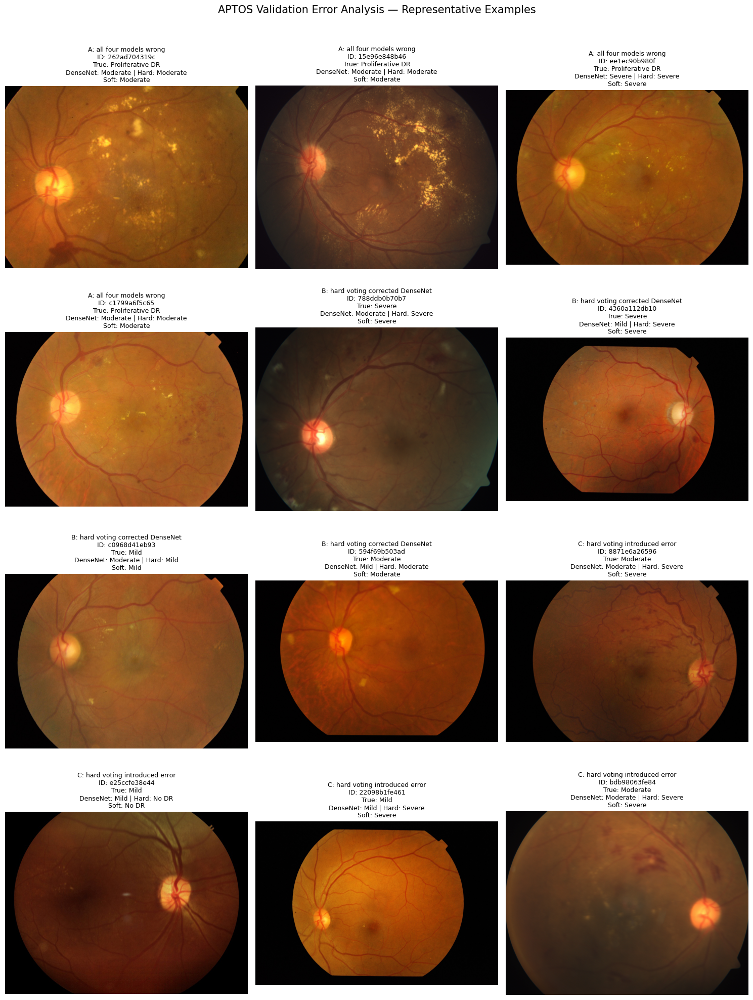

Representative images displayed: 12
Saved figure: /kaggle/working/DR_XAI_Project/results/ensemble_analysis/validation_error_analysis_grid.png
Groups included: A, B, C
Test set used: NO


In [17]:

from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

IMAGE_ROOT = Path(
    "/kaggle/input/competitions/aptos2019-blindness-detection/train_images"
)
OUTPUT_DIR = Path(
    "/kaggle/working/DR_XAI_Project/results/ensemble_analysis"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Use saved group CSVs from Cell 14
group_a = pd.read_csv(OUTPUT_DIR / "group_A_all_four_wrong.csv")
group_b = pd.read_csv(OUTPUT_DIR / "group_B_hard_voting_corrected.csv")
group_c = pd.read_csv(OUTPUT_DIR / "group_C_hard_voting_new_errors.csv")

CLASS_NAMES = [
    "No DR", "Mild", "Moderate", "Severe", "Proliferative DR"
]

# Select up to 4 examples from each group.
# Deterministic selection makes the report reproducible.
selected = []

for group_name, group_df in [
    ("A: all four models wrong", group_a),
    ("B: hard voting corrected DenseNet", group_b),
    ("C: hard voting introduced error", group_c),
]:
    sample = group_df.head(4)
    for _, row in sample.iterrows():
        selected.append((group_name, row))

n_cols = 3
n_rows = math.ceil(len(selected) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(15, 5 * n_rows)
)
axes = np.asarray(axes).reshape(-1)

for ax, (group_name, row) in zip(axes, selected):
    image_path = IMAGE_ROOT / f"{row['image_id']}.png"

    with Image.open(image_path) as image:
        image = image.convert("RGB")

    ax.imshow(image)
    ax.axis("off")

    true_grade = CLASS_NAMES[int(row["true_grade"])]
    dense_grade = CLASS_NAMES[int(row["densenet_prediction"])]
    hard_grade = CLASS_NAMES[int(row["hard_voting_prediction"])]
    soft_grade = CLASS_NAMES[int(row["soft_voting_prediction"])]

    title = (
        f"{group_name}\n"
        f"ID: {row['image_id']}\n"
        f"True: {true_grade}\n"
        f"DenseNet: {dense_grade} | Hard: {hard_grade}\n"
        f"Soft: {soft_grade}"
    )
    ax.set_title(title, fontsize=9)

for ax in axes[len(selected):]:
    ax.axis("off")

fig.suptitle(
    "APTOS Validation Error Analysis — Representative Examples",
    fontsize=15,
    y=1.01
)
fig.tight_layout()

figure_path = OUTPUT_DIR / "validation_error_analysis_grid.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Representative images displayed:", len(selected))
print("Saved figure:", figure_path)
print("Groups included: A, B, C")
print("Test set used: NO")


In [18]:

from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path(
    "/kaggle/working/DR_XAI_Project/results/ensemble_analysis"
)

group_a = pd.read_csv(OUTPUT_DIR / "group_A_all_four_wrong.csv")
group_b = pd.read_csv(OUTPUT_DIR / "group_B_hard_voting_corrected.csv")
group_c = pd.read_csv(OUTPUT_DIR / "group_C_hard_voting_new_errors.csv")

# Case 1: all four models wrong, true grade is Proliferative DR (4)
case1 = group_a[group_a["true_grade"] == 4]

# Case 2: hard voting corrects DenseNet, true grade is Severe (3)
case2 = group_b[group_b["true_grade"] == 3]

# Case 3: DenseNet correct, hard voting wrong, true grade Moderate (2)
case3 = group_c[
    (group_c["true_grade"] == 2)
    & (group_c["densenet_prediction"] == 2)
]

cases = [
    ("A_all_models_wrong_Proliferative", case1),
    ("B_hard_voting_corrects_Severe", case2),
    ("C_hard_voting_hurts_Moderate", case3),
]

selected_cases = []

print("=" * 75)
print("GRAD-CAM CASE SELECTION")
print("=" * 75)

for case_name, candidates in cases:
    if candidates.empty:
        print(f"\nNo candidate found for: {case_name}")
        continue

    row = candidates.iloc[0]
    selected_cases.append((case_name, row))

    print(f"\nCase: {case_name}")
    print("Image ID:", row["image_id"])
    print("True grade:", row["true_grade_name"])
    print("DenseNet prediction:", row["densenet_prediction"])
    print("Hard voting prediction:", row["hard_voting_prediction"])
    print("Soft voting prediction:", row["soft_voting_prediction"])

print("\nSelected cases:", len(selected_cases))
print("Test set used: NO")


GRAD-CAM CASE SELECTION

Case: A_all_models_wrong_Proliferative
Image ID: 262ad704319c
True grade: Proliferative_DR
DenseNet prediction: 2
Hard voting prediction: 2
Soft voting prediction: 2

Case: B_hard_voting_corrects_Severe
Image ID: 788ddb0b70b7
True grade: Severe
DenseNet prediction: 2
Hard voting prediction: 3
Soft voting prediction: 3

Case: C_hard_voting_hurts_Moderate
Image ID: 8871e6a26596
True grade: Moderate
DenseNet prediction: 2
Hard voting prediction: 3
Soft voting prediction: 3

Selected cases: 3
Test set used: NO


In [20]:

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None

        self.forward_hook = target_layer.register_forward_hook(
            self._save_activations
        )
        self.backward_hook = target_layer.register_full_backward_hook(
            self._save_gradients
        )

    def _save_activations(self, module, inputs, output):
        self.activations = output.detach()

    def _save_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor, class_idx=None):
        self.model.eval()
        self.model.zero_grad(set_to_none=True)
        self.activations = None
        self.gradients = None

        # Enable gradients for Grad-CAM even if inference mode was used elsewhere.
        with torch.enable_grad():
            logits = self.model(input_tensor)

            if class_idx is None:
                class_idx = int(logits.argmax(dim=1).item())

            score = logits[:, class_idx].sum()
            score.backward()

        if self.activations is None or self.gradients is None:
            raise RuntimeError("Grad-CAM hooks did not capture features and gradients.")

        # Global-average-pool the gradients to obtain channel weights.
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)

        # Weighted sum of feature maps, followed by ReLU.
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = F.relu(cam)

        cam = F.interpolate(
            cam,
            size=input_tensor.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        cam = cam[0, 0]
        cam_min = cam.min()
        cam_max = cam.max()

        if (cam_max - cam_min).item() > 1e-8:
            cam = (cam - cam_min) / (cam_max - cam_min)
        else:
            cam = torch.zeros_like(cam)

        return cam.detach().cpu().numpy()

    def remove_hooks(self):
        self.forward_hook.remove()
        self.backward_hook.remove()


print("GradCAM class defined successfully.")

# Confirm that the DenseNet121 target layer is available.
check_model = models.densenet121(weights=None)
target_layer = check_model.features.denseblock4

print("Target layer:", target_layer.__class__.__name__)
print("Target layer verified:", target_layer is not None)

del check_model


GradCAM class defined successfully.
Target layer: _DenseBlock
Target layer verified: True


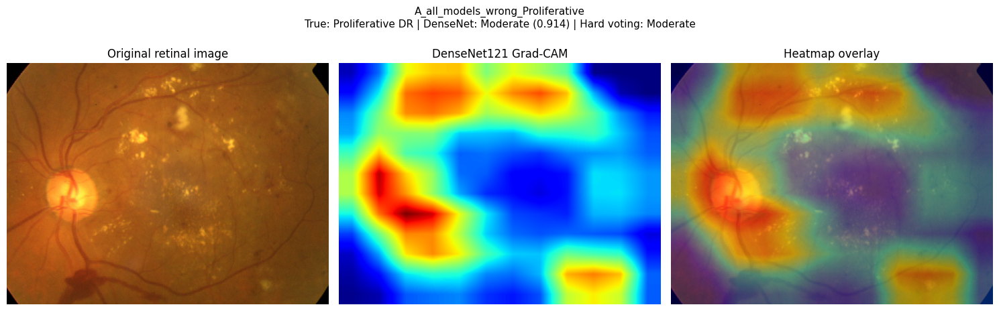

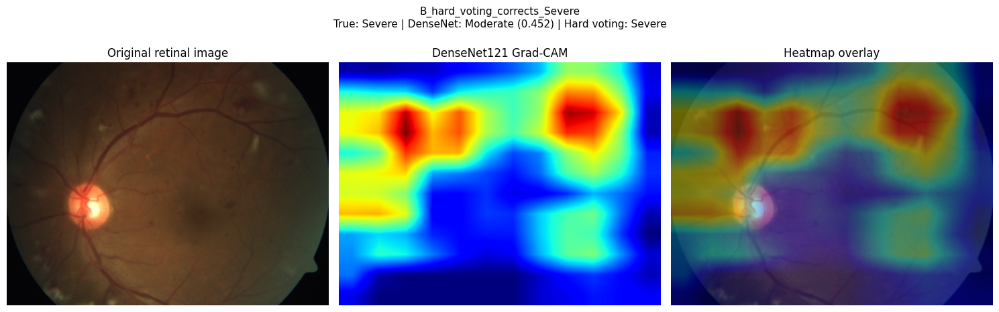

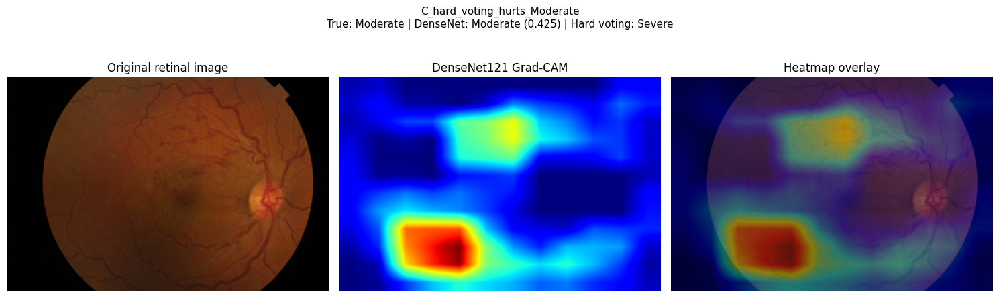

GRAD-CAM GENERATION COMPLETE
                            case     image_id  true_grade  hard_prediction  densenet_prediction  densenet_confidence  true_grade_probability                                                                                                 figure_path
A_all_models_wrong_Proliferative 262ad704319c           4                2                    2             0.914492                0.035278 /kaggle/working/DR_XAI_Project/results/ensemble_analysis/gradcam_cases/A_all_models_wrong_Proliferative.png
   B_hard_voting_corrects_Severe 788ddb0b70b7           3                3                    2             0.452263                0.352268    /kaggle/working/DR_XAI_Project/results/ensemble_analysis/gradcam_cases/B_hard_voting_corrects_Severe.png
    C_hard_voting_hurts_Moderate 8871e6a26596           2                3                    2             0.425263                0.425263     /kaggle/working/DR_XAI_Project/results/ensemble_analysis/gradcam_cases/C_hard_v

In [24]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn as nn
from torchvision import models
from PIL import Image

# Paths
IMAGE_ROOT = Path(
    "/kaggle/input/competitions/aptos2019-blindness-detection/train_images"
)
CHECKPOINT_PATH = Path(
    "/kaggle/input/datasets/dharshini2362005/"
    "dr-xai-improved-experiment/checkpoints/densenet121/best_model.pt"
)
OUTPUT_DIR = Path(
    "/kaggle/working/DR_XAI_Project/results/ensemble_analysis/gradcam_cases"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "No DR", "Mild", "Moderate", "Severe", "Proliferative DR"
]

CASES = [
    {
        "case": "A_all_models_wrong_Proliferative",
        "image_id": "262ad704319c",
        "true_grade": 4,
        "hard_prediction": 2
    },
    {
        "case": "B_hard_voting_corrects_Severe",
        "image_id": "788ddb0b70b7",
        "true_grade": 3,
        "hard_prediction": 3
    },
    {
        "case": "C_hard_voting_hurts_Moderate",
        "image_id": "8871e6a26596",
        "true_grade": 2,
        "hard_prediction": 3
    }
]

# Load the original trained DenseNet121
checkpoint = torch.load(
    CHECKPOINT_PATH, map_location="cpu", weights_only=False
)

gradcam_model = models.densenet121(weights=None)
gradcam_model.classifier = nn.Linear(
    gradcam_model.classifier.in_features, 5
)
gradcam_model.load_state_dict(checkpoint["model_state"], strict=True)
gradcam_model = gradcam_model.to(DEVICE).eval()

cam_generator = GradCAM(
    gradcam_model,
    gradcam_model.features.denseblock4
)

metadata_rows = []

for case in CASES:
    image_id = case["image_id"]
    image_path = IMAGE_ROOT / f"{image_id}.png"

    with Image.open(image_path) as image:
        original = image.convert("RGB")

    # Use the recovered original evaluation transform.
    input_tensor = AdvancedFundusTransform(train=False)(original)
    input_tensor = input_tensor.unsqueeze(0).to(DEVICE)

    # Prediction probabilities; gradient is computed separately by Grad-CAM.
    with torch.no_grad():
        logits = gradcam_model(input_tensor)
        probabilities = torch.softmax(logits, dim=1)[0].cpu().numpy()

    predicted_class = int(probabilities.argmax())
    confidence = float(probabilities[predicted_class])

    # Generate a map for DenseNet121's predicted class.
    heatmap = cam_generator.generate(
        input_tensor,
        class_idx=predicted_class
    )

    heatmap = np.squeeze(np.asarray(heatmap, dtype=np.float32))
    if heatmap.ndim != 2:
        raise ValueError(
            f"Unexpected heatmap shape for {image_id}: {heatmap.shape}"
        )

    heatmap = np.clip(heatmap, 0, 1)
    original_array = np.array(original)

    heatmap_resized = cv2.resize(
        heatmap,
        (original_array.shape[1], original_array.shape[0])
    )

    colored_heatmap = cv2.applyColorMap(
        np.uint8(255 * heatmap_resized),
        cv2.COLORMAP_JET
    )
    colored_heatmap = cv2.cvtColor(
        colored_heatmap, cv2.COLOR_BGR2RGB
    )

    overlay = cv2.addWeighted(
        original_array, 0.60,
        colored_heatmap, 0.40,
        0
    )

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(original_array)
    axes[0].set_title("Original retinal image")

    axes[1].imshow(heatmap_resized, cmap="jet", vmin=0, vmax=1)
    axes[1].set_title("DenseNet121 Grad-CAM")

    axes[2].imshow(overlay)
    axes[2].set_title("Heatmap overlay")

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        f"{case['case']}\n"
        f"True: {CLASS_NAMES[case['true_grade']]} | "
        f"DenseNet: {CLASS_NAMES[predicted_class]} ({confidence:.3f}) | "
        f"Hard voting: {CLASS_NAMES[case['hard_prediction']]}",
        fontsize=11
    )
    fig.tight_layout()

    figure_path = OUTPUT_DIR / f"{case['case']}.png"
    fig.savefig(figure_path, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    metadata_rows.append({
        **case,
        "densenet_prediction": predicted_class,
        "densenet_confidence": confidence,
        "true_grade_probability": float(
            probabilities[case["true_grade"]]
        ),
        "figure_path": str(figure_path)
    })

cam_generator.remove_hooks()

metadata_df = pd.DataFrame(metadata_rows)
metadata_df.to_csv(
    OUTPUT_DIR / "gradcam_case_metadata.csv",
    index=False
)

print("=" * 70)
print("GRAD-CAM GENERATION COMPLETE")
print("=" * 70)
print(metadata_df.to_string(index=False))
print("\nOutput folder:", OUTPUT_DIR)
print("Training performed: NO")
print("Test set used: NO")


In [25]:

from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path(
    "/kaggle/working/DR_XAI_Project/results/ensemble_analysis/gradcam_cases"
)

expected_files = [
    "A_all_models_wrong_Proliferative.png",
    "B_hard_voting_corrects_Severe.png",
    "C_hard_voting_hurts_Moderate.png",
    "gradcam_case_metadata.csv"
]

print("=" * 70)
print("GRAD-CAM ARTIFACT VERIFICATION")
print("=" * 70)

all_valid = True

for filename in expected_files:
    path = OUTPUT_DIR / filename
    exists = path.exists()
    size = path.stat().st_size if exists else 0
    valid = exists and size > 0
    all_valid = all_valid and valid

    print(f"\nFile: {filename}")
    print("Exists:", exists)
    print("Size (bytes):", size)
    print("Valid:", valid)

metadata_path = OUTPUT_DIR / "gradcam_case_metadata.csv"

if metadata_path.exists():
    metadata = pd.read_csv(metadata_path)
    print("\nMetadata rows:", len(metadata))
    print("Metadata columns:", metadata.columns.tolist())

print("\nALL ARTIFACTS VALID:", all_valid)


GRAD-CAM ARTIFACT VERIFICATION

File: A_all_models_wrong_Proliferative.png
Exists: True
Size (bytes): 1450033
Valid: True

File: B_hard_voting_corrects_Severe.png
Exists: True
Size (bytes): 1496554
Valid: True

File: C_hard_voting_hurts_Moderate.png
Exists: True
Size (bytes): 1182523
Valid: True

File: gradcam_case_metadata.csv
Exists: True
Size (bytes): 700
Valid: True

Metadata rows: 3
Metadata columns: ['case', 'image_id', 'true_grade', 'hard_prediction', 'densenet_prediction', 'densenet_confidence', 'true_grade_probability', 'figure_path']

ALL ARTIFACTS VALID: True


In [26]:

from pathlib import Path
import shutil
import zipfile

SOURCE_DIR = Path(
    "/kaggle/working/DR_XAI_Project/results/ensemble_analysis"
)
BUNDLE_DIR = Path(
    "/kaggle/working/DR_XAI_Project/exports/ensemble_gradcam_results"
)
ZIP_PATH = Path(
    "/kaggle/working/DR_XAI_Project/exports/"
    "ensemble_gradcam_results.zip"
)

BUNDLE_DIR.mkdir(parents=True, exist_ok=True)

# Copy the complete ensemble-analysis folder into the bundle.
for source in SOURCE_DIR.rglob("*"):
    if not source.is_file():
        continue

    relative_path = source.relative_to(SOURCE_DIR)
    destination = BUNDLE_DIR / relative_path
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, destination)

# Create a ZIP archive from the bundled files.
ZIP_PATH.parent.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for file_path in BUNDLE_DIR.rglob("*"):
        if file_path.is_file():
            archive.write(
                file_path,
                arcname=file_path.relative_to(BUNDLE_DIR)
            )

# Verify the archive contents.
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    bad_file = archive.testzip()
    archive_files = archive.namelist()

print("=" * 70)
print("RESEARCH RESULTS BUNDLE")
print("=" * 70)
print("Bundle folder:", BUNDLE_DIR)
print("ZIP archive:", ZIP_PATH)
print("Files included:", len(archive_files))
print("ZIP integrity check:", "PASSED" if bad_file is None else bad_file)
print("\nIncluded files:")
for name in archive_files:
    print("-", name)


RESEARCH RESULTS BUNDLE
Bundle folder: /kaggle/working/DR_XAI_Project/exports/ensemble_gradcam_results
ZIP archive: /kaggle/working/DR_XAI_Project/exports/ensemble_gradcam_results.zip
Files included: 11
ZIP integrity check: PASSED

Included files:
- validation_disagreement_records.csv
- validation_error_analysis_grid.png
- validation_error_analysis_all.csv
- per_grade_ensemble_changes.csv
- group_B_hard_voting_corrected.csv
- group_C_hard_voting_new_errors.csv
- group_A_all_four_wrong.csv
- gradcam_cases/C_hard_voting_hurts_Moderate.png
- gradcam_cases/A_all_models_wrong_Proliferative.png
- gradcam_cases/B_hard_voting_corrects_Severe.png
- gradcam_cases/gradcam_case_metadata.csv


In [29]:

from pathlib import Path
import zipfile

MOUNTED_ROOT = Path(
    "/kaggle/input/datasets/dharshini2362005/"
    "dr-xai-improved-experiment"
)
ZIP_PATH = Path(
    "/kaggle/working/DR_XAI_Project/exports/"
    "ensemble_gradcam_results.zip"
)
SOURCE_DIR = Path(
    "/kaggle/working/DR_XAI_Project/results/ensemble_analysis"
)

print("=" * 70)
print("EXISTING DATASET AND RESULTS INSPECTION")
print("=" * 70)

print("\n1. Mounted persistent dataset:")
print("Path exists:", MOUNTED_ROOT.exists())

if MOUNTED_ROOT.exists():
    for folder_name in ["checkpoints", "results", "docs"]:
        folder = MOUNTED_ROOT / folder_name
        print(f"\n{folder_name}/ exists:", folder.exists())
        if folder.exists():
            for item in sorted(folder.iterdir()):
                if item.is_dir():
                    print("  Folder:", item.name)
                else:
                    print(
                        "  File:",
                        item.name,
                        "|",
                        item.stat().st_size,
                        "bytes"
                    )

print("\n2. Original ensemble analysis source:")
print("Path exists:", SOURCE_DIR.exists())
if SOURCE_DIR.exists():
    source_files = [
        p for p in SOURCE_DIR.rglob("*") if p.is_file()
    ]
    print("File count:", len(source_files))
    for p in source_files:
        print(" ", p.relative_to(SOURCE_DIR))

print("\n3. ZIP archive contents:")
print("ZIP exists:", ZIP_PATH.exists())
if ZIP_PATH.exists():
    with zipfile.ZipFile(ZIP_PATH, "r") as archive:
        entries = archive.namelist()
        print("Archive entries:", len(entries))
        for name in entries:
            print(" ", name)

print("\nInspection complete. No files were changed.")


EXISTING DATASET AND RESULTS INSPECTION

1. Mounted persistent dataset:
Path exists: True

checkpoints/ exists: True
  Folder: densenet121
  Folder: efficientnet_b0
  Folder: mobilenet_v3_large
  Folder: resnet18

results/ exists: True
  Folder: densenet121
  Folder: efficientnet_b0
  Folder: gradcam_representative
  Folder: mobilenet_v3_large
  Folder: resnet18

docs/ exists: True
  File: GRADCAM_RESULTS.md | 1550 bytes

2. Original ensemble analysis source:
Path exists: True
File count: 11
  validation_disagreement_records.csv
  validation_error_analysis_grid.png
  validation_error_analysis_all.csv
  per_grade_ensemble_changes.csv
  group_B_hard_voting_corrected.csv
  group_C_hard_voting_new_errors.csv
  group_A_all_four_wrong.csv
  gradcam_cases/C_hard_voting_hurts_Moderate.png
  gradcam_cases/A_all_models_wrong_Proliferative.png
  gradcam_cases/B_hard_voting_corrects_Severe.png
  gradcam_cases/gradcam_case_metadata.csv

3. ZIP archive contents:
ZIP exists: True
Archive entries: 11


In [30]:

from pathlib import Path
import shutil
import hashlib
import json

# Existing persistent dataset (read-only input)
PERSISTENT_ROOT = Path(
    "/kaggle/input/datasets/dharshini2362005/dr-xai-improved-experiment"
)

# New writable staging directory
STAGING_ROOT = Path(
    "/kaggle/working/DR-XAI-Improved-Experiment-version"
)

# Newly generated analysis files
SOURCE_DIR = Path(
    "/kaggle/working/DR_XAI_Project/results/ensemble_analysis"
)

TARGET_DIR = STAGING_ROOT / "results" / "ensemble_analysis"

DATASET_ID = "dharshini2362005/dr-xai-improved-experiment"

print("=" * 70)
print("REBUILD STAGING AND BACK UP ENSEMBLE RESULTS")
print("=" * 70)

assert PERSISTENT_ROOT.exists(), "Persistent dataset is not mounted."
assert (PERSISTENT_ROOT / "checkpoints").exists(), "Checkpoints are missing."
assert (PERSISTENT_ROOT / "results").exists(), "Original results are missing."
assert SOURCE_DIR.exists(), "New ensemble results are missing."
assert not STAGING_ROOT.exists(), (
    "Staging directory already exists. Stop and inspect it before proceeding."
)

# Confirm the source files are present before copying.
source_files = sorted(
    p for p in SOURCE_DIR.rglob("*") if p.is_file()
)
assert len(source_files) == 11, (
    f"Expected 11 ensemble files, found {len(source_files)}."
)

# Reconstruct staging from the existing persistent dataset.
shutil.copytree(PERSISTENT_ROOT, STAGING_ROOT)

# Restore the metadata needed to publish a new version of the same dataset.
metadata_path = STAGING_ROOT / "dataset-metadata.json"
metadata = {
    "title": "DR-XAI-Improved-Experiment",
    "id": DATASET_ID,
    "licenses": [{"name": "CC0-1.0"}]
}
metadata_path.write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8"
)

# Ensure no existing files would be overwritten.
conflicts = [
    str(TARGET_DIR / p.relative_to(SOURCE_DIR))
    for p in source_files
    if (TARGET_DIR / p.relative_to(SOURCE_DIR)).exists()
]
assert not conflicts, (
    "Existing ensemble-result files found; stop to avoid overwriting them: "
    + ", ".join(conflicts)
)

# Add the new ensemble analysis.
TARGET_DIR.mkdir(parents=True, exist_ok=True)
for source in source_files:
    destination = TARGET_DIR / source.relative_to(SOURCE_DIR)
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, destination)

def sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

# Verify every newly copied file against its source.
verification = []
for source in source_files:
    destination = TARGET_DIR / source.relative_to(SOURCE_DIR)
    matches = (
        destination.exists()
        and source.stat().st_size == destination.stat().st_size
        and sha256(source) == sha256(destination)
    )
    verification.append(matches)
    print(
        ("PASS" if matches else "FAIL"),
        source.relative_to(SOURCE_DIR)
    )

# Verify all original checkpoint files were preserved.
original_checkpoints = sorted(
    p for p in (PERSISTENT_ROOT / "checkpoints").rglob("*")
    if p.is_file()
)
staged_checkpoints = [
    STAGING_ROOT / p.relative_to(PERSISTENT_ROOT)
    for p in original_checkpoints
]

checkpoint_checks = [
    p.exists()
    and p.stat().st_size == original.stat().st_size
    and sha256(p) == sha256(original)
    for original, p in zip(original_checkpoints, staged_checkpoints)
]

print("\n" + "=" * 70)
print("VERIFICATION SUMMARY")
print("=" * 70)
print("Original checkpoint files:", len(original_checkpoints))
print("Checkpoint files preserved:", sum(checkpoint_checks))
print("New analysis files:", len(source_files))
print("Analysis files verified:", sum(verification))
print("Dataset metadata ID:", json.loads(
    metadata_path.read_text(encoding="utf-8")
)["id"])
print("Staging directory:", STAGING_ROOT)

assert all(verification), "Some ensemble files failed hash verification."
assert all(checkpoint_checks), "Some original checkpoints changed or are missing."
assert json.loads(metadata_path.read_text())["id"] == DATASET_ID

print("\nSUCCESS: Staging is ready for review. Nothing has been published yet.")


REBUILD STAGING AND BACK UP ENSEMBLE RESULTS
PASS gradcam_cases/A_all_models_wrong_Proliferative.png
PASS gradcam_cases/B_hard_voting_corrects_Severe.png
PASS gradcam_cases/C_hard_voting_hurts_Moderate.png
PASS gradcam_cases/gradcam_case_metadata.csv
PASS group_A_all_four_wrong.csv
PASS group_B_hard_voting_corrected.csv
PASS group_C_hard_voting_new_errors.csv
PASS per_grade_ensemble_changes.csv
PASS validation_disagreement_records.csv
PASS validation_error_analysis_all.csv
PASS validation_error_analysis_grid.png

VERIFICATION SUMMARY
Original checkpoint files: 8
Checkpoint files preserved: 8
New analysis files: 11
Analysis files verified: 11
Dataset metadata ID: dharshini2362005/dr-xai-improved-experiment
Staging directory: /kaggle/working/DR-XAI-Improved-Experiment-version

SUCCESS: Staging is ready for review. Nothing has been published yet.


In [31]:

from pathlib import Path
import json

STAGING_ROOT = Path(
    "/kaggle/working/DR-XAI-Improved-Experiment-version"
)

metadata_path = STAGING_ROOT / "dataset-metadata.json"
analysis_dir = STAGING_ROOT / "results" / "ensemble_analysis"
checkpoint_dir = STAGING_ROOT / "checkpoints"

assert STAGING_ROOT.is_dir(), "Staging directory is missing."
assert metadata_path.is_file(), "Dataset metadata is missing."
assert checkpoint_dir.is_dir(), "Checkpoint directory is missing."
assert analysis_dir.is_dir(), "Ensemble-analysis directory is missing."

metadata = json.loads(metadata_path.read_text(encoding="utf-8"))

assert metadata["id"] == (
    "dharshini2362005/dr-xai-improved-experiment"
), "Dataset ID mismatch."

analysis_files = sorted(
    p for p in analysis_dir.rglob("*") if p.is_file()
)
checkpoint_files = sorted(
    p for p in checkpoint_dir.rglob("*") if p.is_file()
)

assert len(analysis_files) == 11, (
    f"Expected 11 analysis files; found {len(analysis_files)}"
)
assert len(checkpoint_files) == 8, (
    f"Expected 8 checkpoint files; found {len(checkpoint_files)}"
)

print("PRE-PUBLICATION AUDIT PASSED")
print("Dataset:", metadata["id"])
print("Checkpoint files:", len(checkpoint_files))
print("Ensemble-analysis files:", len(analysis_files))
print("Staging root:", STAGING_ROOT)
print("Ready for final review before publishing.")


PRE-PUBLICATION AUDIT PASSED
Dataset: dharshini2362005/dr-xai-improved-experiment
Checkpoint files: 8
Ensemble-analysis files: 11
Staging root: /kaggle/working/DR-XAI-Improved-Experiment-version
Ready for final review before publishing.


In [32]:

!kaggle datasets version \
  -p /kaggle/working/DR-XAI-Improved-Experiment-version \
  -m "Add verified ensemble analysis and Grad-CAM results" \
  --dir-mode tar


Starting upload for file checkpoints.tar
100%|█████████████████████████████████████████| 607M/607M [00:05<00:00, 125MB/s]
Upload successful: checkpoints.tar (607MB)
Starting upload for file docs.tar
100%|██████████████████████████████████████| 10.0k/10.0k [00:00<00:00, 15.5kB/s]
Upload successful: docs.tar (10KB)
Starting upload for file results.tar
100%|██████████████████████████████████████| 17.7M/17.7M [00:00<00:00, 35.8MB/s]
Upload successful: results.tar (18MB)
Starting upload for file experiment_manifest.json
100%|██████████████████████████████████████████| 590/590 [00:00<00:00, 1.41kB/s]
Upload successful: experiment_manifest.json (590B)
Dataset version is being created. Please check progress at https://www.kaggle.com/datasets/dharshini2362005/dr-xai-improved-experiment
